<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/SIMULASI%20PEMBANGKITAN%20DATA%20SPASIAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GRID 10 x 10

## PEMBANGKITAN DATA SIMULASI (N=100)

PEMBANGKITAN DATA GRID10
Grid Size      : 10 x 10
Jumlah lokasi : 100

Jumlah lokasi per zona:


,count
Error_Zone,
A,50
B,50


,ID,X_coord,Y_coord,X_norm,Y_norm,Grid_Size,N,Error_Zone
0,1,1,1,0.000000,0.0,10,100,A
1,2,2,1,0.111111,0.0,10,100,A
2,3,3,1,0.222222,0.0,10,100,A
3,4,4,1,0.333333,0.0,10,100,A
4,5,5,1,0.444444,0.0,10,100,A


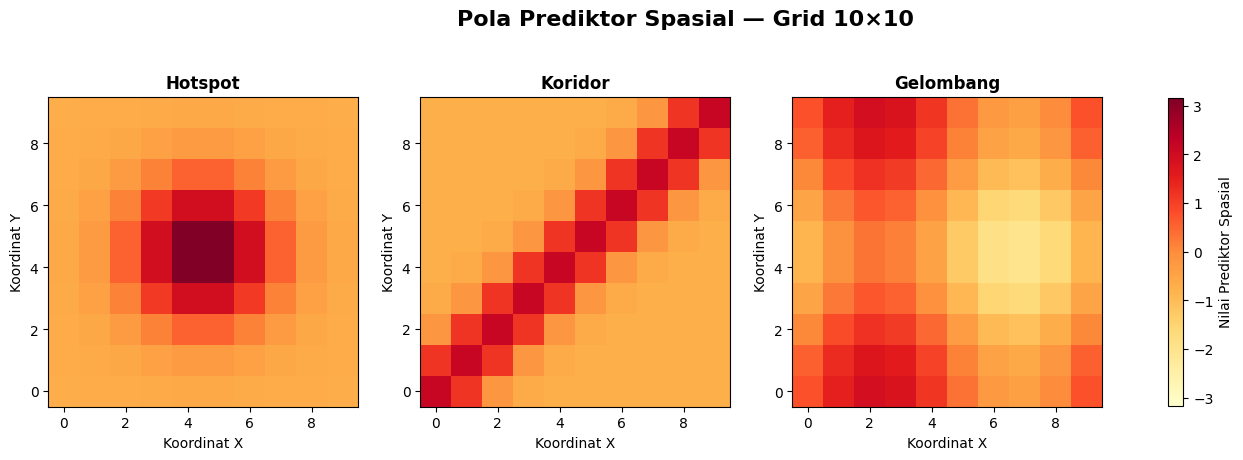



HASIL PEMBANGKITAN DATA GRID 10×10
Grid              : 10 x 10
N                 : 100
Jumlah skenario   : 54
Jumlah baris data : 5400
Lokasi/skenario   : 100


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Mean_Y,SD_Y,Moran_I_Y
0,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,0.220863,3.223504,0.485873
1,10,100,G10_HOTSPOT_KNN5_WEAK_HETEROGENEOUS,Hotspot,KNN-5,Weak,0.2,Heterogeneous,0.173801,3.186284,0.490273
2,10,100,G10_HOTSPOT_KNN5_MODERATE_HOMOGENEOUS,Hotspot,KNN-5,Moderate,0.5,Homogeneous,0.371329,4.127199,0.636310
3,10,100,G10_HOTSPOT_KNN5_MODERATE_HETEROGENEOUS,Hotspot,KNN-5,Moderate,0.5,Heterogeneous,0.291666,4.086513,0.639640
4,10,100,G10_HOTSPOT_KNN5_STRONG_HOMOGENEOUS,Hotspot,KNN-5,Strong,0.8,Homogeneous,1.066765,6.672728,0.762387


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
0,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
1,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
2,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
4,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260



Jumlah kombinasi skenario = 54


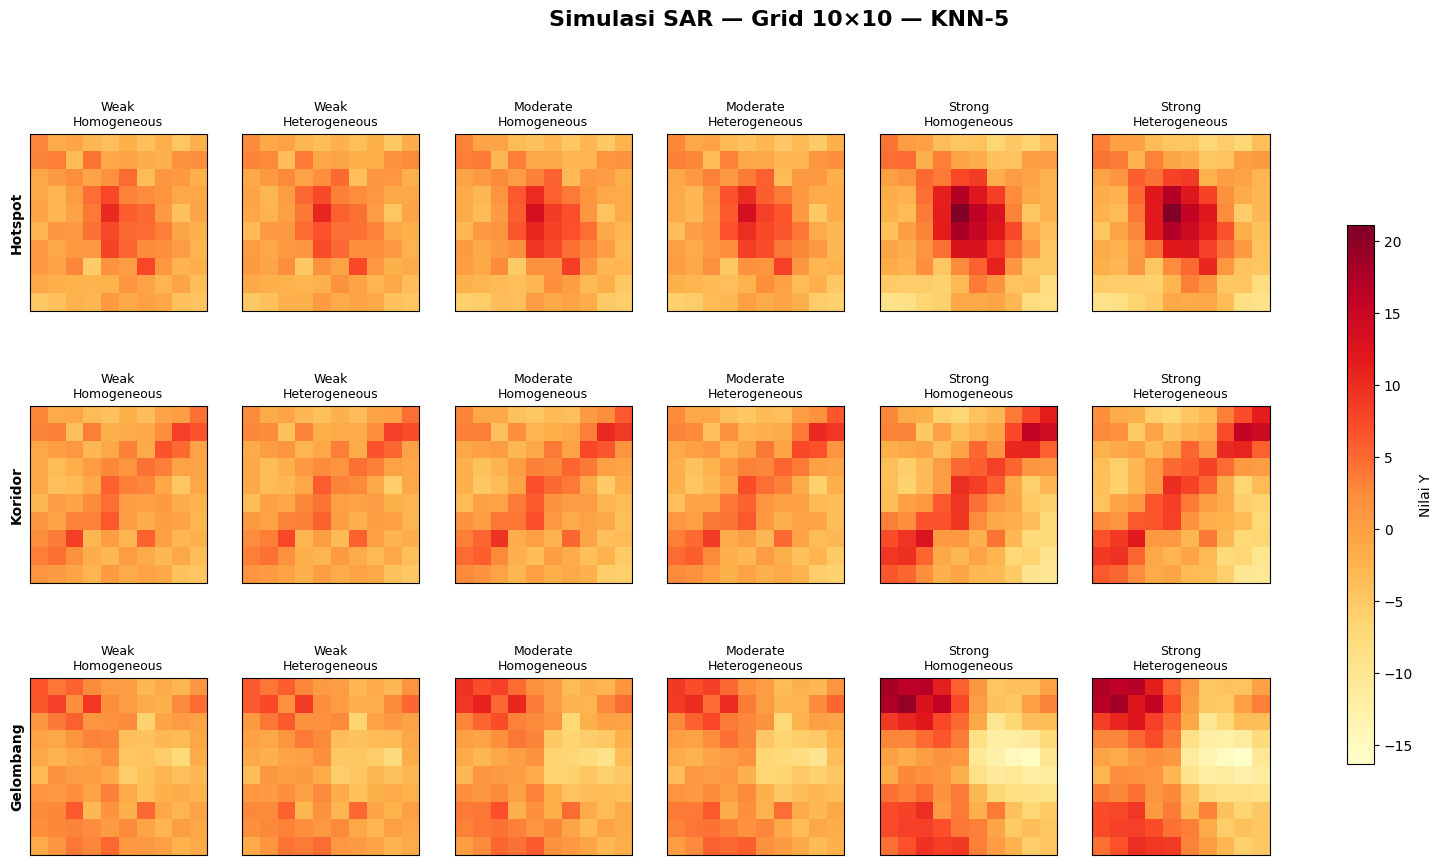

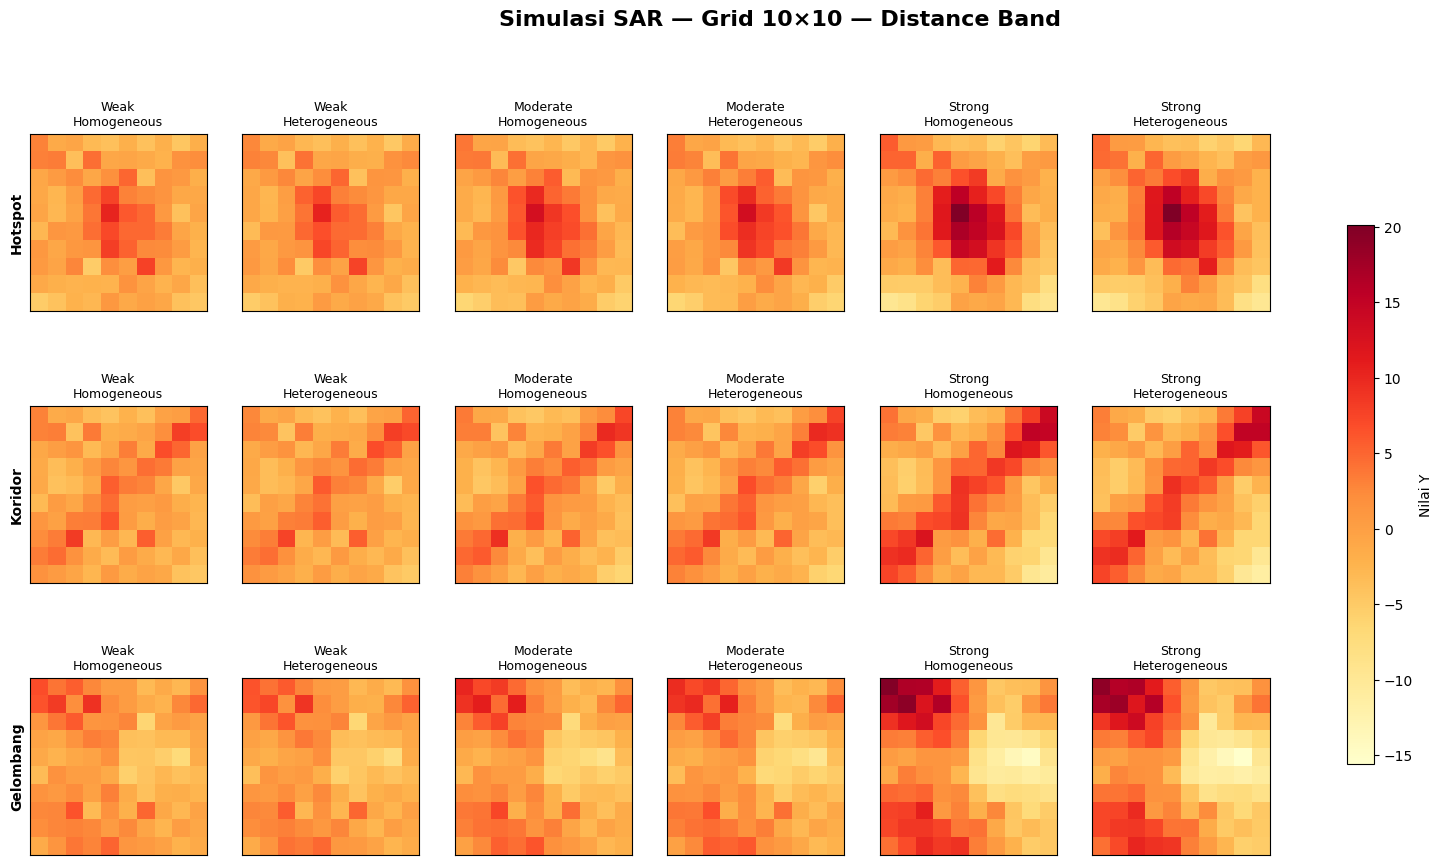

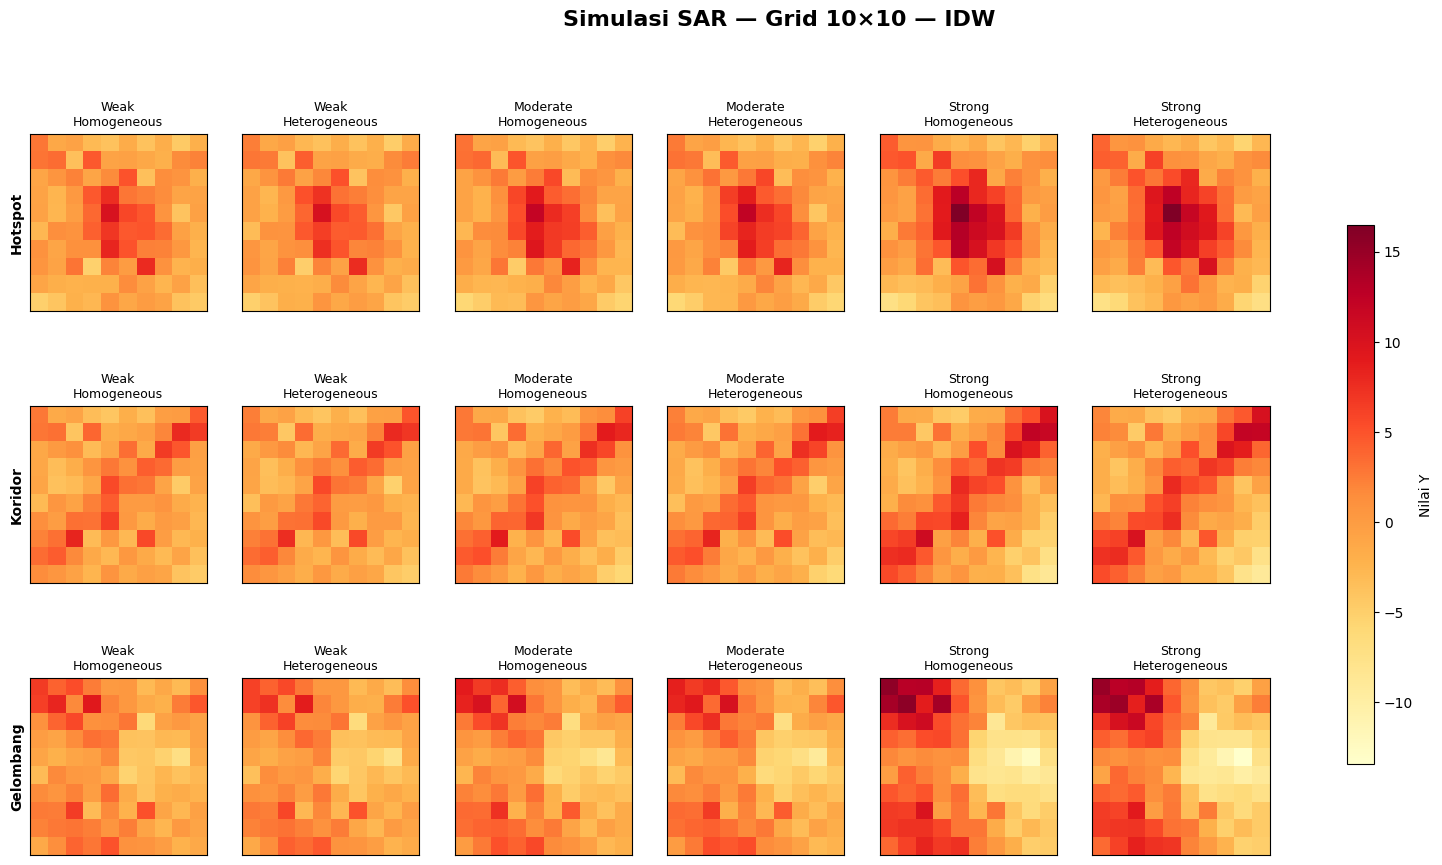



PEMBANGKITAN GRID 10×10 SELESAI
DATA_GRID10.csv
SUMMARY_GRID10.csv
W_KNN5_GRID10.npz
W_DISTANCE_GRID10.npz
W_IDW_GRID10.npz


In [12]:
# ============================================================
# ============================================================
# GRID 10 x 10
# CELL 1 — PEMBANGKITAN DATA SIMULASI
# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix, eye, save_npz
from scipy.sparse.linalg import factorized


# ============================================================
# 1. PENGATURAN GRID
# ============================================================

GRID_SIZE = 10
GRID_LABEL = "GRID10"

N = GRID_SIZE * GRID_SIZE


print("=" * 80)
print(f"PEMBANGKITAN DATA {GRID_LABEL}")
print("=" * 80)

print("Grid Size      :", GRID_SIZE, "x", GRID_SIZE)
print("Jumlah lokasi :", N)


# ============================================================
# 2. MEMBENTUK GRID SPASIAL
# ============================================================

x_coord = np.arange(
    1,
    GRID_SIZE + 1
)

y_coord = np.arange(
    1,
    GRID_SIZE + 1
)


xx, yy = np.meshgrid(
    x_coord,
    y_coord
)


grid = pd.DataFrame({

    "ID":
        np.arange(
            1,
            N + 1
        ),

    "X_coord":
        xx.ravel(),

    "Y_coord":
        yy.ravel()

})


# ============================================================
# 3. NORMALISASI KOORDINAT KE [0,1]
# ============================================================

grid["X_norm"] = (

    grid["X_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Y_norm"] = (

    grid["Y_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Grid_Size"] = GRID_SIZE
grid["N"] = N


# ============================================================
# 4. MEMBENTUK ZONA ERROR
# ============================================================
#
# Zona A = bagian kiri
# Zona B = bagian kanan
#
# ============================================================

grid["Error_Zone"] = np.where(

    grid["X_norm"] <= 0.5,

    "A",

    "B"

)


print("\nJumlah lokasi per zona:")

display(
    grid["Error_Zone"].value_counts()
)


display(
    grid.head()
)


# ============================================================
# 5. FUNGSI STANDARDISASI POLA
# ============================================================

def standardize_pattern(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return (

        values
        -
        np.mean(values)

    ) / np.std(values)


# ============================================================
# 6. MEMBENTUK POLA SPASIAL
# ============================================================

x = grid["X_norm"].values
y = grid["Y_norm"].values


# ============================================================
# 6.1 HOTSPOT / POLA TERPUSAT
# ============================================================

TAU_H = 0.18


hotspot_raw = np.exp(

    -(

        (x - 0.5) ** 2

        +

        (y - 0.5) ** 2

    )

    /

    (
        2 * TAU_H ** 2
    )

)


hotspot = standardize_pattern(
    hotspot_raw
)


# ============================================================
# 6.2 KORIDOR
# ============================================================

TAU_C = 0.12


corridor_raw = np.exp(

    -(

        np.abs(
            y - x
        ) ** 2

    )

    /

    (
        2 * TAU_C ** 2
    )

)


corridor = standardize_pattern(
    corridor_raw
)


# ============================================================
# 6.3 GELOMBANG
# ============================================================

wave_raw = (

    np.sin(
        2 * np.pi * x
    )

    +

    0.7
    *
    np.cos(
        2 * np.pi * y
    )

)


wave = standardize_pattern(
    wave_raw
)


PATTERN_DICT = {

    "Hotspot":
        hotspot,

    "Koridor":
        corridor,

    "Gelombang":
        wave

}


# ============================================================
# 7. FUNGSI MEMBENTUK MATRIKS PLOT
# ============================================================

def pattern_to_matrix(values):

    temp = grid[
        [
            "X_coord",
            "Y_coord"
        ]
    ].copy()

    temp["value"] = values

    return temp.pivot(

        index="Y_coord",

        columns="X_coord",

        values="value"

    )


# ============================================================
# 8. VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(
    list(
        PATTERN_DICT.values()
    )
)


pattern_limit = np.max(
    np.abs(
        all_pattern_values
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):

    matrix = pattern_to_matrix(
        pattern_values
    )


    im = ax.imshow(

        matrix,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(
        pattern_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Koordinat X"
    )

    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Pola Prediktor Spasial — Grid 10×10",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# 9. MEMBANGKITKAN 19 PREDIKTOR RANDOM
# ============================================================

SEED_X = 2026


rng_X = np.random.default_rng(
    SEED_X
)


X_random = rng_X.normal(

    loc=0,

    scale=1,

    size=(
        N,
        19
    )

)


X_columns = [

    f"X{i}"

    for i in range(
        1,
        20
    )

]


X_df = pd.DataFrame(

    X_random,

    columns=X_columns

)


# ============================================================
# 10. FUNGSI NONLINEAR NON-SPASIAL
# ============================================================
#
# 2 sin(X1)
# + 0.5 X2^2
# + X3 X4
# + X5
#
# ============================================================

non_spatial_signal = (

    2
    *
    np.sin(
        X_df["X1"].values
    )

    +

    0.5
    *
    (
        X_df["X2"].values ** 2
    )

    +

    (
        X_df["X3"].values

        *

        X_df["X4"].values
    )

    +

    X_df["X5"].values

)


# ============================================================
# 11. MEMBANGKITKAN ERROR DASAR
# ============================================================

SEED_ERROR = 2027


rng_error = np.random.default_rng(
    SEED_ERROR
)


z_error = rng_error.normal(

    loc=0,

    scale=1,

    size=N

)


# ============================================================
# 12. STRUKTUR VARIANS ERROR
# ============================================================

variance_homo = np.ones(
    N
)


variance_hetero = np.where(

    grid[
        "Error_Zone"
    ].values
    ==
    "A",

    0.5,

    1.5

)


# ============================================================
# HOMOSKEDASTIS
# ============================================================

error_homo = z_error.copy()


# ============================================================
# HETEROSKEDASTIS
# ============================================================

error_hetero = (

    np.sqrt(
        variance_hetero
    )

    *

    z_error

)


ERROR_DICT = {

    "Homogeneous":
        error_homo,

    "Heterogeneous":
        error_hetero

}


# ============================================================
# 13. KOORDINAT UNTUK W
# ============================================================

coordinates = grid[
    [
        "X_coord",
        "Y_coord"
    ]
].values


spatial_tree = cKDTree(
    coordinates
)


# ============================================================
# 14. FUNGSI ROW STANDARDIZATION
# ============================================================

def row_standardize_sparse(W):

    W = W.tocsr().astype(float)

    W.setdiag(0)

    W.eliminate_zeros()


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    if np.any(
        row_sum == 0
    ):

        raise ValueError(
            "Terdapat lokasi tanpa tetangga."
        )


    W_standardized = W.multiply(

        (
            1 / row_sum
        )[:, None]

    ).tocsr()


    return W_standardized


# ============================================================
# 15. W KNN-5
# ============================================================

K = 5


knn_distances, knn_indices = spatial_tree.query(

    coordinates,

    k=K + 1

)


knn_rows = np.repeat(

    np.arange(N),

    K

)


knn_cols = knn_indices[

    :,
    1:
].ravel()


knn_values = np.ones(
    len(
        knn_rows
    )
)


W_knn5_raw = csr_matrix(

    (

        knn_values,

        (
            knn_rows,
            knn_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_knn5 = row_standardize_sparse(
    W_knn5_raw
)


# ============================================================
# 16. W DISTANCE BAND
# ============================================================

DISTANCE_THRESHOLD = 1.5


distance_rows = []
distance_cols = []


distance_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=DISTANCE_THRESHOLD

)


for i, neighbors in enumerate(
    distance_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= DISTANCE_THRESHOLD
        ):

            distance_rows.append(i)

            distance_cols.append(j)


W_distance_raw = csr_matrix(

    (

        np.ones(
            len(
                distance_rows
            )
        ),

        (
            distance_rows,
            distance_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_distance = row_standardize_sparse(
    W_distance_raw
)


# ============================================================
# 17. W IDW
# ============================================================

IDW_RADIUS = 2.5
IDW_ALPHA = 1


idw_rows = []
idw_cols = []
idw_values = []


idw_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=IDW_RADIUS

)


for i, neighbors in enumerate(
    idw_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= IDW_RADIUS
        ):

            idw_rows.append(i)

            idw_cols.append(j)

            idw_values.append(

                1
                /
                (
                    distance_ij
                    **
                    IDW_ALPHA
                )

            )


W_idw_raw = csr_matrix(

    (

        idw_values,

        (
            idw_rows,
            idw_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_idw = row_standardize_sparse(
    W_idw_raw
)


# ============================================================
# DICTIONARY W
# ============================================================

W_RAW_DICT = {

    "KNN-5":
        W_knn5_raw,

    "Distance Band":
        W_distance_raw,

    "IDW":
        W_idw_raw

}


W_DICT = {

    "KNN-5":
        W_knn5,

    "Distance Band":
        W_distance,

    "IDW":
        W_idw

}


# ============================================================
# 18. PARAMETER RHO
# ============================================================

RHO_DICT = {

    "Weak":
        0.20,

    "Moderate":
        0.50,

    "Strong":
        0.80

}


# ============================================================
# 19. FUNGSI MORAN'S I
# ============================================================

def morans_I(
    values,
    W
):

    values = np.asarray(
        values,
        dtype=float
    )


    z = (

        values
        -
        np.mean(
            values
        )

    )


    n_obs = len(
        values
    )


    S0 = W.sum()


    numerator = (

        z

        @

        (
            W @ z
        )

    )


    denominator = (

        z

        @

        z

    )


    return float(

        (
            n_obs
            /
            S0
        )

        *

        (
            numerator
            /
            denominator
        )

    )


# ============================================================
# 20. MEMBUAT SOLVER SAR
#
# Y = (I - rho W)^(-1) [g(X) + e]
#
# Solver dibuat satu kali untuk setiap kombinasi W dan rho.
# ============================================================

SAR_SOLVER_DICT = {}


for W_name, W in W_DICT.items():


    for strength_name, rho in RHO_DICT.items():


        A = (

            eye(
                N,
                format="csc"
            )

            -

            rho
            *
            W.tocsc()

        )


        SAR_SOLVER_DICT[

            (
                W_name,
                strength_name
            )

        ] = factorized(
            A
        )


# ============================================================
# 21. MEMBANGKITKAN SELURUH 54 SKENARIO
# ============================================================

scenario_summary_rows = []

simulation_rows = []

Y_SCENARIOS = {}


for pattern_name, spatial_predictor in PATTERN_DICT.items():


    # --------------------------------------------------------
    # g(X)
    # --------------------------------------------------------

    g_X = (

        2
        *
        spatial_predictor

        +

        non_spatial_signal

    )


    for W_name, W in W_DICT.items():


        for strength_name, rho in RHO_DICT.items():


            sar_solver = SAR_SOLVER_DICT[

                (
                    W_name,
                    strength_name
                )

            ]


            for error_name, error_values in ERROR_DICT.items():


                scenario_id = (

                    f"G{GRID_SIZE}_"

                    f"{pattern_name.upper()}_"

                    f"{W_name.upper().replace(' ', '_').replace('-', '')}_"

                    f"{strength_name.upper()}_"

                    f"{error_name.upper()}"

                )


                rhs = (

                    g_X

                    +

                    error_values

                )


                Y_values = sar_solver(
                    rhs
                )


                moran_y = morans_I(

                    Y_values,

                    W

                )


                # --------------------------------------------
                # SIMPAN Y
                # --------------------------------------------

                Y_SCENARIOS[
                    scenario_id
                ] = Y_values.copy()


                # --------------------------------------------
                # SUMMARY
                # --------------------------------------------

                scenario_summary_rows.append({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Mean_Y":
                        np.mean(
                            Y_values
                        ),

                    "SD_Y":
                        np.std(
                            Y_values,
                            ddof=1
                        ),

                    "Moran_I_Y":
                        moran_y

                })


                # --------------------------------------------
                # DATA LENGKAP
                # --------------------------------------------

                temp = pd.DataFrame({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Location_ID":
                        grid[
                            "ID"
                        ].values,

                    "X_coord":
                        grid[
                            "X_coord"
                        ].values,

                    "Y_coord":
                        grid[
                            "Y_coord"
                        ].values,

                    "X_norm":
                        grid[
                            "X_norm"
                        ].values,

                    "Y_norm":
                        grid[
                            "Y_norm"
                        ].values,

                    "Error_Zone":
                        grid[
                            "Error_Zone"
                        ].values,

                    "X_spatial":
                        spatial_predictor,

                    "Error":
                        error_values,

                    "g_X":
                        g_X,

                    "Y":
                        Y_values

                })


                # --------------------------------------------
                # MASUKKAN X1 - X19
                # --------------------------------------------

                for col in X_columns:

                    temp[
                        col
                    ] = X_df[
                        col
                    ].values


                simulation_rows.append(
                    temp
                )


# ============================================================
# 22. GABUNGKAN SELURUH SKENARIO
# ============================================================

scenario_summary = pd.DataFrame(

    scenario_summary_rows

)


simulation_long = pd.concat(

    simulation_rows,

    ignore_index=True

)


# ============================================================
# 23. OBJEK AKHIR KHUSUS GRID 10
# ============================================================

DATA_GRID10 = simulation_long.copy()

SUMMARY_GRID10 = scenario_summary.copy()


# ============================================================
# 24. CEK HASIL PEMBANGKITAN
# ============================================================

print("\n")
print("=" * 80)
print("HASIL PEMBANGKITAN DATA GRID 10×10")
print("=" * 80)


print(
    "Grid              :",
    GRID_SIZE,
    "x",
    GRID_SIZE
)

print(
    "N                 :",
    N
)

print(
    "Jumlah skenario   :",
    DATA_GRID10[
        "Scenario_ID"
    ].nunique()
)

print(
    "Jumlah baris data :",
    len(
        DATA_GRID10
    )
)

print(
    "Lokasi/skenario   :",
    DATA_GRID10[
        "Location_ID"
    ].nunique()
)


print("=" * 80)


display(
    SUMMARY_GRID10.head()
)


display(
    DATA_GRID10.head()
)


# ============================================================
# 25. CEK 54 SKENARIO
# ============================================================

jumlah_skenario = (

    DATA_GRID10[

        [
            "Pattern",
            "W_Method",
            "Strength",
            "Rho",
            "Error_Structure"
        ]

    ]

    .drop_duplicates()

    .shape[0]

)


print(
    "\nJumlah kombinasi skenario =",
    jumlah_skenario
)


# ============================================================
# 26. VISUALISASI Y
#
# Satu gambar untuk setiap W
#
# Baris:
# Hotspot / Koridor / Gelombang
#
# Kolom:
# Weak-Homo
# Weak-Hetero
# Moderate-Homo
# Moderate-Hetero
# Strong-Homo
# Strong-Hetero
# ============================================================

pattern_order = [

    "Hotspot",
    "Koridor",
    "Gelombang"

]


column_order = [

    ("Weak", "Homogeneous"),

    ("Weak", "Heterogeneous"),

    ("Moderate", "Homogeneous"),

    ("Moderate", "Heterogeneous"),

    ("Strong", "Homogeneous"),

    ("Strong", "Heterogeneous")

]


for W_name in W_DICT.keys():


    subset_W = DATA_GRID10[

        DATA_GRID10[
            "W_Method"
        ]
        ==
        W_name

    ]


    Y_min = subset_W[
        "Y"
    ].min()


    Y_max = subset_W[
        "Y"
    ].max()


    fig, axes = plt.subplots(

        3,
        6,

        figsize=(20, 10)

    )


    for row_index, pattern_name in enumerate(
        pattern_order
    ):


        for col_index, (
            strength_name,
            error_name
        ) in enumerate(
            column_order
        ):


            temp = subset_W[

                (
                    subset_W[
                        "Pattern"
                    ]
                    ==
                    pattern_name
                )

                &

                (
                    subset_W[
                        "Strength"
                    ]
                    ==
                    strength_name
                )

                &

                (
                    subset_W[
                        "Error_Structure"
                    ]
                    ==
                    error_name
                )

            ]


            matrix_Y = temp.pivot(

                index="Y_coord",

                columns="X_coord",

                values="Y"

            )


            im = axes[
                row_index,
                col_index
            ].imshow(

                matrix_Y,

                origin="lower",

                cmap="YlOrRd",

                vmin=Y_min,

                vmax=Y_max,

                aspect="equal"

            )


            axes[
                row_index,
                col_index
            ].set_title(

                f"{strength_name}\n"
                f"{error_name}",

                fontsize=9

            )


            if col_index == 0:

                axes[
                    row_index,
                    col_index
                ].set_ylabel(

                    pattern_name,

                    fontweight="bold"

                )


            axes[
                row_index,
                col_index
            ].set_xticks([])


            axes[
                row_index,
                col_index
            ].set_yticks([])


    fig.colorbar(

        im,

        ax=axes.ravel().tolist(),

        label="Nilai Y",

        shrink=0.7

    )


    fig.suptitle(

        f"Simulasi SAR — Grid 10×10 — {W_name}",

        fontsize=16,

        fontweight="bold"

    )


    plt.show()


# ============================================================
# 27. SIMPAN DATA GRID 10
# ============================================================

DATA_GRID10.to_csv(

    "DATA_GRID10.csv",

    index=False

)


SUMMARY_GRID10.to_csv(

    "SUMMARY_GRID10.csv",

    index=False

)


# ============================================================
# 28. SIMPAN MATRIKS W
#
# Disimpan format sparse .npz
# agar tetap efisien sampai grid 50×50.
# ============================================================

save_npz(

    "W_KNN5_GRID10.npz",

    W_knn5

)


save_npz(

    "W_DISTANCE_GRID10.npz",

    W_distance

)


save_npz(

    "W_IDW_GRID10.npz",

    W_idw

)


print("\n")
print("=" * 80)
print("PEMBANGKITAN GRID 10×10 SELESAI")
print("=" * 80)

print("DATA_GRID10.csv")
print("SUMMARY_GRID10.csv")
print("W_KNN5_GRID10.npz")
print("W_DISTANCE_GRID10.npz")
print("W_IDW_GRID10.npz")

print("=" * 80)

## VALIDASI DATA SIMULASI

VALIDASI DATA SIMULASI SPASIAL — GRID 10×10


1. VALIDASI WEAK - MODERATE - STRONG


,Grid_Size,Strength,Rho,Mean_Moran_I,SD_Moran_I,Min_Moran_I,Max_Moran_I,N_Scenario
2,10,Weak,0.2,0.4298,0.0913,0.2500,0.5453,18
0,10,Moderate,0.5,0.5756,0.1087,0.3689,0.7198,18
1,10,Strong,0.8,0.7307,0.1076,0.5532,0.8712,18


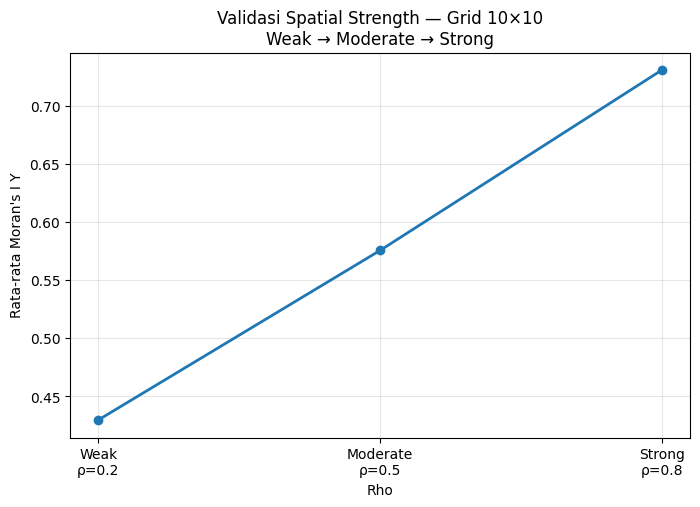


Apakah Mean Moran's I meningkat Weak < Moderate < Strong ?
True


2. MORAN'S I POLA SPASIAL


,Grid_Size,Pattern,W_Method,Moran_I_Pattern
0,10,Hotspot,KNN-5,0.8177
1,10,Hotspot,Distance Band,0.7961
2,10,Hotspot,IDW,0.6432
3,10,Koridor,KNN-5,0.6827
4,10,Koridor,Distance Band,0.6722
5,10,Koridor,IDW,0.4882
6,10,Gelombang,KNN-5,0.8444
7,10,Gelombang,Distance Band,0.8264
8,10,Gelombang,IDW,0.7109



RINGKASAN MORAN'S I POLA


,Grid_Size,Pattern,Mean_Moran_I,Min_Moran_I,Max_Moran_I
0,10,Gelombang,0.7939,0.7109,0.8444
1,10,Hotspot,0.7523,0.6432,0.8177
2,10,Koridor,0.6143,0.4882,0.6827


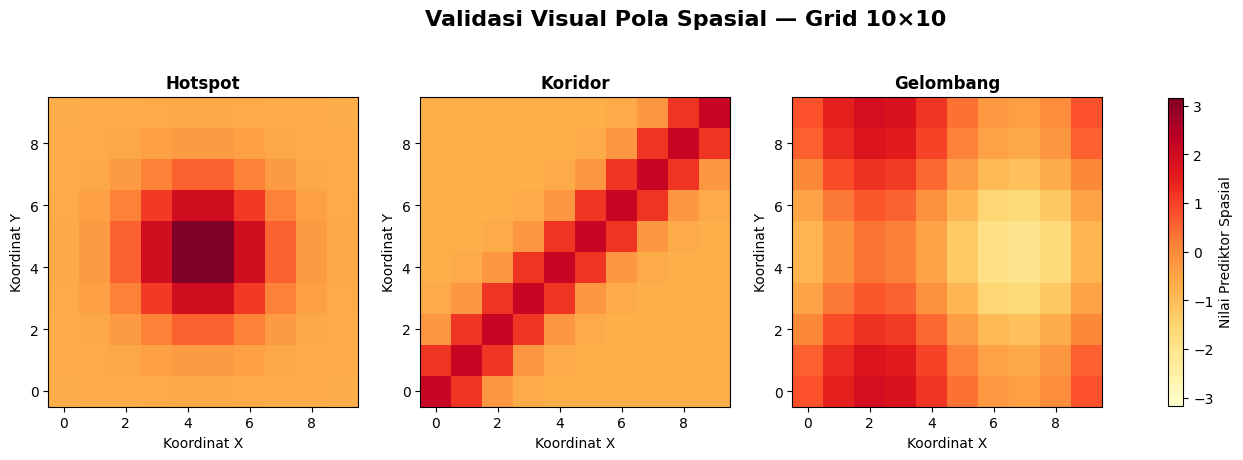



3. UJI BREUSCH-PAGAN
H0 : Varians error konstan
H1 : Varians error tidak konstan
Alpha = 0.05


,Grid_Size,Error_Structure,LM_Statistic,LM_pvalue,F_Statistic,F_pvalue,Conclusion
0,10,Homogeneous,0.529984,0.466614,0.522152,0.471646,Tidak terdeteksi heteroskedastisitas
1,10,Heterogeneous,8.890972,0.002866,9.563435,0.002586,Heteroskedastis




VARIANS ERROR PER ZONA


,Grid_Size,Zone,N,Mean_Error_Homo,Variance_Homogeneous,Mean_Error_Hetero,Variance_Heterogeneous
0,10,A,50,0.0402,1.2477,0.0284,0.6239
1,10,B,50,-0.2724,0.9498,-0.3337,1.4247


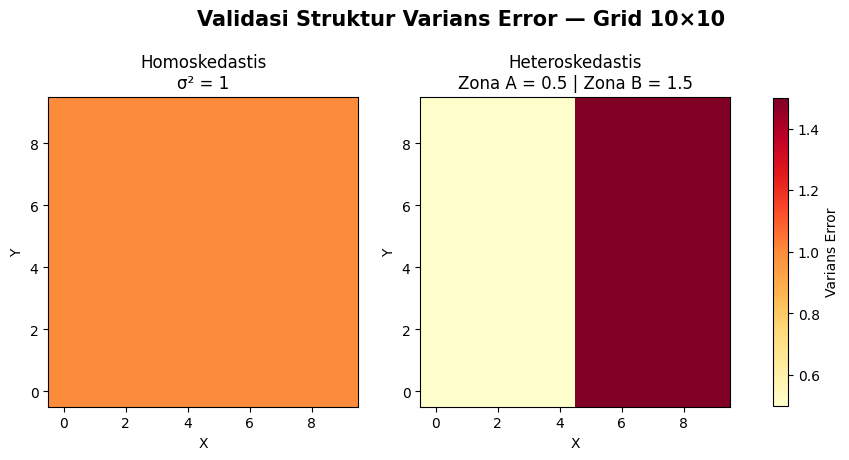



4. VALIDASI MATRIKS BOBOT W


,Grid_Size,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Min_Positive_Weight,Mean_Positive_Weight,Max_Positive_Weight,Min_Row_Sum,Max_Row_Sum,No_Self_Neighbor,Symmetric
0,10,KNN-5,5,5.00,5,0.200,0.2000,0.2000,1.0,1.0,True,False
1,10,Distance Band,3,6.84,8,0.125,0.1462,0.3333,1.0,1.0,True,False
2,10,IDW,7,15.80,20,0.036,0.0633,0.2173,1.0,1.0,True,False


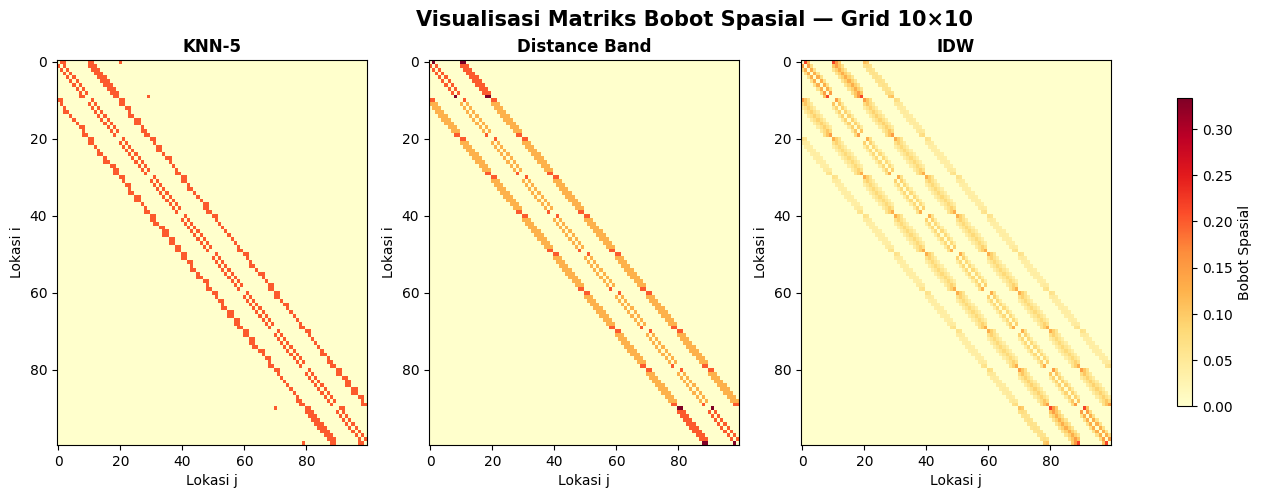

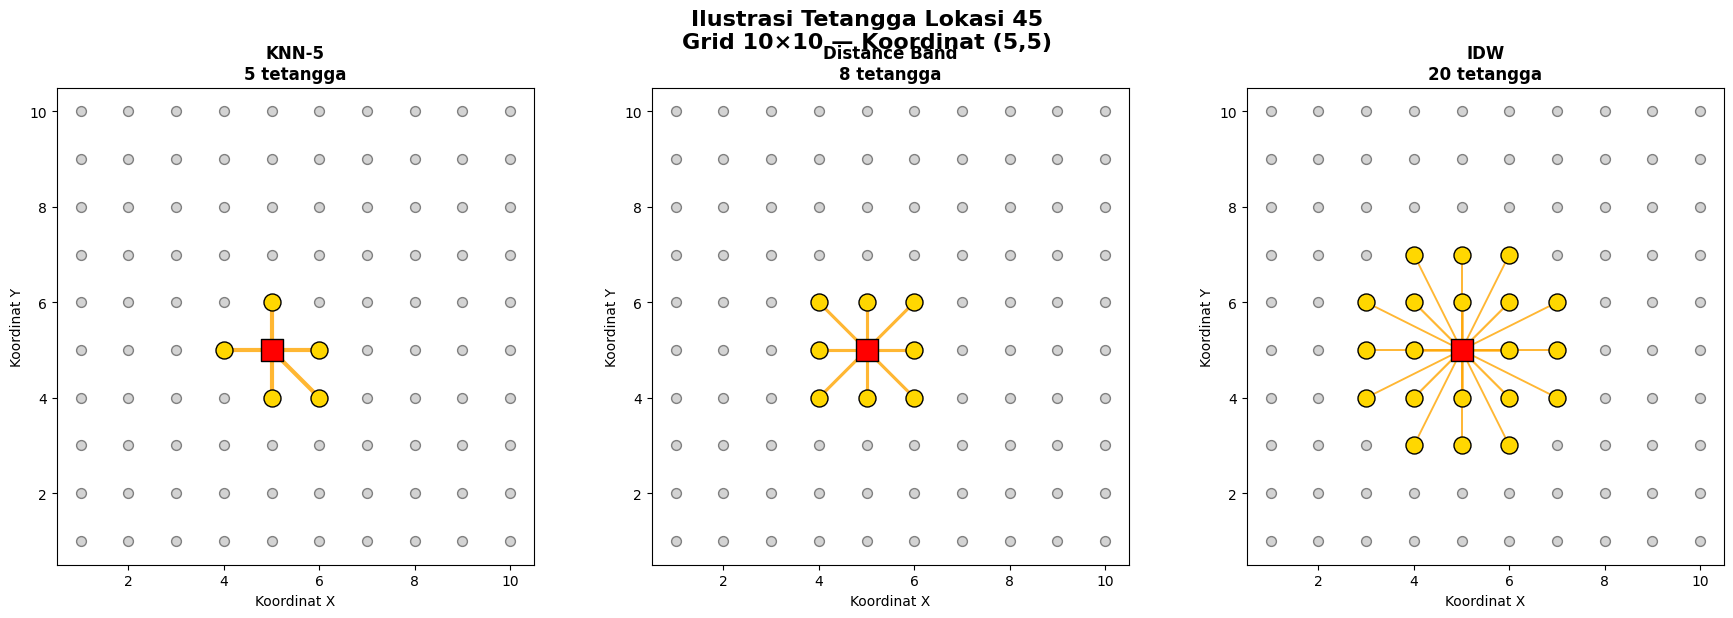



DETAIL TETANGGA LOKASI FOKUS


,Grid_Size,W_Method,Focus_ID,Neighbor_ID,Distance,Weight
6,10,Distance Band,45,35,1.0000,0.1250
8,10,Distance Band,45,44,1.0000,0.1250
9,10,Distance Band,45,46,1.0000,0.1250
11,10,Distance Band,45,55,1.0000,0.1250
5,10,Distance Band,45,34,1.4142,0.1250
7,10,Distance Band,45,36,1.4142,0.1250
10,10,Distance Band,45,54,1.4142,0.1250
12,10,Distance Band,45,56,1.4142,0.1250
18,10,IDW,45,35,1.0000,0.0806
22,10,IDW,45,44,1.0000,0.0806




TABEL VALIDASI FINAL SIMULASI — GRID 10×10


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,10,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,10,Pola spasial,Plot pola + Moran's I pola,PASS
2,10,Homo / Heteroskedastis,Breusch-Pagan + varians per zona,PASS
3,10,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS




CEK OBJEK AKHIR GRID 10×10
DATA_GRID10                  : (5400, 37)
SUMMARY_GRID10               : (54, 11)
VALIDASI_GRID10              : (4, 4)
STRENGTH_VALIDATION_GRID10   : (3, 8)
PATTERN_VALIDATION_GRID10    : (9, 4)
BP_GRID10                    : (2, 7)
VARIANCE_GRID10              : (2, 7)
W_VALIDATION_GRID10          : (3, 12)
NEIGHBOR_GRID10              : (33, 6)

Jumlah skenario : 54
Jumlah baris    : 5400
✅ GRID 10×10: SEMUA VALIDASI PASS

FILE YANG TERSIMPAN:
DATA_GRID10.csv
SUMMARY_GRID10.csv
VALIDASI_FINAL_GRID10.csv
VALIDASI_STRENGTH_GRID10.csv
VALIDASI_POLA_GRID10.csv
RINGKASAN_POLA_GRID10.csv
VALIDASI_BREUSCH_PAGAN_GRID10.csv
VALIDASI_VARIANS_GRID10.csv
VALIDASI_W_GRID10.csv
DETAIL_TETANGGA_GRID10.csv
W_KNN5_GRID10.npz
W_DISTANCE_GRID10.npz
W_IDW_GRID10.npz


In [13]:
# ============================================================
# ============================================================
# GRID 10 x 10
# CELL 2 — VALIDASI DATA SIMULASI
#
# 1. Weak / Moderate / Strong
#       -> rho + Moran's I Y
#
# 2. Pola Hotspot / Koridor / Gelombang
#       -> plot pola + Moran's I pola
#
# 3. Homoskedastis / Heteroskedastis
#       -> Breusch-Pagan + varians per zona
#
# 4. KNN-5 / Distance Band / IDW
#       -> validasi W + statistik tetangga
# ============================================================
# ============================================================

import statsmodels.api as sm

from statsmodels.stats.diagnostic import het_breuschpagan


print("=" * 80)
print("VALIDASI DATA SIMULASI SPASIAL — GRID 10×10")
print("=" * 80)


# ============================================================
# ============================================================
# VALIDASI 1
# WEAK / MODERATE / STRONG
# ============================================================
# ============================================================

strength_validation = (

    SUMMARY_GRID10

    .groupby(
        [
            "Strength",
            "Rho"
        ]
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Y",
            "mean"
        ),

        SD_Moran_I=(
            "Moran_I_Y",
            "std"
        ),

        Min_Moran_I=(
            "Moran_I_Y",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Y",
            "max"
        ),

        N_Scenario=(
            "Moran_I_Y",
            "count"
        )

    )

    .reset_index()

)


strength_order = {

    "Weak": 1,

    "Moderate": 2,

    "Strong": 3

}


strength_validation["_order"] = (

    strength_validation[
        "Strength"
    ]

    .map(
        strength_order
    )

)


strength_validation = (

    strength_validation

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

)


strength_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("1. VALIDASI WEAK - MODERATE - STRONG")
print("=" * 80)


display(

    strength_validation.round(4)

)


# ============================================================
# PLOT STRENGTH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    strength_validation[
        "Rho"
    ],

    strength_validation[
        "Mean_Moran_I"
    ],

    marker="o",

    linewidth=2

)


plt.xlabel(
    "Rho"
)


plt.ylabel(
    "Rata-rata Moran's I Y"
)


plt.title(

    "Validasi Spatial Strength — Grid 10×10\n"
    "Weak → Moderate → Strong"

)


plt.xticks(

    [
        0.2,
        0.5,
        0.8
    ],

    [
        "Weak\nρ=0.2",
        "Moderate\nρ=0.5",
        "Strong\nρ=0.8"
    ]

)


plt.grid(
    alpha=0.3
)


plt.show()


# ============================================================
# CEK OTOMATIS STRENGTH
# ============================================================

mean_moran_weak = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Weak",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_moderate = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Moderate",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_strong = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Strong",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


strength_pass = (

    mean_moran_weak

    <

    mean_moran_moderate

    <

    mean_moran_strong

)


print(
    "\nApakah Mean Moran's I meningkat "
    "Weak < Moderate < Strong ?"
)


print(
    strength_pass
)


# ============================================================
# ============================================================
# VALIDASI 2
# POLA SPASIAL
# ============================================================
# ============================================================

pattern_moran_rows = []


for pattern_name, pattern_values in PATTERN_DICT.items():


    for W_name, W in W_DICT.items():


        I_pattern = morans_I(

            pattern_values,

            W

        )


        pattern_moran_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "Pattern":
                pattern_name,

            "W_Method":
                W_name,

            "Moran_I_Pattern":
                I_pattern

        })


pattern_moran_validation = pd.DataFrame(

    pattern_moran_rows

)


print("\n")
print("=" * 80)
print("2. MORAN'S I POLA SPASIAL")
print("=" * 80)


display(

    pattern_moran_validation.round(4)

)


# ============================================================
# RINGKASAN POLA
# ============================================================

pattern_summary_validation = (

    pattern_moran_validation

    .groupby(
        "Pattern"
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Pattern",
            "mean"
        ),

        Min_Moran_I=(
            "Moran_I_Pattern",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Pattern",
            "max"
        )

    )

    .reset_index()

)


pattern_summary_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print(
    "\nRINGKASAN MORAN'S I POLA"
)


display(

    pattern_summary_validation.round(4)

)


# ============================================================
# VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(

    list(
        PATTERN_DICT.values()
    )

)


pattern_limit = np.max(

    np.abs(
        all_pattern_values
    )

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):


    matrix_pattern = pattern_to_matrix(

        pattern_values

    )


    im = ax.imshow(

        matrix_pattern,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(

        pattern_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Validasi Visual Pola Spasial — Grid 10×10",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# ============================================================
# VALIDASI 3
# BREUSCH-PAGAN
# ============================================================
# ============================================================

zone_dummy = (

    grid[
        "Error_Zone"
    ]

    ==
    "B"

).astype(int)


X_BP = sm.add_constant(

    zone_dummy

)


def run_breusch_pagan(

    residuals,

    exog,

    structure_name

):


    bp_result = het_breuschpagan(

        residuals,

        exog

    )


    LM_stat = bp_result[0]

    LM_pvalue = bp_result[1]

    F_stat = bp_result[2]

    F_pvalue = bp_result[3]


    if LM_pvalue < 0.05:

        conclusion = (
            "Heteroskedastis"
        )

    else:

        conclusion = (
            "Tidak terdeteksi heteroskedastisitas"
        )


    return {

        "Grid_Size":
            GRID_SIZE,

        "Error_Structure":
            structure_name,

        "LM_Statistic":
            LM_stat,

        "LM_pvalue":
            LM_pvalue,

        "F_Statistic":
            F_stat,

        "F_pvalue":
            F_pvalue,

        "Conclusion":
            conclusion

    }


BP_homo = run_breusch_pagan(

    residuals=
        error_homo,

    exog=
        X_BP,

    structure_name=
        "Homogeneous"

)


BP_hetero = run_breusch_pagan(

    residuals=
        error_hetero,

    exog=
        X_BP,

    structure_name=
        "Heterogeneous"

)


BP_table = pd.DataFrame(

    [
        BP_homo,
        BP_hetero
    ]

)


print("\n")
print("=" * 80)
print("3. UJI BREUSCH-PAGAN")
print("=" * 80)


print(
    "H0 : Varians error konstan"
)

print(
    "H1 : Varians error tidak konstan"
)

print(
    "Alpha = 0.05"
)


display(

    BP_table.round(6)

)


# ============================================================
# VARIANS ERROR PER ZONA
# ============================================================

variance_check = pd.DataFrame({

    "Zone":
        grid[
            "Error_Zone"
        ],

    "Error_Homogeneous":
        error_homo,

    "Error_Heterogeneous":
        error_hetero

})


variance_zone_table = (

    variance_check

    .groupby(
        "Zone"
    )

    .agg(

        N=(
            "Error_Homogeneous",
            "count"
        ),

        Mean_Error_Homo=(
            "Error_Homogeneous",
            "mean"
        ),

        Variance_Homogeneous=(
            "Error_Homogeneous",
            "var"
        ),

        Mean_Error_Hetero=(
            "Error_Heterogeneous",
            "mean"
        ),

        Variance_Heterogeneous=(
            "Error_Heterogeneous",
            "var"
        )

    )

    .reset_index()

)


variance_zone_table.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("VARIANS ERROR PER ZONA")
print("=" * 80)


display(

    variance_zone_table.round(4)

)


# ============================================================
# VISUALISASI STRUKTUR VARIANS
# ============================================================

variance_homo_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_homo

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


variance_hetero_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_hetero

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


fig, axes = plt.subplots(

    1,
    2,

    figsize=(11, 5)

)


axes[0].imshow(

    variance_homo_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[0].set_title(

    "Homoskedastis\nσ² = 1"

)


axes[0].set_xlabel(
    "X"
)

axes[0].set_ylabel(
    "Y"
)


im2 = axes[1].imshow(

    variance_hetero_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[1].set_title(

    "Heteroskedastis\n"
    "Zona A = 0.5 | Zona B = 1.5"

)


axes[1].set_xlabel(
    "X"
)

axes[1].set_ylabel(
    "Y"
)


fig.colorbar(

    im2,

    ax=axes.ravel().tolist(),

    label="Varians Error",

    shrink=0.8

)


fig.suptitle(

    "Validasi Struktur Varians Error — Grid 10×10",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# ============================================================
# VALIDASI 4
# MATRIKS BOBOT W
# ============================================================
# ============================================================

W_validation_rows = []


for W_name, W in W_DICT.items():


    W_raw = W_RAW_DICT[
        W_name
    ].tocsr()


    W = W.tocsr()


    n_neighbors = np.diff(
        W_raw.indptr
    )


    positive_weights = W.data


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    diagonal_zero = np.allclose(

        W.diagonal(),

        0

    )


    W_difference = (

        W

        -

        W.T

    ).tocsr()


    if W_difference.nnz == 0:

        symmetric = True

    else:

        symmetric = (

            np.max(

                np.abs(
                    W_difference.data
                )

            )

            <

            1e-12

        )


    W_validation_rows.append({

        "Grid_Size":
            GRID_SIZE,

        "W_Method":
            W_name,

        "Min_Neighbor":
            np.min(
                n_neighbors
            ),

        "Mean_Neighbor":
            np.mean(
                n_neighbors
            ),

        "Max_Neighbor":
            np.max(
                n_neighbors
            ),

        "Min_Positive_Weight":
            np.min(
                positive_weights
            ),

        "Mean_Positive_Weight":
            np.mean(
                positive_weights
            ),

        "Max_Positive_Weight":
            np.max(
                positive_weights
            ),

        "Min_Row_Sum":
            np.min(
                row_sum
            ),

        "Max_Row_Sum":
            np.max(
                row_sum
            ),

        "No_Self_Neighbor":
            diagonal_zero,

        "Symmetric":
            symmetric

    })


W_validation_table = pd.DataFrame(

    W_validation_rows

)


print("\n")
print("=" * 80)
print("4. VALIDASI MATRIKS BOBOT W")
print("=" * 80)


display(

    W_validation_table.round(4)

)


# ============================================================
# HEATMAP W
# ============================================================

W_MAX = max(

    np.max(
        W.data
    )

    for W in W_DICT.values()

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    W_dense_plot = W.toarray()


    im = ax.imshow(

        W_dense_plot,

        cmap="YlOrRd",

        vmin=0,

        vmax=W_MAX,

        aspect="auto"

    )


    ax.set_title(

        W_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Lokasi j"
    )


    ax.set_ylabel(
        "Lokasi i"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Bobot Spasial",

    shrink=0.8

)


fig.suptitle(

    "Visualisasi Matriks Bobot Spasial — Grid 10×10",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# ILUSTRASI TETANGGA SATU LOKASI
# ============================================================

focus_x = GRID_SIZE // 2

focus_y = GRID_SIZE // 2


focus_idx = grid[

    (
        grid[
            "X_coord"
        ]
        ==
        focus_x
    )

    &

    (
        grid[
            "Y_coord"
        ]
        ==
        focus_y
    )

].index[0]


focus_id = int(

    grid.loc[
        focus_idx,
        "ID"
    ]

)


# ============================================================
# FUNGSI PLOT TETANGGA
# ============================================================

def plot_focus_neighbors(

    ax,

    W,

    method_name

):


    W_row = W.getrow(
        focus_idx
    )


    neighbors = W_row.indices


    ax.scatter(

        grid[
            "X_coord"
        ],

        grid[
            "Y_coord"
        ],

        s=50,

        color="lightgray",

        edgecolor="gray",

        zorder=1

    )


    for j in neighbors:


        weight = float(

            W[
                focus_idx,
                j
            ]

        )


        ax.plot(

            [
                grid.loc[
                    focus_idx,
                    "X_coord"
                ],

                grid.loc[
                    j,
                    "X_coord"
                ]
            ],

            [
                grid.loc[
                    focus_idx,
                    "Y_coord"
                ],

                grid.loc[
                    j,
                    "Y_coord"
                ]
            ],

            linewidth=

                1

                +

                10
                *
                weight,

            color="orange",

            alpha=0.8,

            zorder=2

        )


    ax.scatter(

        grid.loc[
            neighbors,
            "X_coord"
        ],

        grid.loc[
            neighbors,
            "Y_coord"
        ],

        s=150,

        color="gold",

        edgecolor="black",

        zorder=3

    )


    ax.scatter(

        grid.loc[
            focus_idx,
            "X_coord"
        ],

        grid.loc[
            focus_idx,
            "Y_coord"
        ],

        s=240,

        marker="s",

        color="red",

        edgecolor="black",

        zorder=4

    )


    ax.set_title(

        f"{method_name}\n"
        f"{len(neighbors)} tetangga",

        fontweight="bold"

    )


    ax.set_xlim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_ylim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


# ============================================================
# PLOT TETANGGA
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(18, 6)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    plot_focus_neighbors(

        ax,

        W,

        W_name

    )


fig.suptitle(

    f"Ilustrasi Tetangga Lokasi {focus_id}\n"
    f"Grid 10×10 — Koordinat ({focus_x},{focus_y})",

    fontsize=16,

    fontweight="bold"

)


plt.tight_layout()


plt.show()


# ============================================================
# DETAIL TETANGGA
# ============================================================

neighbor_rows = []


for W_name, W in W_DICT.items():


    neighbors = W.getrow(
        focus_idx
    ).indices


    for j in neighbors:


        distance_ij = np.linalg.norm(

            coordinates[
                focus_idx
            ]

            -

            coordinates[
                j
            ]

        )


        neighbor_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "W_Method":
                W_name,

            "Focus_ID":
                focus_id,

            "Neighbor_ID":
                int(
                    grid.loc[
                        j,
                        "ID"
                    ]
                ),

            "Distance":
                distance_ij,

            "Weight":
                float(
                    W[
                        focus_idx,
                        j
                    ]
                )

        })


neighbor_detail_table = pd.DataFrame(

    neighbor_rows

)


print("\n")
print("=" * 80)
print("DETAIL TETANGGA LOKASI FOKUS")
print("=" * 80)


display(

    neighbor_detail_table

    .sort_values(

        [
            "W_Method",
            "Distance",
            "Neighbor_ID"
        ]

    )

    .round(4)

)


# ============================================================
# ============================================================
# TABEL VALIDASI FINAL
# ============================================================
# ============================================================

homo_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Homogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


hetero_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Heterogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


bp_pass = (

    homo_pvalue >= 0.05

    and

    hetero_pvalue < 0.05

)


pattern_pass = np.all(

    pattern_moran_validation[
        "Moran_I_Pattern"
    ]

    >
    0

)


W_pass = (

    np.allclose(

        W_validation_table[
            "Min_Row_Sum"
        ].values,

        1

    )

    and

    np.allclose(

        W_validation_table[
            "Max_Row_Sum"
        ].values,

        1

    )

    and

    (
        W_validation_table[
            "Min_Neighbor"
        ].min()
        >
        0
    )

    and

    W_validation_table[
        "No_Self_Neighbor"
    ].all()

)


validation_final = pd.DataFrame({

    "Grid_Size": [

        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE

    ],

    "Komponen": [

        "Weak / Moderate / Strong",

        "Pola spasial",

        "Homo / Heteroskedastis",

        "Spatial Weight Matrix"

    ],

    "Alat_Validasi": [

        "rho + Moran's I Y",

        "Plot pola + Moran's I pola",

        "Breusch-Pagan + varians per zona",

        "Visualisasi W + statistik tetangga"

    ],

    "Hasil_Utama": [

        (
            "PASS"
            if strength_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if pattern_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if bp_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if W_pass
            else
            "CHECK"
        )

    ]

})


# ============================================================
# OBJEK AKHIR KHUSUS GRID 10
# ============================================================

VALIDASI_GRID10 = validation_final.copy()


STRENGTH_VALIDATION_GRID10 = (

    strength_validation.copy()

)


PATTERN_VALIDATION_GRID10 = (

    pattern_moran_validation.copy()

)


PATTERN_SUMMARY_GRID10 = (

    pattern_summary_validation.copy()

)


BP_GRID10 = (

    BP_table.copy()

)


VARIANCE_GRID10 = (

    variance_zone_table.copy()

)


W_VALIDATION_GRID10 = (

    W_validation_table.copy()

)


NEIGHBOR_GRID10 = (

    neighbor_detail_table.copy()

)


# ============================================================
# TAMPILKAN VALIDASI FINAL
# ============================================================

print("\n")
print("=" * 80)
print("TABEL VALIDASI FINAL SIMULASI — GRID 10×10")
print("=" * 80)


display(

    VALIDASI_GRID10

)


# ============================================================
# SIMPAN SEMUA HASIL VALIDASI
# ============================================================

VALIDASI_GRID10.to_csv(

    "VALIDASI_FINAL_GRID10.csv",

    index=False

)


STRENGTH_VALIDATION_GRID10.to_csv(

    "VALIDASI_STRENGTH_GRID10.csv",

    index=False

)


PATTERN_VALIDATION_GRID10.to_csv(

    "VALIDASI_POLA_GRID10.csv",

    index=False

)


PATTERN_SUMMARY_GRID10.to_csv(

    "RINGKASAN_POLA_GRID10.csv",

    index=False

)


BP_GRID10.to_csv(

    "VALIDASI_BREUSCH_PAGAN_GRID10.csv",

    index=False

)


VARIANCE_GRID10.to_csv(

    "VALIDASI_VARIANS_GRID10.csv",

    index=False

)


W_VALIDATION_GRID10.to_csv(

    "VALIDASI_W_GRID10.csv",

    index=False

)


NEIGHBOR_GRID10.to_csv(

    "DETAIL_TETANGGA_GRID10.csv",

    index=False

)


# ============================================================
# CEK AKHIR SEMUA OBJEK
# ============================================================

print("\n")
print("=" * 80)
print("CEK OBJEK AKHIR GRID 10×10")
print("=" * 80)


print(
    "DATA_GRID10                  :",
    DATA_GRID10.shape
)

print(
    "SUMMARY_GRID10               :",
    SUMMARY_GRID10.shape
)

print(
    "VALIDASI_GRID10              :",
    VALIDASI_GRID10.shape
)

print(
    "STRENGTH_VALIDATION_GRID10   :",
    STRENGTH_VALIDATION_GRID10.shape
)

print(
    "PATTERN_VALIDATION_GRID10    :",
    PATTERN_VALIDATION_GRID10.shape
)

print(
    "BP_GRID10                    :",
    BP_GRID10.shape
)

print(
    "VARIANCE_GRID10              :",
    VARIANCE_GRID10.shape
)

print(
    "W_VALIDATION_GRID10          :",
    W_VALIDATION_GRID10.shape
)

print(
    "NEIGHBOR_GRID10              :",
    NEIGHBOR_GRID10.shape
)


print("\nJumlah skenario :",

      DATA_GRID10[
          "Scenario_ID"
      ].nunique()

)


print(
    "Jumlah baris    :",
    len(
        DATA_GRID10
    )
)


print("=" * 80)


# ============================================================
# STATUS AKHIR
# ============================================================

if (

    VALIDASI_GRID10[
        "Hasil_Utama"
    ]

    ==
    "PASS"

).all():

    print(
        "✅ GRID 10×10: SEMUA VALIDASI PASS"
    )

else:

    print(
        "⚠️ GRID 10×10: ADA VALIDASI YANG PERLU DICEK"
    )


print("=" * 80)


print("\nFILE YANG TERSIMPAN:")

print("DATA_GRID10.csv")
print("SUMMARY_GRID10.csv")

print("VALIDASI_FINAL_GRID10.csv")
print("VALIDASI_STRENGTH_GRID10.csv")
print("VALIDASI_POLA_GRID10.csv")
print("RINGKASAN_POLA_GRID10.csv")
print("VALIDASI_BREUSCH_PAGAN_GRID10.csv")
print("VALIDASI_VARIANS_GRID10.csv")
print("VALIDASI_W_GRID10.csv")
print("DETAIL_TETANGGA_GRID10.csv")

print("W_KNN5_GRID10.npz")
print("W_DISTANCE_GRID10.npz")
print("W_IDW_GRID10.npz")

print("=" * 80)

# GRID 20 X 20

## PEMBANGKITAN DATA SIMULASI (N=400)

PEMBANGKITAN DATA GRID20
Grid Size      : 20 x 20
Jumlah lokasi : 400

Jumlah lokasi per zona:


,count
Error_Zone,
A,200
B,200


,ID,X_coord,Y_coord,X_norm,Y_norm,Grid_Size,N,Error_Zone
0,1,1,1,0.000000,0.0,20,400,A
1,2,2,1,0.052632,0.0,20,400,A
2,3,3,1,0.105263,0.0,20,400,A
3,4,4,1,0.157895,0.0,20,400,A
4,5,5,1,0.210526,0.0,20,400,A


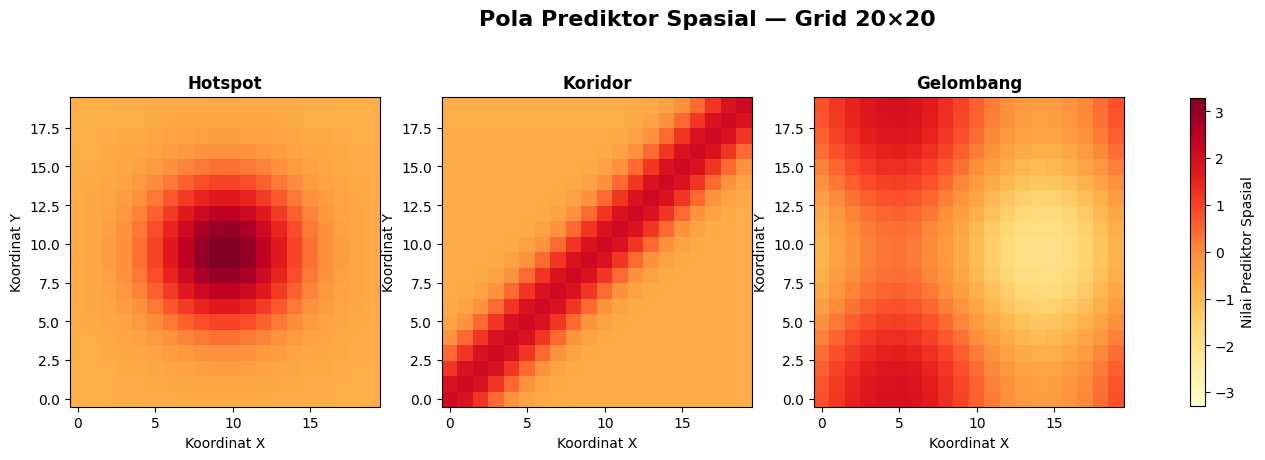



HASIL PEMBANGKITAN DATA GRID 20×20
Grid              : 20 x 20
N                 : 400
Jumlah skenario   : 54
Jumlah baris data : 21600
Lokasi/skenario   : 400


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Mean_Y,SD_Y,Moran_I_Y
0,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,0.586707,3.559043,0.624737
1,20,400,G20_HOTSPOT_KNN5_WEAK_HETEROGENEOUS,Hotspot,KNN-5,Weak,0.2,Heterogeneous,0.578008,3.549200,0.628448
2,20,400,G20_HOTSPOT_KNN5_MODERATE_HOMOGENEOUS,Hotspot,KNN-5,Moderate,0.5,Homogeneous,0.945750,4.966332,0.797960
3,20,400,G20_HOTSPOT_KNN5_MODERATE_HETEROGENEOUS,Hotspot,KNN-5,Moderate,0.5,Heterogeneous,0.933053,4.960258,0.800659
4,20,400,G20_HOTSPOT_KNN5_STRONG_HOMOGENEOUS,Hotspot,KNN-5,Strong,0.8,Homogeneous,2.383331,10.396462,0.926264


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
0,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
1,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
2,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
4,20,400,G20_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260



Jumlah kombinasi skenario = 54


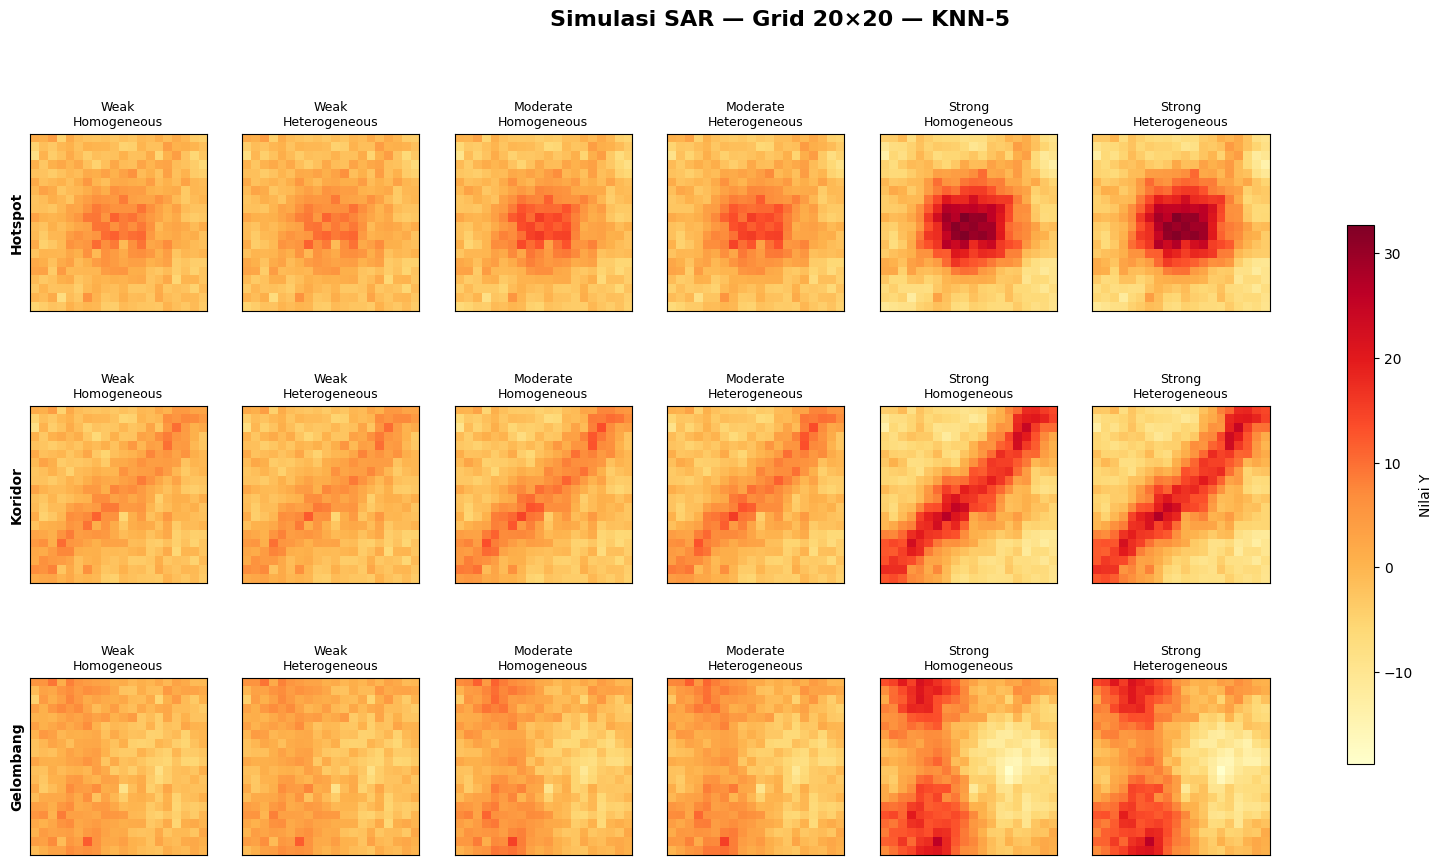

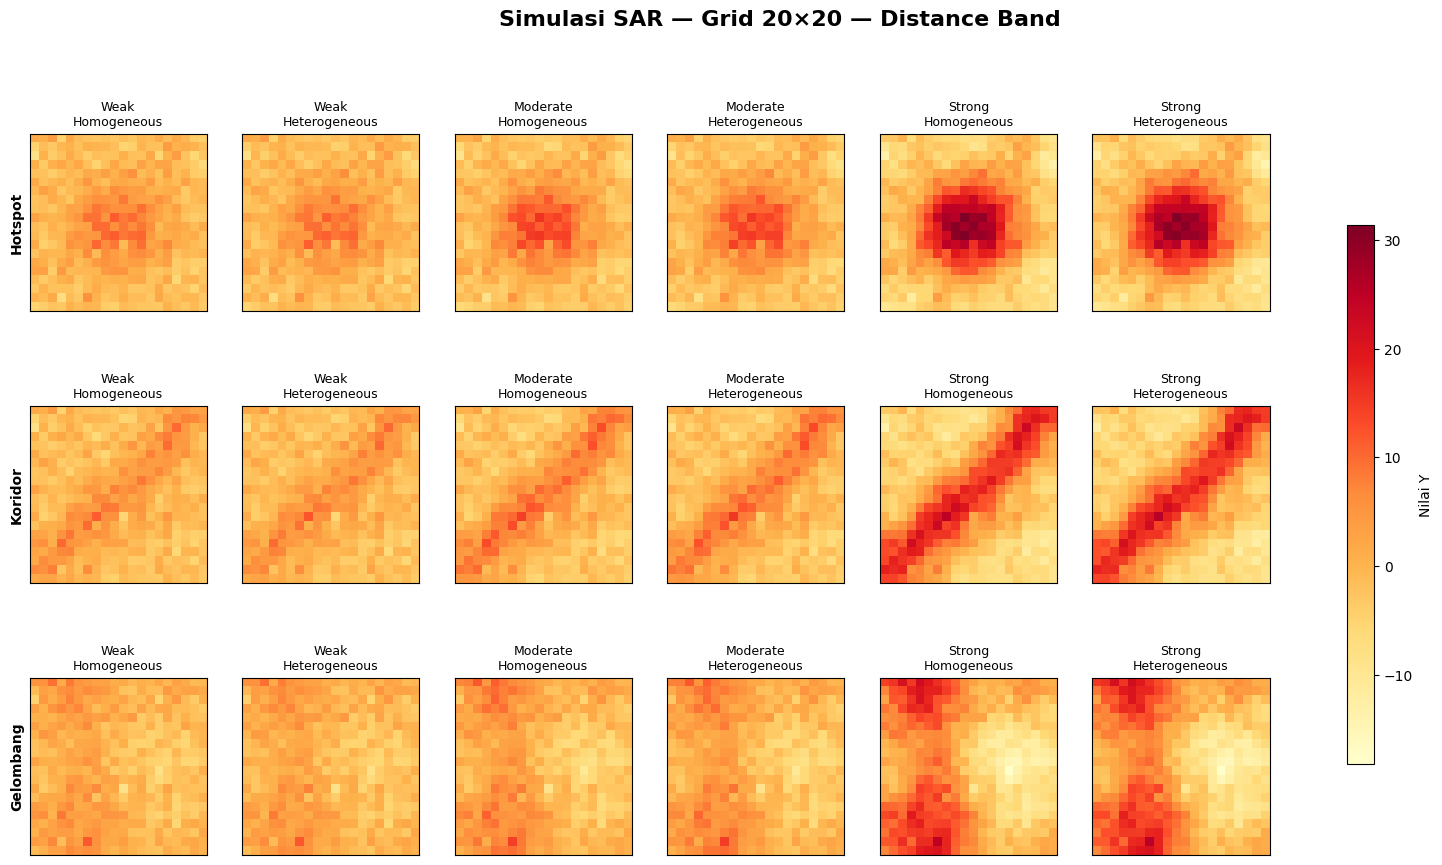

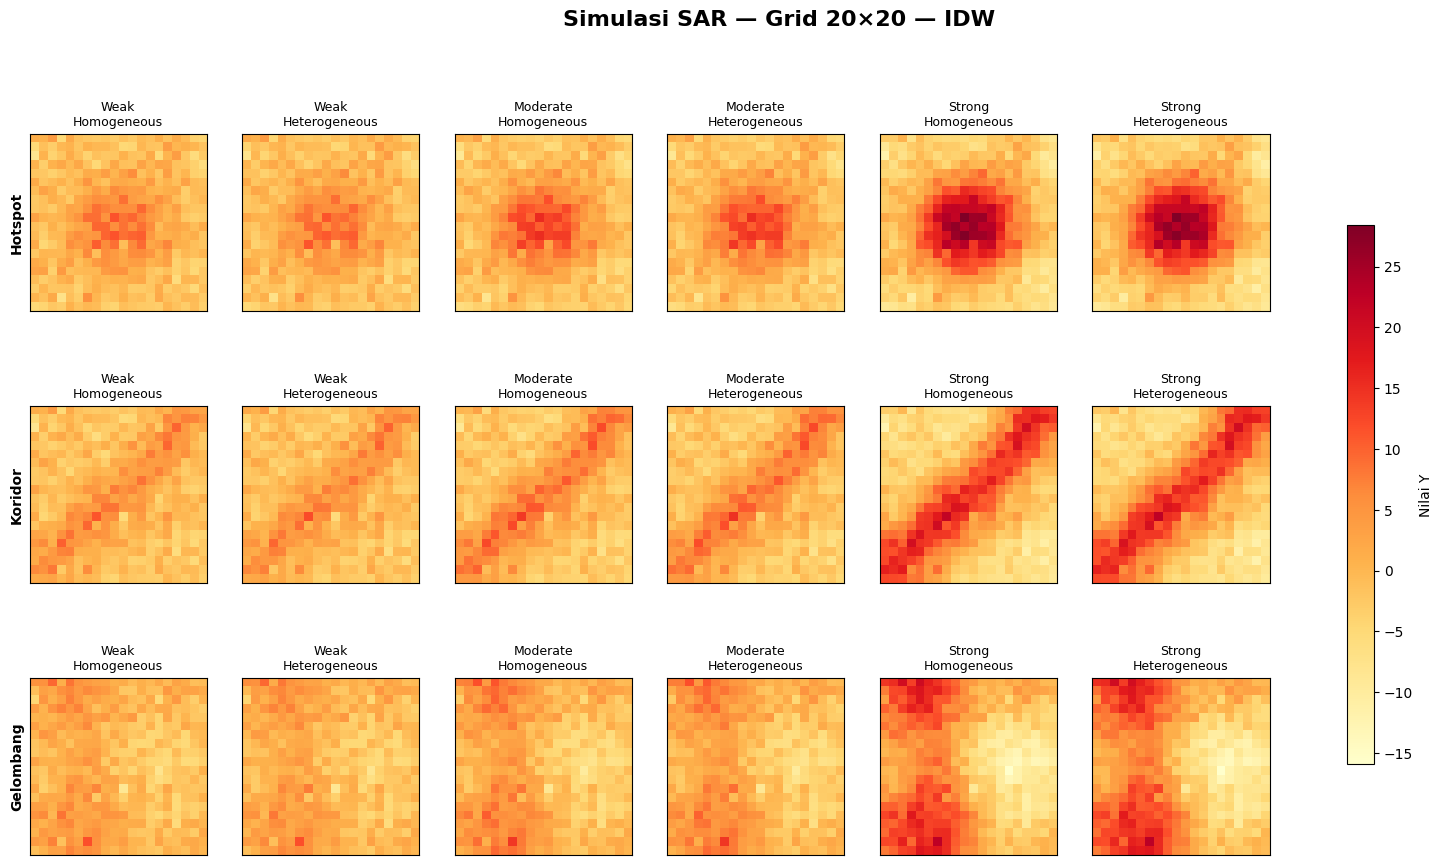



PEMBANGKITAN GRID 20×20 SELESAI
DATA_GRID20.csv
SUMMARY_GRID20.csv
W_KNN5_GRID20.npz
W_DISTANCE_GRID20.npz
W_IDW_GRID20.npz


In [14]:
# ============================================================
# ============================================================
# GRID 20 x 20
# CELL 1 — PEMBANGKITAN DATA SIMULASI
# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix, eye, save_npz
from scipy.sparse.linalg import factorized


# ============================================================
# 1. PENGATURAN GRID
# ============================================================

GRID_SIZE = 20
GRID_LABEL = "GRID20"

N = GRID_SIZE * GRID_SIZE


print("=" * 80)
print(f"PEMBANGKITAN DATA {GRID_LABEL}")
print("=" * 80)

print("Grid Size      :", GRID_SIZE, "x", GRID_SIZE)
print("Jumlah lokasi :", N)


# ============================================================
# 2. MEMBENTUK GRID SPASIAL
# ============================================================

x_coord = np.arange(
    1,
    GRID_SIZE + 1
)

y_coord = np.arange(
    1,
    GRID_SIZE + 1
)


xx, yy = np.meshgrid(
    x_coord,
    y_coord
)


grid = pd.DataFrame({

    "ID":
        np.arange(
            1,
            N + 1
        ),

    "X_coord":
        xx.ravel(),

    "Y_coord":
        yy.ravel()

})


# ============================================================
# 3. NORMALISASI KOORDINAT KE [0,1]
# ============================================================

grid["X_norm"] = (

    grid["X_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Y_norm"] = (

    grid["Y_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Grid_Size"] = GRID_SIZE
grid["N"] = N


# ============================================================
# 4. MEMBENTUK ZONA ERROR
# ============================================================

grid["Error_Zone"] = np.where(

    grid["X_norm"] <= 0.5,

    "A",

    "B"

)


print("\nJumlah lokasi per zona:")

display(
    grid["Error_Zone"].value_counts()
)


display(
    grid.head()
)


# ============================================================
# 5. FUNGSI STANDARDISASI POLA
# ============================================================

def standardize_pattern(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return (

        values
        -
        np.mean(values)

    ) / np.std(values)


# ============================================================
# 6. MEMBENTUK POLA SPASIAL
# ============================================================

x = grid["X_norm"].values
y = grid["Y_norm"].values


# ============================================================
# 6.1 HOTSPOT / POLA TERPUSAT
# ============================================================

TAU_H = 0.18


hotspot_raw = np.exp(

    -(

        (x - 0.5) ** 2

        +

        (y - 0.5) ** 2

    )

    /

    (
        2 * TAU_H ** 2
    )

)


hotspot = standardize_pattern(
    hotspot_raw
)


# ============================================================
# 6.2 KORIDOR
# ============================================================

TAU_C = 0.12


corridor_raw = np.exp(

    -(

        np.abs(
            y - x
        ) ** 2

    )

    /

    (
        2 * TAU_C ** 2
    )

)


corridor = standardize_pattern(
    corridor_raw
)


# ============================================================
# 6.3 GELOMBANG
# ============================================================

wave_raw = (

    np.sin(
        2 * np.pi * x
    )

    +

    0.7
    *
    np.cos(
        2 * np.pi * y
    )

)


wave = standardize_pattern(
    wave_raw
)


PATTERN_DICT = {

    "Hotspot":
        hotspot,

    "Koridor":
        corridor,

    "Gelombang":
        wave

}


# ============================================================
# 7. FUNGSI MEMBENTUK MATRIKS PLOT
# ============================================================

def pattern_to_matrix(values):

    temp = grid[
        [
            "X_coord",
            "Y_coord"
        ]
    ].copy()

    temp["value"] = values

    return temp.pivot(

        index="Y_coord",

        columns="X_coord",

        values="value"

    )


# ============================================================
# 8. VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(
    list(
        PATTERN_DICT.values()
    )
)


pattern_limit = np.max(
    np.abs(
        all_pattern_values
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):

    matrix = pattern_to_matrix(
        pattern_values
    )


    im = ax.imshow(

        matrix,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(
        pattern_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Koordinat X"
    )

    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Pola Prediktor Spasial — Grid 20×20",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# 9. MEMBANGKITKAN 19 PREDIKTOR RANDOM
# ============================================================

SEED_X = 2026


rng_X = np.random.default_rng(
    SEED_X
)


X_random = rng_X.normal(

    loc=0,

    scale=1,

    size=(
        N,
        19
    )

)


X_columns = [

    f"X{i}"

    for i in range(
        1,
        20
    )

]


X_df = pd.DataFrame(

    X_random,

    columns=X_columns

)


# ============================================================
# 10. FUNGSI NONLINEAR NON-SPASIAL
# ============================================================

non_spatial_signal = (

    2
    *
    np.sin(
        X_df["X1"].values
    )

    +

    0.5
    *
    (
        X_df["X2"].values ** 2
    )

    +

    (
        X_df["X3"].values

        *

        X_df["X4"].values
    )

    +

    X_df["X5"].values

)


# ============================================================
# 11. MEMBANGKITKAN ERROR DASAR
# ============================================================

SEED_ERROR = 2027


rng_error = np.random.default_rng(
    SEED_ERROR
)


z_error = rng_error.normal(

    loc=0,

    scale=1,

    size=N

)


# ============================================================
# 12. STRUKTUR VARIANS ERROR
# ============================================================

variance_homo = np.ones(
    N
)


variance_hetero = np.where(

    grid[
        "Error_Zone"
    ].values
    ==
    "A",

    0.5,

    1.5

)


error_homo = z_error.copy()


error_hetero = (

    np.sqrt(
        variance_hetero
    )

    *

    z_error

)


ERROR_DICT = {

    "Homogeneous":
        error_homo,

    "Heterogeneous":
        error_hetero

}


# ============================================================
# 13. KOORDINAT UNTUK W
# ============================================================

coordinates = grid[
    [
        "X_coord",
        "Y_coord"
    ]
].values


spatial_tree = cKDTree(
    coordinates
)


# ============================================================
# 14. FUNGSI ROW STANDARDIZATION
# ============================================================

def row_standardize_sparse(W):

    W = W.tocsr().astype(float)

    W.setdiag(0)

    W.eliminate_zeros()


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    if np.any(
        row_sum == 0
    ):

        raise ValueError(
            "Terdapat lokasi tanpa tetangga."
        )


    W_standardized = W.multiply(

        (
            1 / row_sum
        )[:, None]

    ).tocsr()


    return W_standardized


# ============================================================
# 15. W KNN-5
# ============================================================

K = 5


knn_distances, knn_indices = spatial_tree.query(

    coordinates,

    k=K + 1

)


knn_rows = np.repeat(

    np.arange(N),

    K

)


knn_cols = knn_indices[

    :,
    1:
].ravel()


knn_values = np.ones(
    len(
        knn_rows
    )
)


W_knn5_raw = csr_matrix(

    (

        knn_values,

        (
            knn_rows,
            knn_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_knn5 = row_standardize_sparse(
    W_knn5_raw
)


# ============================================================
# 16. W DISTANCE BAND
# ============================================================

DISTANCE_THRESHOLD = 1.5


distance_rows = []
distance_cols = []


distance_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=DISTANCE_THRESHOLD

)


for i, neighbors in enumerate(
    distance_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= DISTANCE_THRESHOLD
        ):

            distance_rows.append(i)

            distance_cols.append(j)


W_distance_raw = csr_matrix(

    (

        np.ones(
            len(
                distance_rows
            )
        ),

        (
            distance_rows,
            distance_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_distance = row_standardize_sparse(
    W_distance_raw
)


# ============================================================
# 17. W IDW
# ============================================================

IDW_RADIUS = 2.5
IDW_ALPHA = 1


idw_rows = []
idw_cols = []
idw_values = []


idw_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=IDW_RADIUS

)


for i, neighbors in enumerate(
    idw_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= IDW_RADIUS
        ):

            idw_rows.append(i)

            idw_cols.append(j)

            idw_values.append(

                1
                /
                (
                    distance_ij
                    **
                    IDW_ALPHA
                )

            )


W_idw_raw = csr_matrix(

    (

        idw_values,

        (
            idw_rows,
            idw_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_idw = row_standardize_sparse(
    W_idw_raw
)


# ============================================================
# DICTIONARY W
# ============================================================

W_RAW_DICT = {

    "KNN-5":
        W_knn5_raw,

    "Distance Band":
        W_distance_raw,

    "IDW":
        W_idw_raw

}


W_DICT = {

    "KNN-5":
        W_knn5,

    "Distance Band":
        W_distance,

    "IDW":
        W_idw

}


# ============================================================
# 18. PARAMETER RHO
# ============================================================

RHO_DICT = {

    "Weak":
        0.20,

    "Moderate":
        0.50,

    "Strong":
        0.80

}


# ============================================================
# 19. FUNGSI MORAN'S I
# ============================================================

def morans_I(
    values,
    W
):

    values = np.asarray(
        values,
        dtype=float
    )


    z = (

        values
        -
        np.mean(
            values
        )

    )


    n_obs = len(
        values
    )


    S0 = W.sum()


    numerator = (

        z

        @

        (
            W @ z
        )

    )


    denominator = (

        z

        @

        z

    )


    return float(

        (
            n_obs
            /
            S0
        )

        *

        (
            numerator
            /
            denominator
        )

    )


# ============================================================
# 20. MEMBUAT SOLVER SAR
# ============================================================

SAR_SOLVER_DICT = {}


for W_name, W in W_DICT.items():


    for strength_name, rho in RHO_DICT.items():


        A = (

            eye(
                N,
                format="csc"
            )

            -

            rho
            *
            W.tocsc()

        )


        SAR_SOLVER_DICT[

            (
                W_name,
                strength_name
            )

        ] = factorized(
            A
        )


# ============================================================
# 21. MEMBANGKITKAN SELURUH 54 SKENARIO
# ============================================================

scenario_summary_rows = []

simulation_rows = []

Y_SCENARIOS = {}


for pattern_name, spatial_predictor in PATTERN_DICT.items():


    g_X = (

        2
        *
        spatial_predictor

        +

        non_spatial_signal

    )


    for W_name, W in W_DICT.items():


        for strength_name, rho in RHO_DICT.items():


            sar_solver = SAR_SOLVER_DICT[

                (
                    W_name,
                    strength_name
                )

            ]


            for error_name, error_values in ERROR_DICT.items():


                scenario_id = (

                    f"G{GRID_SIZE}_"

                    f"{pattern_name.upper()}_"

                    f"{W_name.upper().replace(' ', '_').replace('-', '')}_"

                    f"{strength_name.upper()}_"

                    f"{error_name.upper()}"

                )


                rhs = (

                    g_X

                    +

                    error_values

                )


                Y_values = sar_solver(
                    rhs
                )


                moran_y = morans_I(

                    Y_values,

                    W

                )


                Y_SCENARIOS[
                    scenario_id
                ] = Y_values.copy()


                scenario_summary_rows.append({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Mean_Y":
                        np.mean(
                            Y_values
                        ),

                    "SD_Y":
                        np.std(
                            Y_values,
                            ddof=1
                        ),

                    "Moran_I_Y":
                        moran_y

                })


                temp = pd.DataFrame({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Location_ID":
                        grid[
                            "ID"
                        ].values,

                    "X_coord":
                        grid[
                            "X_coord"
                        ].values,

                    "Y_coord":
                        grid[
                            "Y_coord"
                        ].values,

                    "X_norm":
                        grid[
                            "X_norm"
                        ].values,

                    "Y_norm":
                        grid[
                            "Y_norm"
                        ].values,

                    "Error_Zone":
                        grid[
                            "Error_Zone"
                        ].values,

                    "X_spatial":
                        spatial_predictor,

                    "Error":
                        error_values,

                    "g_X":
                        g_X,

                    "Y":
                        Y_values

                })


                for col in X_columns:

                    temp[
                        col
                    ] = X_df[
                        col
                    ].values


                simulation_rows.append(
                    temp
                )


# ============================================================
# 22. GABUNGKAN SELURUH SKENARIO
# ============================================================

scenario_summary = pd.DataFrame(

    scenario_summary_rows

)


simulation_long = pd.concat(

    simulation_rows,

    ignore_index=True

)


# ============================================================
# 23. OBJEK AKHIR KHUSUS GRID 20
# ============================================================

DATA_GRID20 = simulation_long.copy()

SUMMARY_GRID20 = scenario_summary.copy()


# ============================================================
# 24. CEK HASIL PEMBANGKITAN
# ============================================================

print("\n")
print("=" * 80)
print("HASIL PEMBANGKITAN DATA GRID 20×20")
print("=" * 80)


print(
    "Grid              :",
    GRID_SIZE,
    "x",
    GRID_SIZE
)

print(
    "N                 :",
    N
)

print(
    "Jumlah skenario   :",
    DATA_GRID20[
        "Scenario_ID"
    ].nunique()
)

print(
    "Jumlah baris data :",
    len(
        DATA_GRID20
    )
)

print(
    "Lokasi/skenario   :",
    DATA_GRID20[
        "Location_ID"
    ].nunique()
)


print("=" * 80)


display(
    SUMMARY_GRID20.head()
)


display(
    DATA_GRID20.head()
)


# ============================================================
# 25. CEK 54 SKENARIO
# ============================================================

jumlah_skenario = (

    DATA_GRID20[

        [
            "Pattern",
            "W_Method",
            "Strength",
            "Rho",
            "Error_Structure"
        ]

    ]

    .drop_duplicates()

    .shape[0]

)


print(
    "\nJumlah kombinasi skenario =",
    jumlah_skenario
)


# ============================================================
# 26. VISUALISASI Y
# ============================================================

pattern_order = [

    "Hotspot",
    "Koridor",
    "Gelombang"

]


column_order = [

    ("Weak", "Homogeneous"),

    ("Weak", "Heterogeneous"),

    ("Moderate", "Homogeneous"),

    ("Moderate", "Heterogeneous"),

    ("Strong", "Homogeneous"),

    ("Strong", "Heterogeneous")

]


for W_name in W_DICT.keys():


    subset_W = DATA_GRID20[

        DATA_GRID20[
            "W_Method"
        ]
        ==
        W_name

    ]


    Y_min = subset_W[
        "Y"
    ].min()


    Y_max = subset_W[
        "Y"
    ].max()


    fig, axes = plt.subplots(

        3,
        6,

        figsize=(20, 10)

    )


    for row_index, pattern_name in enumerate(
        pattern_order
    ):


        for col_index, (
            strength_name,
            error_name
        ) in enumerate(
            column_order
        ):


            temp = subset_W[

                (
                    subset_W[
                        "Pattern"
                    ]
                    ==
                    pattern_name
                )

                &

                (
                    subset_W[
                        "Strength"
                    ]
                    ==
                    strength_name
                )

                &

                (
                    subset_W[
                        "Error_Structure"
                    ]
                    ==
                    error_name
                )

            ]


            matrix_Y = temp.pivot(

                index="Y_coord",

                columns="X_coord",

                values="Y"

            )


            im = axes[
                row_index,
                col_index
            ].imshow(

                matrix_Y,

                origin="lower",

                cmap="YlOrRd",

                vmin=Y_min,

                vmax=Y_max,

                aspect="equal"

            )


            axes[
                row_index,
                col_index
            ].set_title(

                f"{strength_name}\n"
                f"{error_name}",

                fontsize=9

            )


            if col_index == 0:

                axes[
                    row_index,
                    col_index
                ].set_ylabel(

                    pattern_name,

                    fontweight="bold"

                )


            axes[
                row_index,
                col_index
            ].set_xticks([])


            axes[
                row_index,
                col_index
            ].set_yticks([])


    fig.colorbar(

        im,

        ax=axes.ravel().tolist(),

        label="Nilai Y",

        shrink=0.7

    )


    fig.suptitle(

        f"Simulasi SAR — Grid 20×20 — {W_name}",

        fontsize=16,

        fontweight="bold"

    )


    plt.show()


# ============================================================
# 27. SIMPAN DATA GRID 20
# ============================================================

DATA_GRID20.to_csv(

    "DATA_GRID20.csv",

    index=False

)


SUMMARY_GRID20.to_csv(

    "SUMMARY_GRID20.csv",

    index=False

)


# ============================================================
# 28. SIMPAN MATRIKS W
# ============================================================

save_npz(

    "W_KNN5_GRID20.npz",

    W_knn5

)


save_npz(

    "W_DISTANCE_GRID20.npz",

    W_distance

)


save_npz(

    "W_IDW_GRID20.npz",

    W_idw

)


print("\n")
print("=" * 80)
print("PEMBANGKITAN GRID 20×20 SELESAI")
print("=" * 80)

print("DATA_GRID20.csv")
print("SUMMARY_GRID20.csv")
print("W_KNN5_GRID20.npz")
print("W_DISTANCE_GRID20.npz")
print("W_IDW_GRID20.npz")

print("=" * 80)

VALIDASI DATA SIMULASI SPASIAL — GRID 20×20


1. VALIDASI WEAK - MODERATE - STRONG


,Grid_Size,Strength,Rho,Mean_Moran_I,SD_Moran_I,Min_Moran_I,Max_Moran_I,N_Scenario
2,20,Weak,0.2,0.5662,0.0383,0.5098,0.6284,18
0,20,Moderate,0.5,0.7453,0.0342,0.6853,0.8007,18
1,20,Strong,0.8,0.8993,0.0254,0.8539,0.9278,18


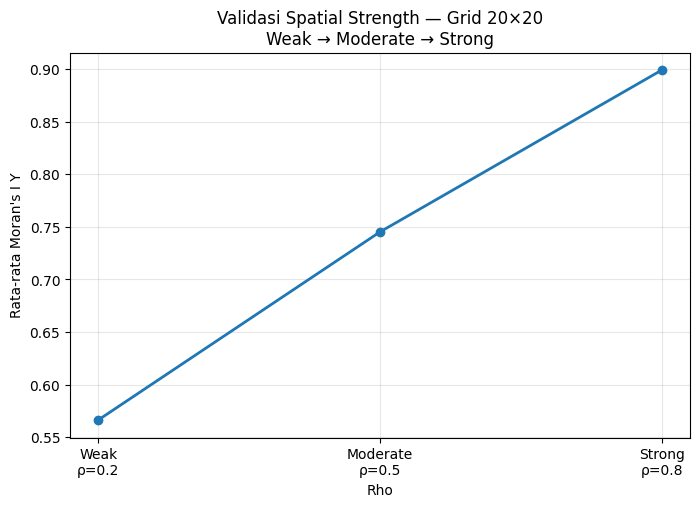


Apakah Mean Moran's I meningkat Weak < Moderate < Strong ?
True


2. MORAN'S I POLA SPASIAL


,Grid_Size,Pattern,W_Method,Moran_I_Pattern
0,20,Hotspot,KNN-5,0.9612
1,20,Hotspot,Distance Band,0.9493
2,20,Hotspot,IDW,0.9053
3,20,Koridor,KNN-5,0.9150
4,20,Koridor,Distance Band,0.9071
5,20,Koridor,IDW,0.8317
6,20,Gelombang,KNN-5,0.9689
7,20,Gelombang,Distance Band,0.9596
8,20,Gelombang,IDW,0.9266



RINGKASAN MORAN'S I POLA


,Grid_Size,Pattern,Mean_Moran_I,Min_Moran_I,Max_Moran_I
0,20,Gelombang,0.9517,0.9266,0.9689
1,20,Hotspot,0.9386,0.9053,0.9612
2,20,Koridor,0.8846,0.8317,0.9150


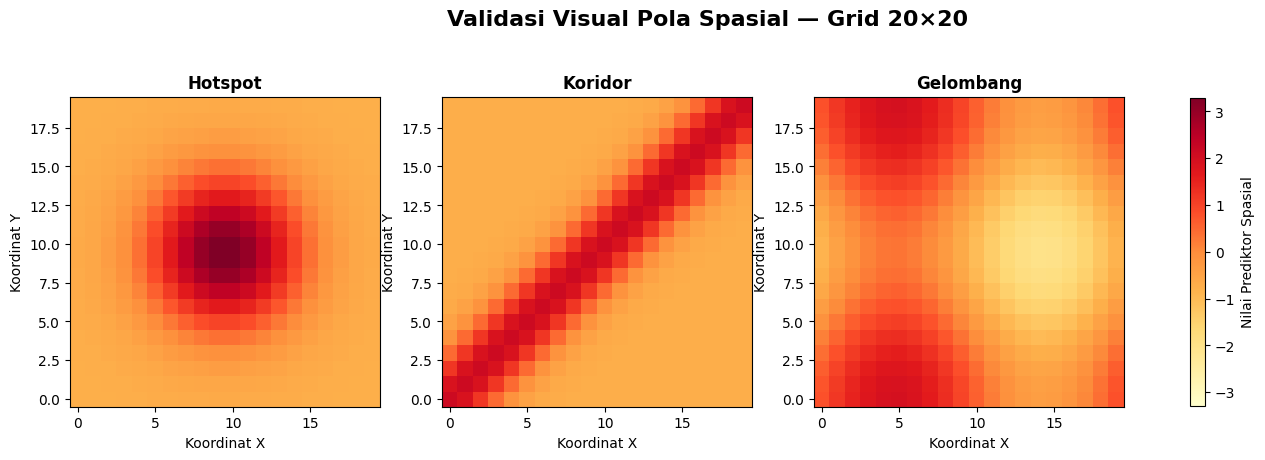



3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN
Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi
Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5
Breusch-Pagan digunakan sebagai diagnostik realisasi sampel.
H0 : Varians error konstan
H1 : Varians error tidak konstan
Alpha = 0.05


,Grid_Size,Error_Structure,Design,LM_Statistic,LM_pvalue,F_Statistic,F_pvalue,BP_Result,BP_Diagnostic
0,20,Homogeneous,Homoskedastis by construction,5.082580,0.024167,5.122253,0.024159,Reject H0,Terdeteksi heteroskedastisitas pada realisasi ini
1,20,Heterogeneous,Heteroskedastis by construction,27.528107,0.000000,29.414801,0.000000,Reject H0,Terdeteksi heteroskedastisitas pada realisasi ini




VALIDASI DESAIN VARIANS
Homogeneous sigma² = 1             : True
Heterogeneous A=0.5 dan B=1.5     : True
Status desain error                : PASS


DIAGNOSTIK BREUSCH-PAGAN
p-value Homogeneous   : 0.024167
p-value Heterogeneous : 0.0
BP Homo   : signifikan pada realisasi ini; ini dicatat sebagai hasil diagnostik sampel.
BP Hetero : heteroskedastisitas berhasil terdeteksi.


VARIANS ERROR SAMPEL PER ZONA


,Grid_Size,Zone,N,Mean_Error_Homo,Variance_Homogeneous,Mean_Error_Hetero,Variance_Heterogeneous
0,20,A,200,0.0769,1.3072,0.0543,0.6536
1,20,B,200,0.0340,0.9676,0.0416,1.4514


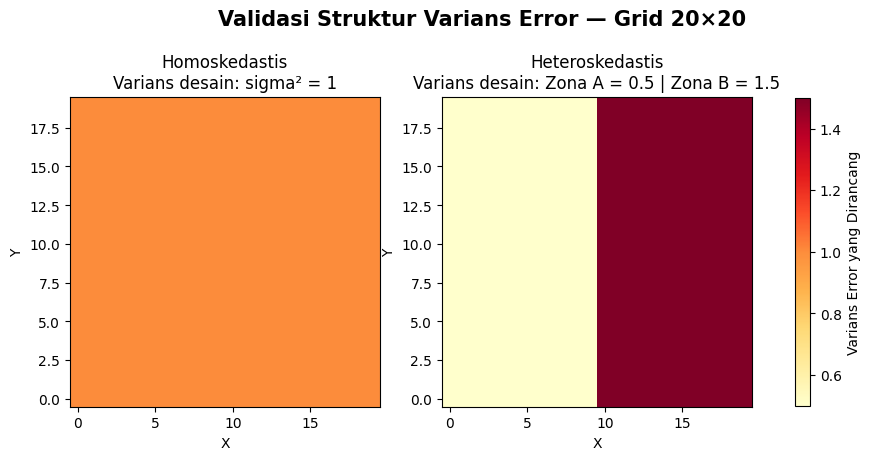



4. VALIDASI MATRIKS BOBOT W


,Grid_Size,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Min_Positive_Weight,Mean_Positive_Weight,Max_Positive_Weight,Min_Row_Sum,Max_Row_Sum,No_Self_Neighbor,Symmetric
0,20,KNN-5,5,5.00,5,0.200,0.200,0.2000,1.0,1.0,True,False
1,20,Distance Band,3,7.41,8,0.125,0.135,0.3333,1.0,1.0,True,False
2,20,IDW,7,17.85,20,0.036,0.056,0.2173,1.0,1.0,True,False


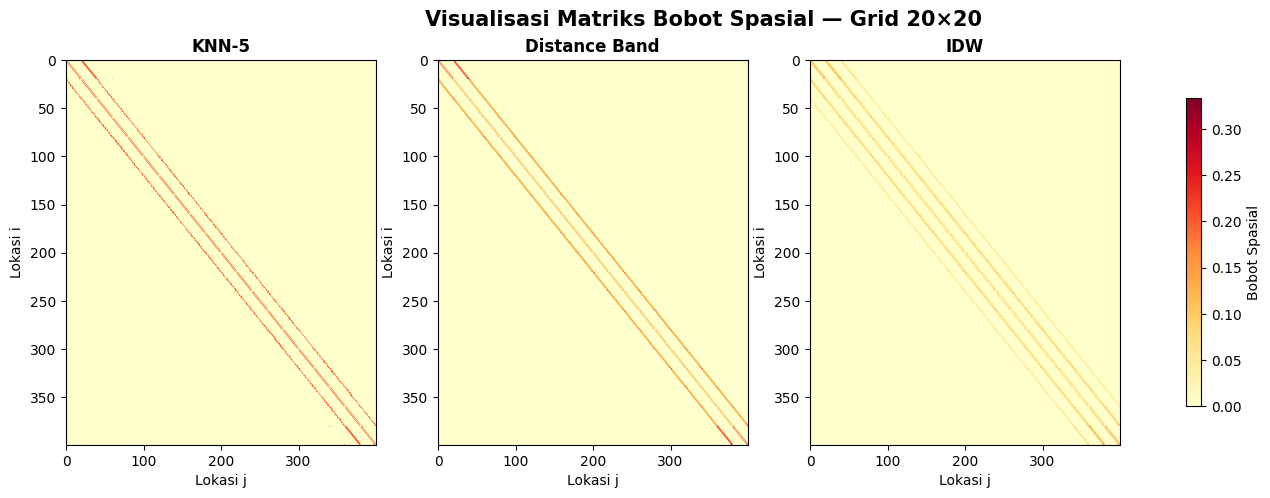

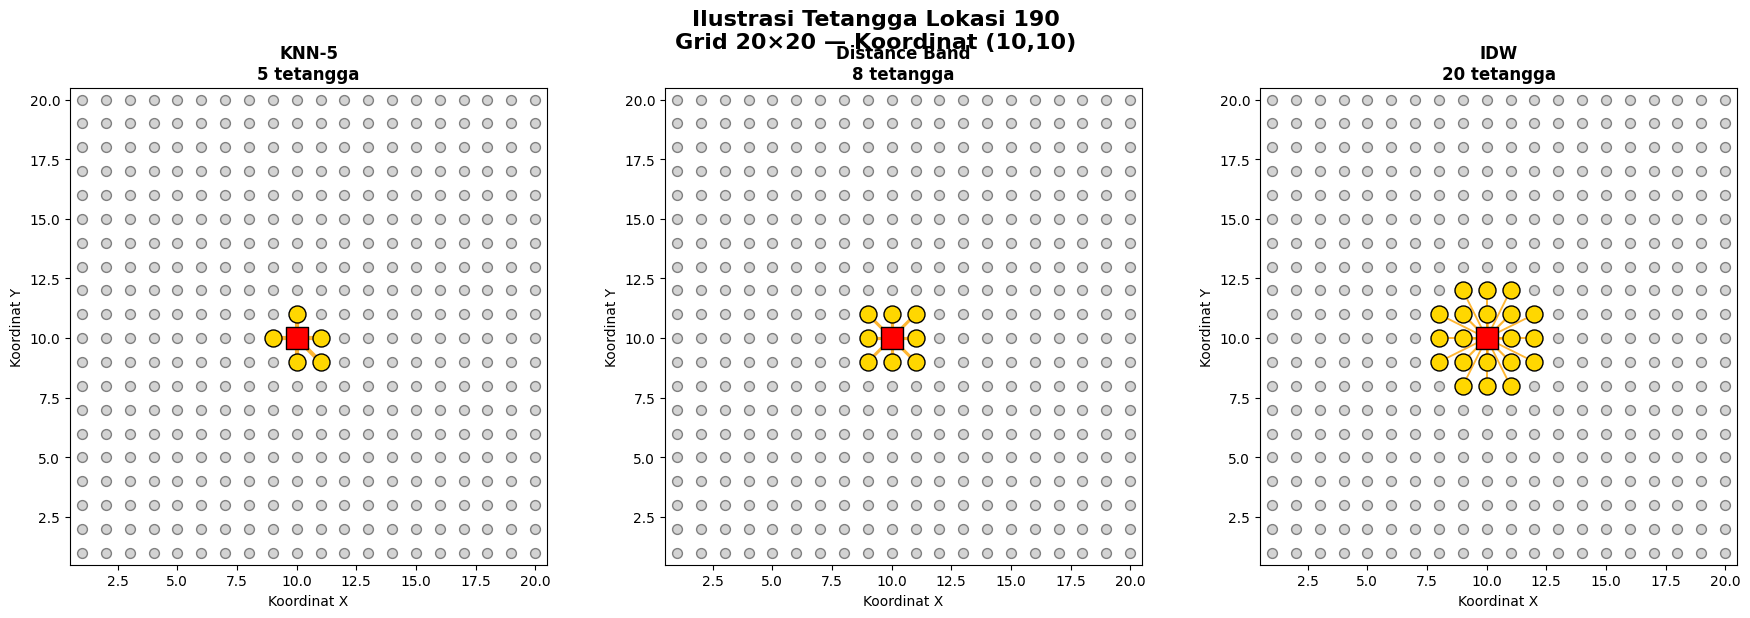



DETAIL TETANGGA LOKASI FOKUS


,Grid_Size,W_Method,Focus_ID,Neighbor_ID,Distance,Weight
6,20,Distance Band,190,170,1.0000,0.1250
8,20,Distance Band,190,189,1.0000,0.1250
9,20,Distance Band,190,191,1.0000,0.1250
11,20,Distance Band,190,210,1.0000,0.1250
5,20,Distance Band,190,169,1.4142,0.1250
7,20,Distance Band,190,171,1.4142,0.1250
10,20,Distance Band,190,209,1.4142,0.1250
12,20,Distance Band,190,211,1.4142,0.1250
18,20,IDW,190,170,1.0000,0.0806
22,20,IDW,190,189,1.0000,0.0806




TABEL VALIDASI FINAL SIMULASI — GRID 20×20


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,20,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,20,Pola spasial,Plot pola + Moran's I pola,PASS
2,20,Homo / Heteroskedastis,Desain varians + Breusch-Pagan diagnostik,PASS
3,20,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS




CEK OBJEK AKHIR GRID 20×20
DATA_GRID20                  : (21600, 37)
SUMMARY_GRID20               : (54, 11)
VALIDASI_GRID20              : (4, 4)
STRENGTH_VALIDATION_GRID20   : (3, 8)
PATTERN_VALIDATION_GRID20    : (9, 4)
BP_GRID20                    : (2, 9)
VARIANCE_GRID20              : (2, 7)
W_VALIDATION_GRID20          : (3, 12)
NEIGHBOR_GRID20              : (33, 6)

Jumlah skenario : 54
Jumlah baris    : 21600
✅ GRID 20×20: SEMUA VALIDASI PASS

FILE YANG TERSIMPAN:
DATA_GRID20.csv
SUMMARY_GRID20.csv
VALIDASI_FINAL_GRID20.csv
VALIDASI_STRENGTH_GRID20.csv
VALIDASI_POLA_GRID20.csv
RINGKASAN_POLA_GRID20.csv
VALIDASI_BREUSCH_PAGAN_GRID20.csv
VALIDASI_VARIANS_GRID20.csv
VALIDASI_W_GRID20.csv
DETAIL_TETANGGA_GRID20.csv
W_KNN5_GRID20.npz
W_DISTANCE_GRID20.npz
W_IDW_GRID20.npz


In [16]:
# ============================================================
# ============================================================
# GRID 20 x 20
# CELL 2 — VALIDASI DATA SIMULASI
# ============================================================
# ============================================================

import statsmodels.api as sm

from statsmodels.stats.diagnostic import het_breuschpagan


print("=" * 80)
print("VALIDASI DATA SIMULASI SPASIAL — GRID 20×20")
print("=" * 80)


# ============================================================
# VALIDASI 1
# WEAK / MODERATE / STRONG
# ============================================================

strength_validation = (

    SUMMARY_GRID20

    .groupby(
        [
            "Strength",
            "Rho"
        ]
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Y",
            "mean"
        ),

        SD_Moran_I=(
            "Moran_I_Y",
            "std"
        ),

        Min_Moran_I=(
            "Moran_I_Y",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Y",
            "max"
        ),

        N_Scenario=(
            "Moran_I_Y",
            "count"
        )

    )

    .reset_index()

)


strength_order = {

    "Weak": 1,

    "Moderate": 2,

    "Strong": 3

}


strength_validation["_order"] = (

    strength_validation[
        "Strength"
    ]

    .map(
        strength_order
    )

)


strength_validation = (

    strength_validation

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

)


strength_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("1. VALIDASI WEAK - MODERATE - STRONG")
print("=" * 80)


display(

    strength_validation.round(4)

)


# ============================================================
# PLOT STRENGTH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    strength_validation[
        "Rho"
    ],

    strength_validation[
        "Mean_Moran_I"
    ],

    marker="o",

    linewidth=2

)


plt.xlabel(
    "Rho"
)


plt.ylabel(
    "Rata-rata Moran's I Y"
)


plt.title(

    "Validasi Spatial Strength — Grid 20×20\n"
    "Weak → Moderate → Strong"

)


plt.xticks(

    [
        0.2,
        0.5,
        0.8
    ],

    [
        "Weak\nρ=0.2",
        "Moderate\nρ=0.5",
        "Strong\nρ=0.8"
    ]

)


plt.grid(
    alpha=0.3
)


plt.show()


# ============================================================
# CEK OTOMATIS STRENGTH
# ============================================================

mean_moran_weak = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Weak",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_moderate = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Moderate",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_strong = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Strong",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


strength_pass = (

    mean_moran_weak

    <

    mean_moran_moderate

    <

    mean_moran_strong

)


print(
    "\nApakah Mean Moran's I meningkat "
    "Weak < Moderate < Strong ?"
)


print(
    strength_pass
)


# ============================================================
# VALIDASI 2
# POLA SPASIAL
# ============================================================

pattern_moran_rows = []


for pattern_name, pattern_values in PATTERN_DICT.items():


    for W_name, W in W_DICT.items():


        I_pattern = morans_I(

            pattern_values,

            W

        )


        pattern_moran_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "Pattern":
                pattern_name,

            "W_Method":
                W_name,

            "Moran_I_Pattern":
                I_pattern

        })


pattern_moran_validation = pd.DataFrame(

    pattern_moran_rows

)


print("\n")
print("=" * 80)
print("2. MORAN'S I POLA SPASIAL")
print("=" * 80)


display(

    pattern_moran_validation.round(4)

)


# ============================================================
# RINGKASAN POLA
# ============================================================

pattern_summary_validation = (

    pattern_moran_validation

    .groupby(
        "Pattern"
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Pattern",
            "mean"
        ),

        Min_Moran_I=(
            "Moran_I_Pattern",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Pattern",
            "max"
        )

    )

    .reset_index()

)


pattern_summary_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print(
    "\nRINGKASAN MORAN'S I POLA"
)


display(

    pattern_summary_validation.round(4)

)


# ============================================================
# VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(

    list(
        PATTERN_DICT.values()
    )

)


pattern_limit = np.max(

    np.abs(
        all_pattern_values
    )

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):


    matrix_pattern = pattern_to_matrix(

        pattern_values

    )


    im = ax.imshow(

        matrix_pattern,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(

        pattern_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Validasi Visual Pola Spasial — Grid 20×20",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# ============================================================
# VALIDASI 3
# STRUKTUR VARIANS ERROR + BREUSCH-PAGAN
# ============================================================
# ============================================================

zone_dummy = (

    grid[
        "Error_Zone"
    ]

    ==
    "B"

).astype(int)


X_BP = sm.add_constant(
    zone_dummy
)


# ============================================================
# FUNGSI BREUSCH-PAGAN
# ============================================================

def run_breusch_pagan(

    residuals,

    exog,

    structure_name,

    design_name

):


    bp_result = het_breuschpagan(

        residuals,

        exog

    )


    LM_stat = bp_result[0]
    LM_pvalue = bp_result[1]

    F_stat = bp_result[2]
    F_pvalue = bp_result[3]


    # --------------------------------------------------------
    # BP hanya sebagai DIAGNOSTIK SAMPEL
    # --------------------------------------------------------

    if LM_pvalue < 0.05:

        bp_result_text = "Reject H0"

        bp_diagnostic = (
            "Terdeteksi heteroskedastisitas pada realisasi ini"
        )

    else:

        bp_result_text = "Fail to Reject H0"

        bp_diagnostic = (
            "Tidak terdeteksi heteroskedastisitas pada realisasi ini"
        )


    return {

        "Grid_Size":
            GRID_SIZE,

        "Error_Structure":
            structure_name,

        "Design":
            design_name,

        "LM_Statistic":
            LM_stat,

        "LM_pvalue":
            LM_pvalue,

        "F_Statistic":
            F_stat,

        "F_pvalue":
            F_pvalue,

        "BP_Result":
            bp_result_text,

        "BP_Diagnostic":
            bp_diagnostic

    }


# ============================================================
# JALANKAN BP
# ============================================================

BP_homo = run_breusch_pagan(

    residuals=
        error_homo,

    exog=
        X_BP,

    structure_name=
        "Homogeneous",

    design_name=
        "Homoskedastis by construction"

)


BP_hetero = run_breusch_pagan(

    residuals=
        error_hetero,

    exog=
        X_BP,

    structure_name=
        "Heterogeneous",

    design_name=
        "Heteroskedastis by construction"

)


BP_table = pd.DataFrame(

    [
        BP_homo,
        BP_hetero
    ]

)


print("\n")
print("=" * 80)
print("3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN")
print("=" * 80)

print(
    "Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi"
)

print(
    "Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5"
)

print(
    "Breusch-Pagan digunakan sebagai diagnostik realisasi sampel."
)

print(
    "H0 : Varians error konstan"
)

print(
    "H1 : Varians error tidak konstan"
)

print(
    "Alpha = 0.05"
)


display(
    BP_table.round(6)
)


# ============================================================
# VALIDASI DESAIN VARIANS
# ============================================================

design_homo_pass = np.allclose(

    variance_homo,

    1.0

)


design_hetero_pass = (

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "A"
        ],

        0.5

    )

    and

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "B"
        ],

        1.5

    )

)


error_design_pass = (

    design_homo_pass

    and

    design_hetero_pass

)


print("\n")
print("=" * 80)
print("VALIDASI DESAIN VARIANS")
print("=" * 80)

print(
    "Homogeneous sigma² = 1             :",
    design_homo_pass
)

print(
    "Heterogeneous A=0.5 dan B=1.5     :",
    design_hetero_pass
)

print(
    "Status desain error                :",
    (
        "PASS"
        if error_design_pass
        else
        "CHECK"
    )
)


# ============================================================
# HASIL BP SEBAGAI DIAGNOSTIK
# ============================================================

homo_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Homogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


hetero_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Heterogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


print("\n")
print("=" * 80)
print("DIAGNOSTIK BREUSCH-PAGAN")
print("=" * 80)

print(
    "p-value Homogeneous   :",
    round(
        homo_pvalue,
        6
    )
)

print(
    "p-value Heterogeneous :",
    round(
        hetero_pvalue,
        6
    )
)


if homo_pvalue >= 0.05:

    print(
        "BP Homo   : sesuai dengan desain homoskedastis."
    )

else:

    print(
        "BP Homo   : signifikan pada realisasi ini; "
        "ini dicatat sebagai hasil diagnostik sampel."
    )


if hetero_pvalue < 0.05:

    print(
        "BP Hetero : heteroskedastisitas berhasil terdeteksi."
    )

else:

    print(
        "BP Hetero : heteroskedastisitas belum terdeteksi "
        "pada realisasi ini."
    )


# ============================================================
# VARIANS ERROR PER ZONA
# ============================================================

variance_check = pd.DataFrame({

    "Zone":
        grid[
            "Error_Zone"
        ],

    "Error_Homogeneous":
        error_homo,

    "Error_Heterogeneous":
        error_hetero

})


variance_zone_table = (

    variance_check

    .groupby(
        "Zone"
    )

    .agg(

        N=(
            "Error_Homogeneous",
            "count"
        ),

        Mean_Error_Homo=(
            "Error_Homogeneous",
            "mean"
        ),

        Variance_Homogeneous=(
            "Error_Homogeneous",
            "var"
        ),

        Mean_Error_Hetero=(
            "Error_Heterogeneous",
            "mean"
        ),

        Variance_Heterogeneous=(
            "Error_Heterogeneous",
            "var"
        )

    )

    .reset_index()

)


variance_zone_table.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("VARIANS ERROR SAMPEL PER ZONA")
print("=" * 80)


display(
    variance_zone_table.round(4)
)


# ============================================================
# VISUALISASI STRUKTUR VARIANS YANG DIRANCANG
# ============================================================

variance_homo_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_homo

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


variance_hetero_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_hetero

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


fig, axes = plt.subplots(

    1,
    2,

    figsize=(11, 5)

)


axes[0].imshow(

    variance_homo_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[0].set_title(

    "Homoskedastis\n"
    "Varians desain: sigma² = 1"

)


axes[0].set_xlabel(
    "X"
)

axes[0].set_ylabel(
    "Y"
)


im2 = axes[1].imshow(

    variance_hetero_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[1].set_title(

    "Heteroskedastis\n"
    "Varians desain: Zona A = 0.5 | Zona B = 1.5"

)


axes[1].set_xlabel(
    "X"
)

axes[1].set_ylabel(
    "Y"
)


fig.colorbar(

    im2,

    ax=axes.ravel().tolist(),

    label="Varians Error yang Dirancang",

    shrink=0.8

)


fig.suptitle(

    "Validasi Struktur Varians Error — Grid 20×20",

    fontsize=15,

    fontweight="bold"

)


plt.show()

# ============================================================
# VALIDASI 4
# MATRIKS BOBOT W
# ============================================================

W_validation_rows = []


for W_name, W in W_DICT.items():


    W_raw = W_RAW_DICT[
        W_name
    ].tocsr()


    W = W.tocsr()


    n_neighbors = np.diff(
        W_raw.indptr
    )


    positive_weights = W.data


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    diagonal_zero = np.allclose(

        W.diagonal(),

        0

    )


    W_difference = (

        W

        -

        W.T

    ).tocsr()


    if W_difference.nnz == 0:

        symmetric = True

    else:

        symmetric = (

            np.max(

                np.abs(
                    W_difference.data
                )

            )

            <

            1e-12

        )


    W_validation_rows.append({

        "Grid_Size":
            GRID_SIZE,

        "W_Method":
            W_name,

        "Min_Neighbor":
            np.min(
                n_neighbors
            ),

        "Mean_Neighbor":
            np.mean(
                n_neighbors
            ),

        "Max_Neighbor":
            np.max(
                n_neighbors
            ),

        "Min_Positive_Weight":
            np.min(
                positive_weights
            ),

        "Mean_Positive_Weight":
            np.mean(
                positive_weights
            ),

        "Max_Positive_Weight":
            np.max(
                positive_weights
            ),

        "Min_Row_Sum":
            np.min(
                row_sum
            ),

        "Max_Row_Sum":
            np.max(
                row_sum
            ),

        "No_Self_Neighbor":
            diagonal_zero,

        "Symmetric":
            symmetric

    })


W_validation_table = pd.DataFrame(

    W_validation_rows

)


print("\n")
print("=" * 80)
print("4. VALIDASI MATRIKS BOBOT W")
print("=" * 80)


display(

    W_validation_table.round(4)

)


# ============================================================
# HEATMAP W
# ============================================================

W_MAX = max(

    np.max(
        W.data
    )

    for W in W_DICT.values()

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    W_dense_plot = W.toarray()


    im = ax.imshow(

        W_dense_plot,

        cmap="YlOrRd",

        vmin=0,

        vmax=W_MAX,

        aspect="auto"

    )


    ax.set_title(

        W_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Lokasi j"
    )


    ax.set_ylabel(
        "Lokasi i"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Bobot Spasial",

    shrink=0.8

)


fig.suptitle(

    "Visualisasi Matriks Bobot Spasial — Grid 20×20",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# ILUSTRASI TETANGGA SATU LOKASI
# ============================================================

focus_x = GRID_SIZE // 2

focus_y = GRID_SIZE // 2


focus_idx = grid[

    (
        grid[
            "X_coord"
        ]
        ==
        focus_x
    )

    &

    (
        grid[
            "Y_coord"
        ]
        ==
        focus_y
    )

].index[0]


focus_id = int(

    grid.loc[
        focus_idx,
        "ID"
    ]

)


# ============================================================
# FUNGSI PLOT TETANGGA
# ============================================================

def plot_focus_neighbors(

    ax,

    W,

    method_name

):


    W_row = W.getrow(
        focus_idx
    )


    neighbors = W_row.indices


    ax.scatter(

        grid[
            "X_coord"
        ],

        grid[
            "Y_coord"
        ],

        s=50,

        color="lightgray",

        edgecolor="gray",

        zorder=1

    )


    for j in neighbors:


        weight = float(

            W[
                focus_idx,
                j
            ]

        )


        ax.plot(

            [
                grid.loc[
                    focus_idx,
                    "X_coord"
                ],

                grid.loc[
                    j,
                    "X_coord"
                ]
            ],

            [
                grid.loc[
                    focus_idx,
                    "Y_coord"
                ],

                grid.loc[
                    j,
                    "Y_coord"
                ]
            ],

            linewidth=

                1

                +

                10
                *
                weight,

            color="orange",

            alpha=0.8,

            zorder=2

        )


    ax.scatter(

        grid.loc[
            neighbors,
            "X_coord"
        ],

        grid.loc[
            neighbors,
            "Y_coord"
        ],

        s=150,

        color="gold",

        edgecolor="black",

        zorder=3

    )


    ax.scatter(

        grid.loc[
            focus_idx,
            "X_coord"
        ],

        grid.loc[
            focus_idx,
            "Y_coord"
        ],

        s=240,

        marker="s",

        color="red",

        edgecolor="black",

        zorder=4

    )


    ax.set_title(

        f"{method_name}\n"
        f"{len(neighbors)} tetangga",

        fontweight="bold"

    )


    ax.set_xlim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_ylim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


# ============================================================
# PLOT TETANGGA
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(18, 6)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    plot_focus_neighbors(

        ax,

        W,

        W_name

    )


fig.suptitle(

    f"Ilustrasi Tetangga Lokasi {focus_id}\n"
    f"Grid 20×20 — Koordinat ({focus_x},{focus_y})",

    fontsize=16,

    fontweight="bold"

)


plt.tight_layout()


plt.show()


# ============================================================
# DETAIL TETANGGA
# ============================================================

neighbor_rows = []


for W_name, W in W_DICT.items():


    neighbors = W.getrow(
        focus_idx
    ).indices


    for j in neighbors:


        distance_ij = np.linalg.norm(

            coordinates[
                focus_idx
            ]

            -

            coordinates[
                j
            ]

        )


        neighbor_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "W_Method":
                W_name,

            "Focus_ID":
                focus_id,

            "Neighbor_ID":
                int(
                    grid.loc[
                        j,
                        "ID"
                    ]
                ),

            "Distance":
                distance_ij,

            "Weight":
                float(
                    W[
                        focus_idx,
                        j
                    ]
                )

        })


neighbor_detail_table = pd.DataFrame(

    neighbor_rows

)


print("\n")
print("=" * 80)
print("DETAIL TETANGGA LOKASI FOKUS")
print("=" * 80)


display(

    neighbor_detail_table

    .sort_values(

        [
            "W_Method",
            "Distance",
            "Neighbor_ID"
        ]

    )

    .round(4)

)


# ============================================================
# TABEL VALIDASI FINAL
# ============================================================

pattern_pass = np.all(

    pattern_moran_validation[
        "Moran_I_Pattern"
    ]

    >
    0

)


W_pass = (

    np.allclose(

        W_validation_table[
            "Min_Row_Sum"
        ].values,

        1

    )

    and

    np.allclose(

        W_validation_table[
            "Max_Row_Sum"
        ].values,

        1

    )

    and

    (
        W_validation_table[
            "Min_Neighbor"
        ].min()
        >
        0
    )

    and

    W_validation_table[
        "No_Self_Neighbor"
    ].all()

)


validation_final = pd.DataFrame({

    "Grid_Size": [

        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE

    ],

    "Komponen": [

        "Weak / Moderate / Strong",

        "Pola spasial",

        "Homo / Heteroskedastis",

        "Spatial Weight Matrix"

    ],

    "Alat_Validasi": [

        "rho + Moran's I Y",

        "Plot pola + Moran's I pola",

        "Desain varians + Breusch-Pagan diagnostik",

        "Visualisasi W + statistik tetangga"

    ],

    "Hasil_Utama": [

        (
            "PASS"
            if strength_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if pattern_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if error_design_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if W_pass
            else
            "CHECK"
        )

    ]

})

# ============================================================
# OBJEK AKHIR KHUSUS GRID 20
# ============================================================

VALIDASI_GRID20 = validation_final.copy()


STRENGTH_VALIDATION_GRID20 = (

    strength_validation.copy()

)


PATTERN_VALIDATION_GRID20 = (

    pattern_moran_validation.copy()

)


PATTERN_SUMMARY_GRID20 = (

    pattern_summary_validation.copy()

)


BP_GRID20 = (

    BP_table.copy()

)


VARIANCE_GRID20 = (

    variance_zone_table.copy()

)


W_VALIDATION_GRID20 = (

    W_validation_table.copy()

)


NEIGHBOR_GRID20 = (

    neighbor_detail_table.copy()

)


# ============================================================
# TAMPILKAN VALIDASI FINAL
# ============================================================

print("\n")
print("=" * 80)
print("TABEL VALIDASI FINAL SIMULASI — GRID 20×20")
print("=" * 80)


display(

    VALIDASI_GRID20

)


# ============================================================
# SIMPAN SEMUA HASIL VALIDASI
# ============================================================

VALIDASI_GRID20.to_csv(

    "VALIDASI_FINAL_GRID20.csv",

    index=False

)


STRENGTH_VALIDATION_GRID20.to_csv(

    "VALIDASI_STRENGTH_GRID20.csv",

    index=False

)


PATTERN_VALIDATION_GRID20.to_csv(

    "VALIDASI_POLA_GRID20.csv",

    index=False

)


PATTERN_SUMMARY_GRID20.to_csv(

    "RINGKASAN_POLA_GRID20.csv",

    index=False

)


BP_GRID20.to_csv(

    "VALIDASI_BREUSCH_PAGAN_GRID20.csv",

    index=False

)


VARIANCE_GRID20.to_csv(

    "VALIDASI_VARIANS_GRID20.csv",

    index=False

)


W_VALIDATION_GRID20.to_csv(

    "VALIDASI_W_GRID20.csv",

    index=False

)


NEIGHBOR_GRID20.to_csv(

    "DETAIL_TETANGGA_GRID20.csv",

    index=False

)


# ============================================================
# CEK AKHIR SEMUA OBJEK
# ============================================================

print("\n")
print("=" * 80)
print("CEK OBJEK AKHIR GRID 20×20")
print("=" * 80)


print(
    "DATA_GRID20                  :",
    DATA_GRID20.shape
)

print(
    "SUMMARY_GRID20               :",
    SUMMARY_GRID20.shape
)

print(
    "VALIDASI_GRID20              :",
    VALIDASI_GRID20.shape
)

print(
    "STRENGTH_VALIDATION_GRID20   :",
    STRENGTH_VALIDATION_GRID20.shape
)

print(
    "PATTERN_VALIDATION_GRID20    :",
    PATTERN_VALIDATION_GRID20.shape
)

print(
    "BP_GRID20                    :",
    BP_GRID20.shape
)

print(
    "VARIANCE_GRID20              :",
    VARIANCE_GRID20.shape
)

print(
    "W_VALIDATION_GRID20          :",
    W_VALIDATION_GRID20.shape
)

print(
    "NEIGHBOR_GRID20              :",
    NEIGHBOR_GRID20.shape
)


print(
    "\nJumlah skenario :",
    DATA_GRID20[
        "Scenario_ID"
    ].nunique()
)


print(
    "Jumlah baris    :",
    len(
        DATA_GRID20
    )
)


print("=" * 80)


# ============================================================
# STATUS AKHIR
# ============================================================

if (

    VALIDASI_GRID20[
        "Hasil_Utama"
    ]

    ==
    "PASS"

).all():

    print(
        "✅ GRID 20×20: SEMUA VALIDASI PASS"
    )

else:

    print(
        "⚠️ GRID 20×20: ADA VALIDASI YANG PERLU DICEK"
    )


print("=" * 80)


print("\nFILE YANG TERSIMPAN:")

print("DATA_GRID20.csv")
print("SUMMARY_GRID20.csv")

print("VALIDASI_FINAL_GRID20.csv")
print("VALIDASI_STRENGTH_GRID20.csv")
print("VALIDASI_POLA_GRID20.csv")
print("RINGKASAN_POLA_GRID20.csv")
print("VALIDASI_BREUSCH_PAGAN_GRID20.csv")
print("VALIDASI_VARIANS_GRID20.csv")
print("VALIDASI_W_GRID20.csv")
print("DETAIL_TETANGGA_GRID20.csv")

print("W_KNN5_GRID20.npz")
print("W_DISTANCE_GRID20.npz")
print("W_IDW_GRID20.npz")

print("=" * 80)

# GRID 30 X 30

## PEMBANGKITAN DATA SIMULASI (N=900)

PEMBANGKITAN DATA GRID30
Grid Size      : 30 x 30
Jumlah lokasi : 900

Jumlah lokasi per zona:


,count
Error_Zone,
A,450
B,450


,ID,X_coord,Y_coord,X_norm,Y_norm,Grid_Size,N,Error_Zone
0,1,1,1,0.000000,0.0,30,900,A
1,2,2,1,0.034483,0.0,30,900,A
2,3,3,1,0.068966,0.0,30,900,A
3,4,4,1,0.103448,0.0,30,900,A
4,5,5,1,0.137931,0.0,30,900,A


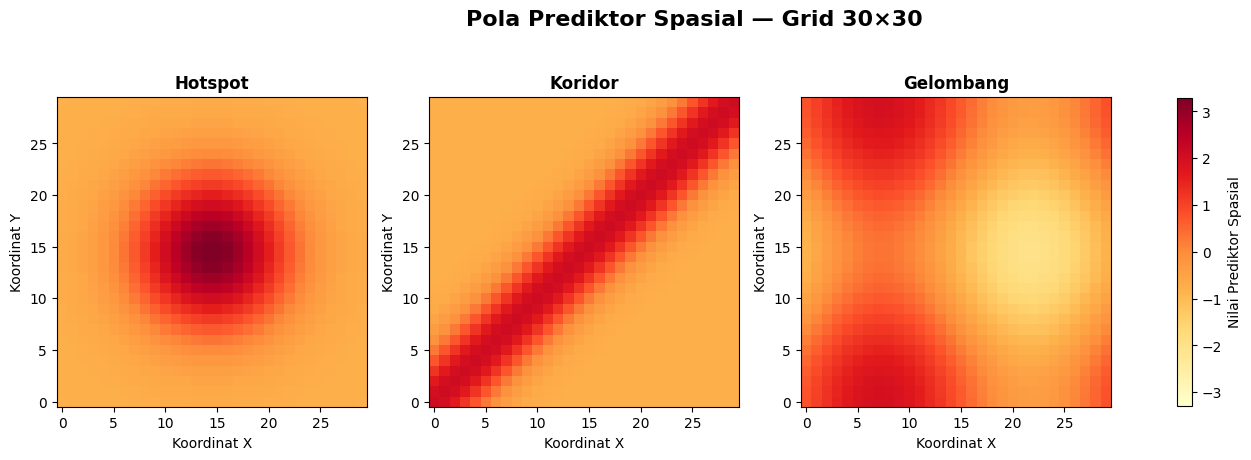



HASIL PEMBANGKITAN DATA GRID 30×30
Grid              : 30 x 30
N                 : 900
Jumlah skenario   : 54
Jumlah baris data : 48600
Lokasi/skenario   : 900


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Mean_Y,SD_Y,Moran_I_Y
0,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,0.607651,3.371546,0.580530
1,30,900,G30_HOTSPOT_KNN5_WEAK_HETEROGENEOUS,Hotspot,KNN-5,Weak,0.2,Heterogeneous,0.611553,3.371829,0.574822
2,30,900,G30_HOTSPOT_KNN5_MODERATE_HOMOGENEOUS,Hotspot,KNN-5,Moderate,0.5,Homogeneous,0.981941,4.654891,0.779031
3,30,900,G30_HOTSPOT_KNN5_MODERATE_HETEROGENEOUS,Hotspot,KNN-5,Moderate,0.5,Heterogeneous,0.986842,4.645122,0.775223
4,30,900,G30_HOTSPOT_KNN5_STRONG_HOMOGENEOUS,Hotspot,KNN-5,Strong,0.8,Homogeneous,2.468138,9.958606,0.933858


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
0,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
1,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
2,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
4,30,900,G30_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260



Jumlah kombinasi skenario = 54


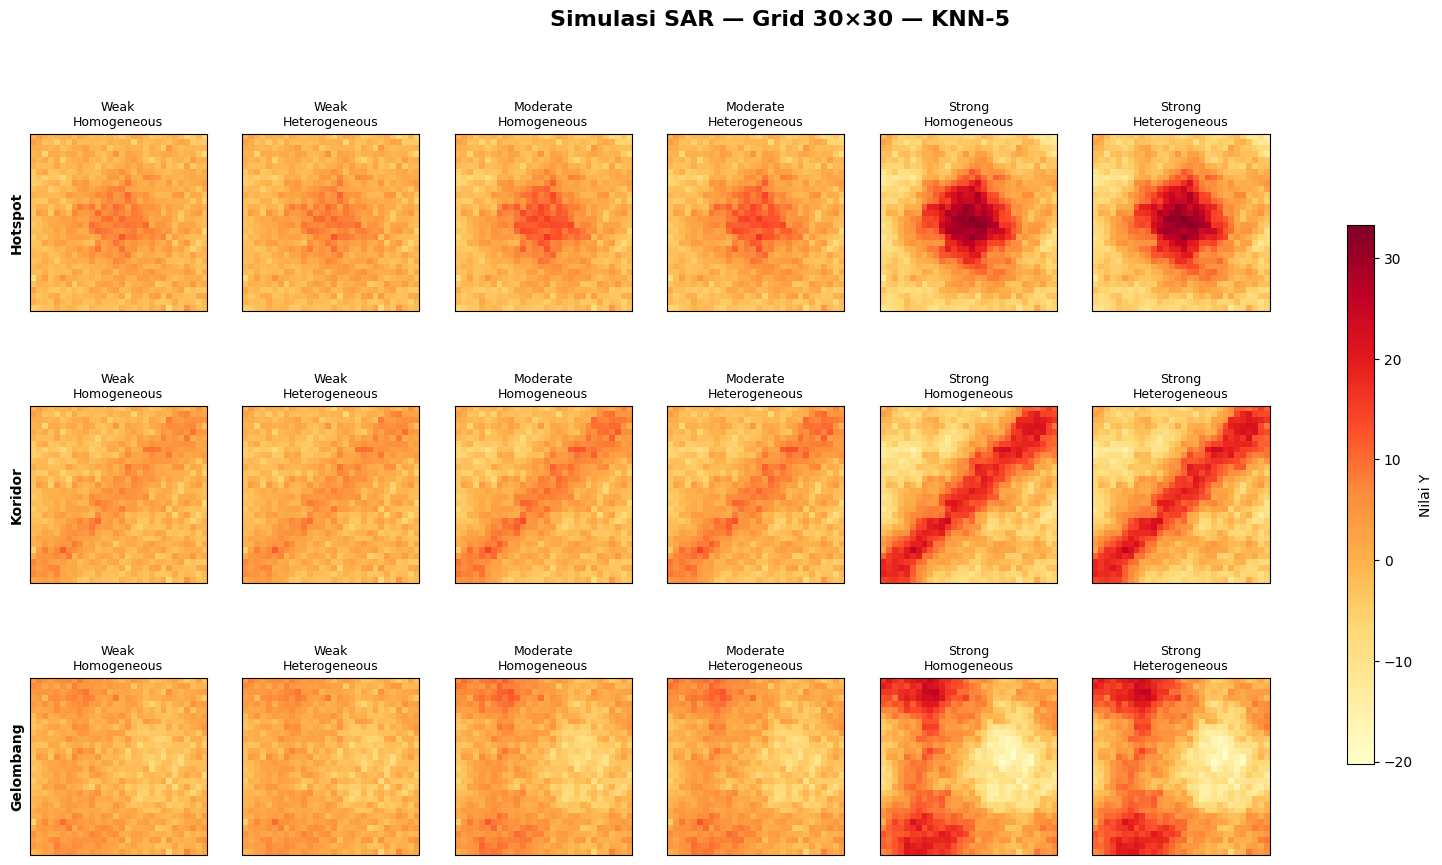

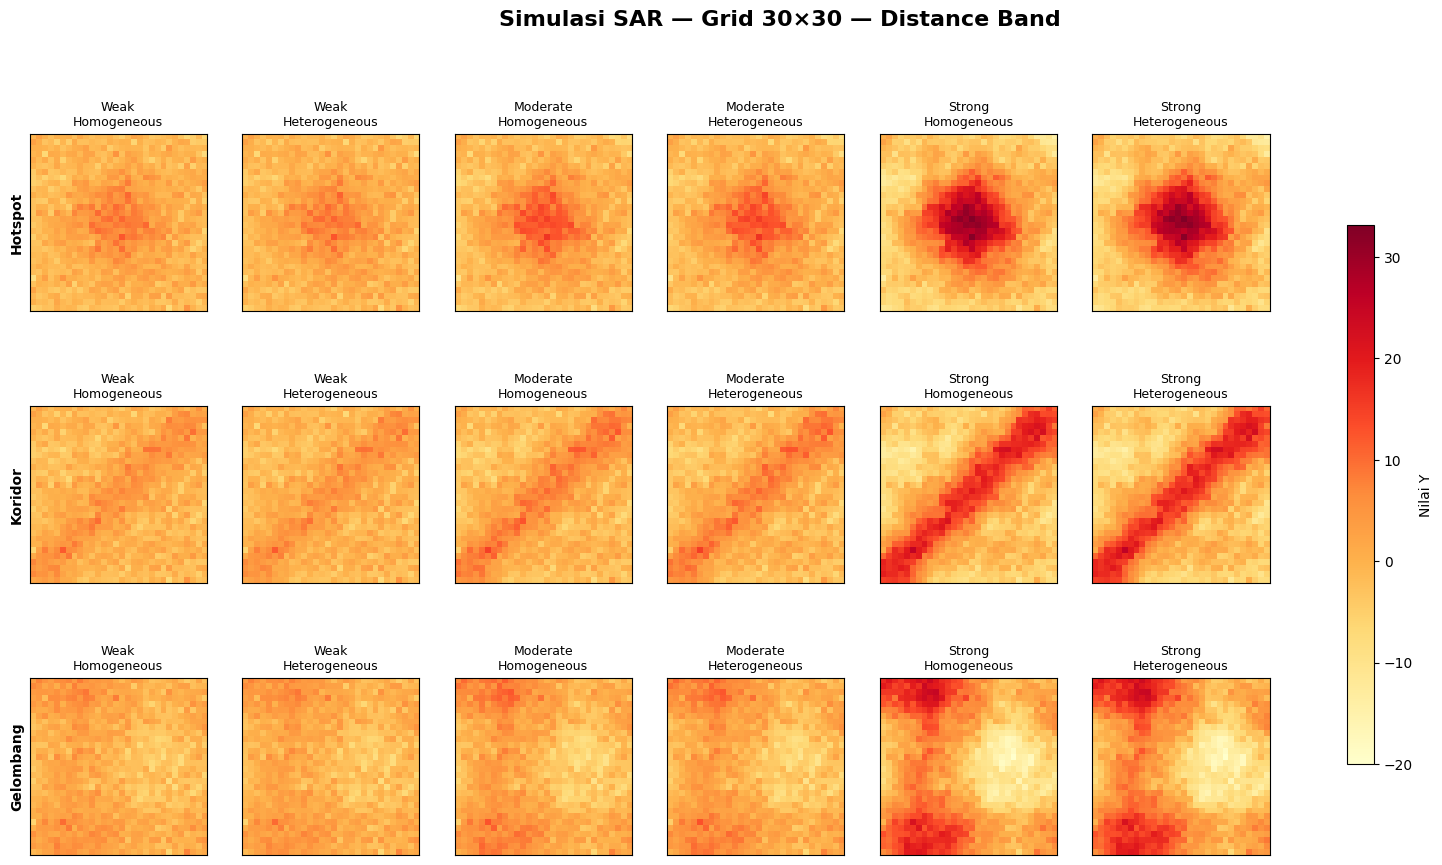

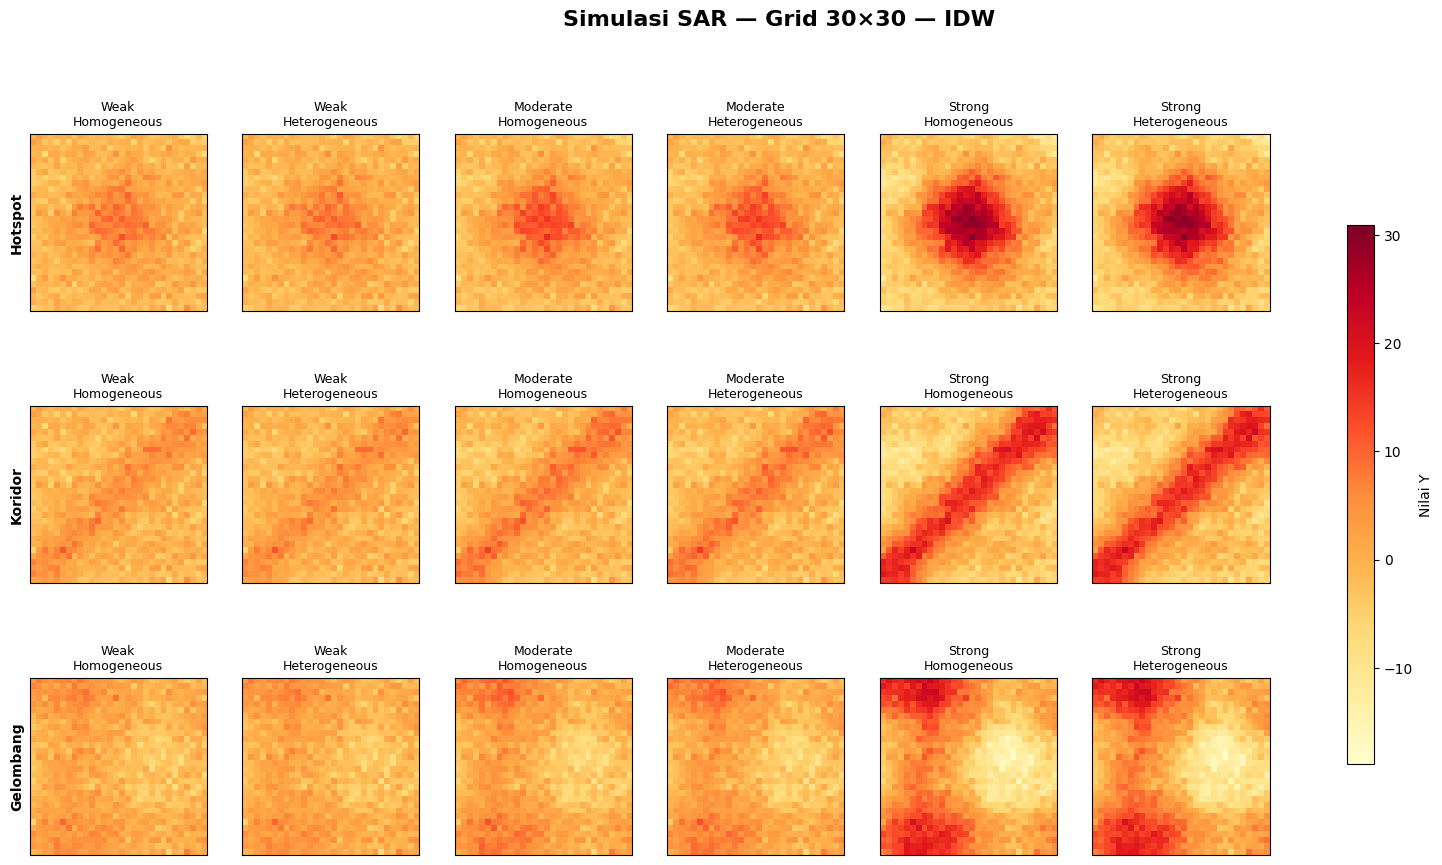



PEMBANGKITAN GRID 30×30 SELESAI
DATA_GRID30.csv
SUMMARY_GRID30.csv
W_KNN5_GRID30.npz
W_DISTANCE_GRID30.npz
W_IDW_GRID30.npz


In [17]:
# ============================================================
# ============================================================
# GRID 30 x 30
# CELL 1 — PEMBANGKITAN DATA SIMULASI
# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix, eye, save_npz
from scipy.sparse.linalg import factorized


# ============================================================
# 1. PENGATURAN GRID
# ============================================================

GRID_SIZE = 30
GRID_LABEL = "GRID30"

N = GRID_SIZE * GRID_SIZE


print("=" * 80)
print(f"PEMBANGKITAN DATA {GRID_LABEL}")
print("=" * 80)

print("Grid Size      :", GRID_SIZE, "x", GRID_SIZE)
print("Jumlah lokasi :", N)


# ============================================================
# 2. MEMBENTUK GRID SPASIAL
# ============================================================

x_coord = np.arange(
    1,
    GRID_SIZE + 1
)

y_coord = np.arange(
    1,
    GRID_SIZE + 1
)


xx, yy = np.meshgrid(
    x_coord,
    y_coord
)


grid = pd.DataFrame({

    "ID":
        np.arange(
            1,
            N + 1
        ),

    "X_coord":
        xx.ravel(),

    "Y_coord":
        yy.ravel()

})


# ============================================================
# 3. NORMALISASI KOORDINAT KE [0,1]
# ============================================================

grid["X_norm"] = (

    grid["X_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Y_norm"] = (

    grid["Y_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Grid_Size"] = GRID_SIZE
grid["N"] = N


# ============================================================
# 4. MEMBENTUK ZONA ERROR
# ============================================================

grid["Error_Zone"] = np.where(

    grid["X_norm"] <= 0.5,

    "A",

    "B"

)


print("\nJumlah lokasi per zona:")

display(
    grid["Error_Zone"].value_counts()
)


display(
    grid.head()
)


# ============================================================
# 5. FUNGSI STANDARDISASI POLA
# ============================================================

def standardize_pattern(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return (

        values
        -
        np.mean(values)

    ) / np.std(values)


# ============================================================
# 6. MEMBENTUK POLA SPASIAL
# ============================================================

x = grid["X_norm"].values
y = grid["Y_norm"].values


# ============================================================
# 6.1 HOTSPOT / POLA TERPUSAT
# ============================================================

TAU_H = 0.18


hotspot_raw = np.exp(

    -(

        (x - 0.5) ** 2

        +

        (y - 0.5) ** 2

    )

    /

    (
        2 * TAU_H ** 2
    )

)


hotspot = standardize_pattern(
    hotspot_raw
)


# ============================================================
# 6.2 KORIDOR
# ============================================================

TAU_C = 0.12


corridor_raw = np.exp(

    -(

        np.abs(
            y - x
        ) ** 2

    )

    /

    (
        2 * TAU_C ** 2
    )

)


corridor = standardize_pattern(
    corridor_raw
)


# ============================================================
# 6.3 GELOMBANG
# ============================================================

wave_raw = (

    np.sin(
        2 * np.pi * x
    )

    +

    0.7
    *
    np.cos(
        2 * np.pi * y
    )

)


wave = standardize_pattern(
    wave_raw
)


PATTERN_DICT = {

    "Hotspot":
        hotspot,

    "Koridor":
        corridor,

    "Gelombang":
        wave

}


# ============================================================
# 7. FUNGSI MEMBENTUK MATRIKS PLOT
# ============================================================

def pattern_to_matrix(values):

    temp = grid[
        [
            "X_coord",
            "Y_coord"
        ]
    ].copy()

    temp["value"] = values

    return temp.pivot(

        index="Y_coord",

        columns="X_coord",

        values="value"

    )


# ============================================================
# 8. VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(
    list(
        PATTERN_DICT.values()
    )
)


pattern_limit = np.max(
    np.abs(
        all_pattern_values
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):

    matrix = pattern_to_matrix(
        pattern_values
    )


    im = ax.imshow(

        matrix,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(
        pattern_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Koordinat X"
    )

    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Pola Prediktor Spasial — Grid 30×30",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# 9. MEMBANGKITKAN 19 PREDIKTOR RANDOM
# ============================================================

SEED_X = 2026


rng_X = np.random.default_rng(
    SEED_X
)


X_random = rng_X.normal(

    loc=0,

    scale=1,

    size=(
        N,
        19
    )

)


X_columns = [

    f"X{i}"

    for i in range(
        1,
        20
    )

]


X_df = pd.DataFrame(

    X_random,

    columns=X_columns

)


# ============================================================
# 10. FUNGSI NONLINEAR NON-SPASIAL
# ============================================================

non_spatial_signal = (

    2
    *
    np.sin(
        X_df["X1"].values
    )

    +

    0.5
    *
    (
        X_df["X2"].values ** 2
    )

    +

    (
        X_df["X3"].values

        *

        X_df["X4"].values
    )

    +

    X_df["X5"].values

)


# ============================================================
# 11. MEMBANGKITKAN ERROR DASAR
# ============================================================

SEED_ERROR = 2027


rng_error = np.random.default_rng(
    SEED_ERROR
)


z_error = rng_error.normal(

    loc=0,

    scale=1,

    size=N

)


# ============================================================
# 12. STRUKTUR VARIANS ERROR
# ============================================================

variance_homo = np.ones(
    N
)


variance_hetero = np.where(

    grid[
        "Error_Zone"
    ].values
    ==
    "A",

    0.5,

    1.5

)


error_homo = z_error.copy()


error_hetero = (

    np.sqrt(
        variance_hetero
    )

    *

    z_error

)


ERROR_DICT = {

    "Homogeneous":
        error_homo,

    "Heterogeneous":
        error_hetero

}


# ============================================================
# 13. KOORDINAT UNTUK W
# ============================================================

coordinates = grid[
    [
        "X_coord",
        "Y_coord"
    ]
].values


spatial_tree = cKDTree(
    coordinates
)


# ============================================================
# 14. FUNGSI ROW STANDARDIZATION
# ============================================================

def row_standardize_sparse(W):

    W = W.tocsr().astype(float)

    W.setdiag(0)

    W.eliminate_zeros()


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    if np.any(
        row_sum == 0
    ):

        raise ValueError(
            "Terdapat lokasi tanpa tetangga."
        )


    W_standardized = W.multiply(

        (
            1 / row_sum
        )[:, None]

    ).tocsr()


    return W_standardized


# ============================================================
# 15. W KNN-5
# ============================================================

K = 5


knn_distances, knn_indices = spatial_tree.query(

    coordinates,

    k=K + 1

)


knn_rows = np.repeat(

    np.arange(N),

    K

)


knn_cols = knn_indices[

    :,
    1:
].ravel()


knn_values = np.ones(
    len(
        knn_rows
    )
)


W_knn5_raw = csr_matrix(

    (

        knn_values,

        (
            knn_rows,
            knn_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_knn5 = row_standardize_sparse(
    W_knn5_raw
)


# ============================================================
# 16. W DISTANCE BAND
# ============================================================

DISTANCE_THRESHOLD = 1.5


distance_rows = []
distance_cols = []


distance_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=DISTANCE_THRESHOLD

)


for i, neighbors in enumerate(
    distance_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= DISTANCE_THRESHOLD
        ):

            distance_rows.append(i)

            distance_cols.append(j)


W_distance_raw = csr_matrix(

    (

        np.ones(
            len(
                distance_rows
            )
        ),

        (
            distance_rows,
            distance_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_distance = row_standardize_sparse(
    W_distance_raw
)


# ============================================================
# 17. W IDW
# ============================================================

IDW_RADIUS = 2.5
IDW_ALPHA = 1


idw_rows = []
idw_cols = []
idw_values = []


idw_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=IDW_RADIUS

)


for i, neighbors in enumerate(
    idw_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= IDW_RADIUS
        ):

            idw_rows.append(i)

            idw_cols.append(j)

            idw_values.append(

                1
                /
                (
                    distance_ij
                    **
                    IDW_ALPHA
                )

            )


W_idw_raw = csr_matrix(

    (

        idw_values,

        (
            idw_rows,
            idw_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_idw = row_standardize_sparse(
    W_idw_raw
)


# ============================================================
# DICTIONARY W
# ============================================================

W_RAW_DICT = {

    "KNN-5":
        W_knn5_raw,

    "Distance Band":
        W_distance_raw,

    "IDW":
        W_idw_raw

}


W_DICT = {

    "KNN-5":
        W_knn5,

    "Distance Band":
        W_distance,

    "IDW":
        W_idw

}


# ============================================================
# 18. PARAMETER RHO
# ============================================================

RHO_DICT = {

    "Weak":
        0.20,

    "Moderate":
        0.50,

    "Strong":
        0.80

}


# ============================================================
# 19. FUNGSI MORAN'S I
# ============================================================

def morans_I(
    values,
    W
):

    values = np.asarray(
        values,
        dtype=float
    )


    z = (

        values
        -
        np.mean(
            values
        )

    )


    n_obs = len(
        values
    )


    S0 = W.sum()


    numerator = (

        z

        @

        (
            W @ z
        )

    )


    denominator = (

        z

        @

        z

    )


    return float(

        (
            n_obs
            /
            S0
        )

        *

        (
            numerator
            /
            denominator
        )

    )


# ============================================================
# 20. MEMBUAT SOLVER SAR
# ============================================================

SAR_SOLVER_DICT = {}


for W_name, W in W_DICT.items():


    for strength_name, rho in RHO_DICT.items():


        A = (

            eye(
                N,
                format="csc"
            )

            -

            rho
            *
            W.tocsc()

        )


        SAR_SOLVER_DICT[

            (
                W_name,
                strength_name
            )

        ] = factorized(
            A
        )


# ============================================================
# 21. MEMBANGKITKAN SELURUH 54 SKENARIO
# ============================================================

scenario_summary_rows = []

simulation_rows = []

Y_SCENARIOS = {}


for pattern_name, spatial_predictor in PATTERN_DICT.items():


    g_X = (

        2
        *
        spatial_predictor

        +

        non_spatial_signal

    )


    for W_name, W in W_DICT.items():


        for strength_name, rho in RHO_DICT.items():


            sar_solver = SAR_SOLVER_DICT[

                (
                    W_name,
                    strength_name
                )

            ]


            for error_name, error_values in ERROR_DICT.items():


                scenario_id = (

                    f"G{GRID_SIZE}_"

                    f"{pattern_name.upper()}_"

                    f"{W_name.upper().replace(' ', '_').replace('-', '')}_"

                    f"{strength_name.upper()}_"

                    f"{error_name.upper()}"

                )


                rhs = (

                    g_X

                    +

                    error_values

                )


                Y_values = sar_solver(
                    rhs
                )


                moran_y = morans_I(

                    Y_values,

                    W

                )


                Y_SCENARIOS[
                    scenario_id
                ] = Y_values.copy()


                scenario_summary_rows.append({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Mean_Y":
                        np.mean(
                            Y_values
                        ),

                    "SD_Y":
                        np.std(
                            Y_values,
                            ddof=1
                        ),

                    "Moran_I_Y":
                        moran_y

                })


                temp = pd.DataFrame({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Location_ID":
                        grid[
                            "ID"
                        ].values,

                    "X_coord":
                        grid[
                            "X_coord"
                        ].values,

                    "Y_coord":
                        grid[
                            "Y_coord"
                        ].values,

                    "X_norm":
                        grid[
                            "X_norm"
                        ].values,

                    "Y_norm":
                        grid[
                            "Y_norm"
                        ].values,

                    "Error_Zone":
                        grid[
                            "Error_Zone"
                        ].values,

                    "X_spatial":
                        spatial_predictor,

                    "Error":
                        error_values,

                    "g_X":
                        g_X,

                    "Y":
                        Y_values

                })


                for col in X_columns:

                    temp[
                        col
                    ] = X_df[
                        col
                    ].values


                simulation_rows.append(
                    temp
                )


# ============================================================
# 22. GABUNGKAN SELURUH SKENARIO
# ============================================================

scenario_summary = pd.DataFrame(

    scenario_summary_rows

)


simulation_long = pd.concat(

    simulation_rows,

    ignore_index=True

)


# ============================================================
# 23. OBJEK AKHIR KHUSUS GRID 30
# ============================================================

DATA_GRID30 = simulation_long.copy()

SUMMARY_GRID30 = scenario_summary.copy()


# ============================================================
# 24. CEK HASIL PEMBANGKITAN
# ============================================================

print("\n")
print("=" * 80)
print("HASIL PEMBANGKITAN DATA GRID 30×30")
print("=" * 80)


print(
    "Grid              :",
    GRID_SIZE,
    "x",
    GRID_SIZE
)

print(
    "N                 :",
    N
)

print(
    "Jumlah skenario   :",
    DATA_GRID30[
        "Scenario_ID"
    ].nunique()
)

print(
    "Jumlah baris data :",
    len(
        DATA_GRID30
    )
)

print(
    "Lokasi/skenario   :",
    DATA_GRID30[
        "Location_ID"
    ].nunique()
)


print("=" * 80)


display(
    SUMMARY_GRID30.head()
)


display(
    DATA_GRID30.head()
)


# ============================================================
# 25. CEK 54 SKENARIO
# ============================================================

jumlah_skenario = (

    DATA_GRID30[

        [
            "Pattern",
            "W_Method",
            "Strength",
            "Rho",
            "Error_Structure"
        ]

    ]

    .drop_duplicates()

    .shape[0]

)


print(
    "\nJumlah kombinasi skenario =",
    jumlah_skenario
)


# ============================================================
# 26. VISUALISASI Y
# ============================================================

pattern_order = [

    "Hotspot",
    "Koridor",
    "Gelombang"

]


column_order = [

    ("Weak", "Homogeneous"),

    ("Weak", "Heterogeneous"),

    ("Moderate", "Homogeneous"),

    ("Moderate", "Heterogeneous"),

    ("Strong", "Homogeneous"),

    ("Strong", "Heterogeneous")

]


for W_name in W_DICT.keys():


    subset_W = DATA_GRID30[

        DATA_GRID30[
            "W_Method"
        ]
        ==
        W_name

    ]


    Y_min = subset_W[
        "Y"
    ].min()


    Y_max = subset_W[
        "Y"
    ].max()


    fig, axes = plt.subplots(

        3,
        6,

        figsize=(20, 10)

    )


    for row_index, pattern_name in enumerate(
        pattern_order
    ):


        for col_index, (
            strength_name,
            error_name
        ) in enumerate(
            column_order
        ):


            temp = subset_W[

                (
                    subset_W[
                        "Pattern"
                    ]
                    ==
                    pattern_name
                )

                &

                (
                    subset_W[
                        "Strength"
                    ]
                    ==
                    strength_name
                )

                &

                (
                    subset_W[
                        "Error_Structure"
                    ]
                    ==
                    error_name
                )

            ]


            matrix_Y = temp.pivot(

                index="Y_coord",

                columns="X_coord",

                values="Y"

            )


            im = axes[
                row_index,
                col_index
            ].imshow(

                matrix_Y,

                origin="lower",

                cmap="YlOrRd",

                vmin=Y_min,

                vmax=Y_max,

                aspect="equal"

            )


            axes[
                row_index,
                col_index
            ].set_title(

                f"{strength_name}\n"
                f"{error_name}",

                fontsize=9

            )


            if col_index == 0:

                axes[
                    row_index,
                    col_index
                ].set_ylabel(

                    pattern_name,

                    fontweight="bold"

                )


            axes[
                row_index,
                col_index
            ].set_xticks([])


            axes[
                row_index,
                col_index
            ].set_yticks([])


    fig.colorbar(

        im,

        ax=axes.ravel().tolist(),

        label="Nilai Y",

        shrink=0.7

    )


    fig.suptitle(

        f"Simulasi SAR — Grid 30×30 — {W_name}",

        fontsize=16,

        fontweight="bold"

    )


    plt.show()


# ============================================================
# 27. SIMPAN DATA GRID 30
# ============================================================

DATA_GRID30.to_csv(

    "DATA_GRID30.csv",

    index=False

)


SUMMARY_GRID30.to_csv(

    "SUMMARY_GRID30.csv",

    index=False

)


# ============================================================
# 28. SIMPAN MATRIKS W
# ============================================================

save_npz(

    "W_KNN5_GRID30.npz",

    W_knn5

)


save_npz(

    "W_DISTANCE_GRID30.npz",

    W_distance

)


save_npz(

    "W_IDW_GRID30.npz",

    W_idw

)


print("\n")
print("=" * 80)
print("PEMBANGKITAN GRID 30×30 SELESAI")
print("=" * 80)

print("DATA_GRID30.csv")
print("SUMMARY_GRID30.csv")
print("W_KNN5_GRID30.npz")
print("W_DISTANCE_GRID30.npz")
print("W_IDW_GRID30.npz")

print("=" * 80)

## VALIDASI DATA SIMULASI

VALIDASI DATA SIMULASI SPASIAL — GRID 30×30


1. VALIDASI WEAK - MODERATE - STRONG


,Grid_Size,Strength,Rho,Mean_Moran_I,SD_Moran_I,Min_Moran_I,Max_Moran_I,N_Scenario
2,30,Weak,0.2,0.5438,0.0231,0.5018,0.5805,18
0,30,Moderate,0.5,0.7442,0.0248,0.6937,0.7790,18
1,30,Strong,0.8,0.9175,0.0154,0.8855,0.9339,18


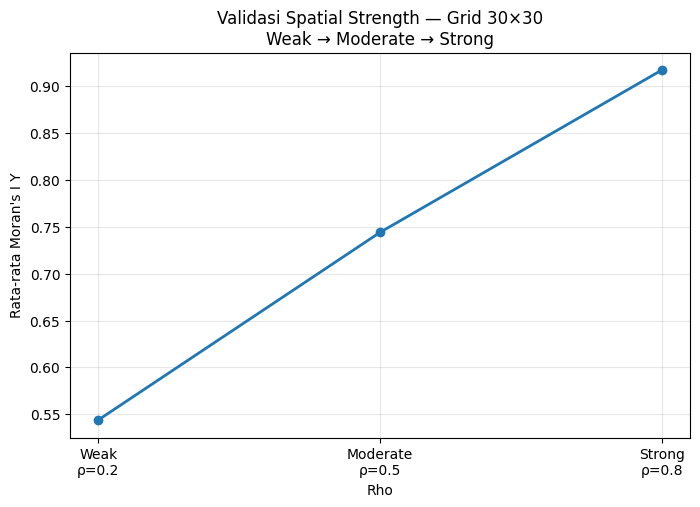


Apakah Mean Moran's I meningkat Weak < Moderate < Strong ?
True


2. MORAN'S I POLA SPASIAL


,Grid_Size,Pattern,W_Method,Moran_I_Pattern
0,30,Hotspot,KNN-5,0.9816
1,30,Hotspot,Distance Band,0.9777
2,30,Hotspot,IDW,0.9578
3,30,Koridor,KNN-5,0.9647
4,30,Koridor,Distance Band,0.9582
5,30,Koridor,IDW,0.9217
6,30,Gelombang,KNN-5,0.9843
7,30,Gelombang,Distance Band,0.9825
8,30,Gelombang,IDW,0.9676



RINGKASAN MORAN'S I POLA


,Grid_Size,Pattern,Mean_Moran_I,Min_Moran_I,Max_Moran_I
0,30,Gelombang,0.9781,0.9676,0.9843
1,30,Hotspot,0.9724,0.9578,0.9816
2,30,Koridor,0.9482,0.9217,0.9647


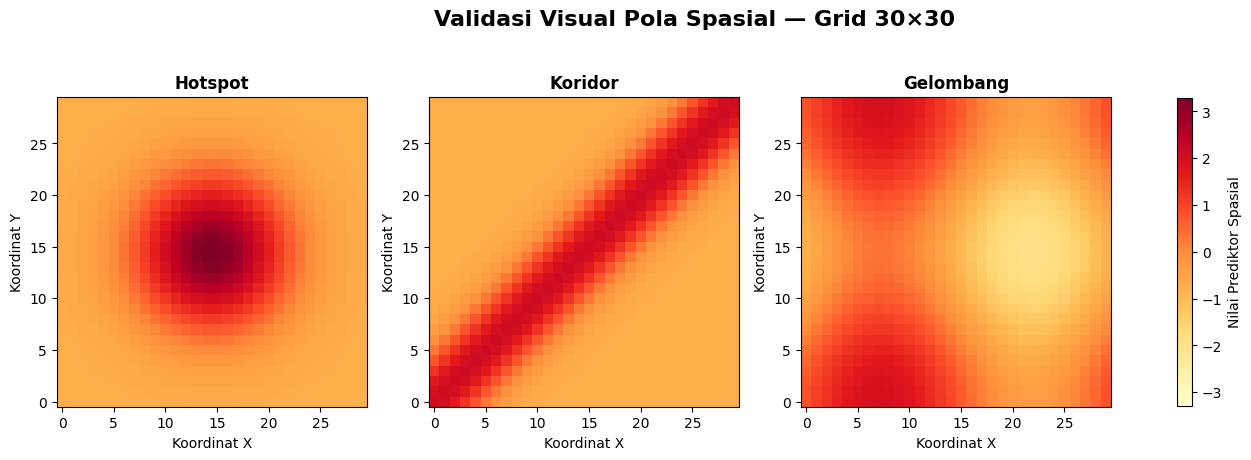



3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN
Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi
Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5
Breusch-Pagan digunakan sebagai diagnostik realisasi sampel.
H0 : Varians error konstan
H1 : Varians error tidak konstan
Alpha = 0.05


,Grid_Size,Error_Structure,Design,LM_Statistic,LM_pvalue,F_Statistic,F_pvalue,BP_Result,BP_Diagnostic
0,30,Homogeneous,Homoskedastis by construction,0.421993,0.515944,0.421253,0.516479,Fail to Reject H0,Tidak terdeteksi heteroskedastisitas pada real...
1,30,Heterogeneous,Heteroskedastis by construction,91.505366,0.000000,101.635577,0.000000,Reject H0,Terdeteksi heteroskedastisitas pada realisasi ini




VALIDASI DESAIN VARIANS
Homogeneous sigma² = 1             : True
Heterogeneous A=0.5 dan B=1.5     : True
Status desain error                : PASS


DIAGNOSTIK BREUSCH-PAGAN
p-value Homogeneous   : 0.515944
p-value Heterogeneous : 0.0
BP Homo   : sesuai dengan desain homoskedastis.
BP Hetero : heteroskedastisitas berhasil terdeteksi.


VARIANS ERROR SAMPEL PER ZONA


,Grid_Size,Zone,N,Mean_Error_Homo,Variance_Homogeneous,Mean_Error_Hetero,Variance_Heterogeneous
0,30,A,450,-0.0027,1.0875,-0.0019,0.5437
1,30,B,450,0.0290,1.1532,0.0356,1.7297


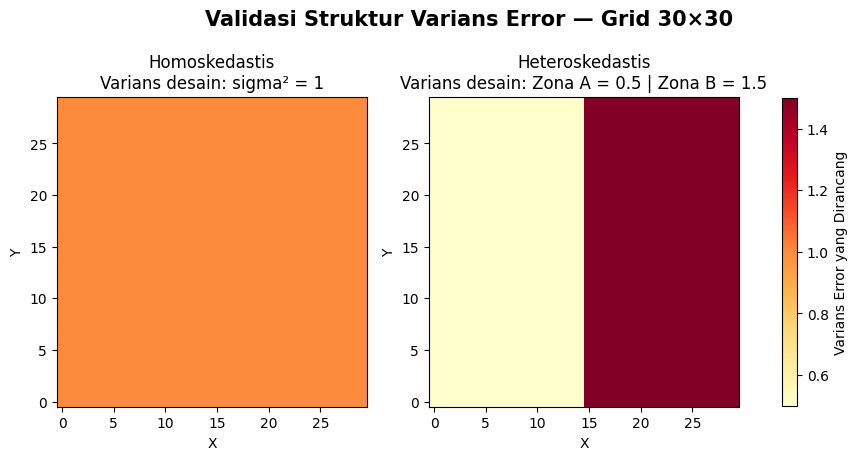



4. VALIDASI MATRIKS BOBOT W


,Grid_Size,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Min_Positive_Weight,Mean_Positive_Weight,Max_Positive_Weight,Min_Row_Sum,Max_Row_Sum,No_Self_Neighbor,Symmetric
0,30,KNN-5,5,5.0000,5,0.200,0.2000,0.2000,1.0,1.0,True,False
1,30,Distance Band,3,7.6044,8,0.125,0.1315,0.3333,1.0,1.0,True,False
2,30,IDW,7,18.5556,20,0.036,0.0539,0.2173,1.0,1.0,True,False


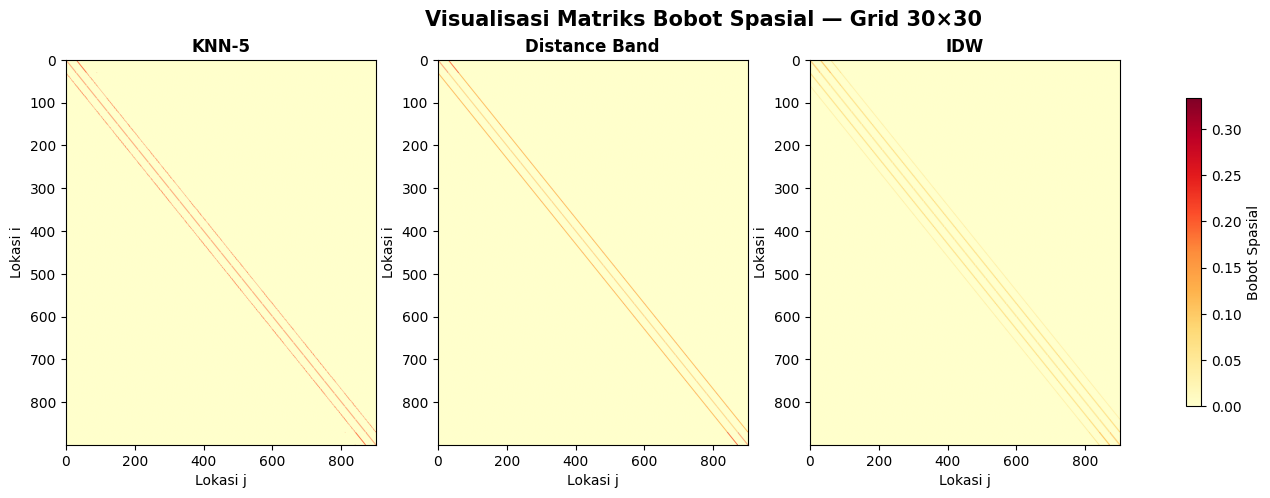

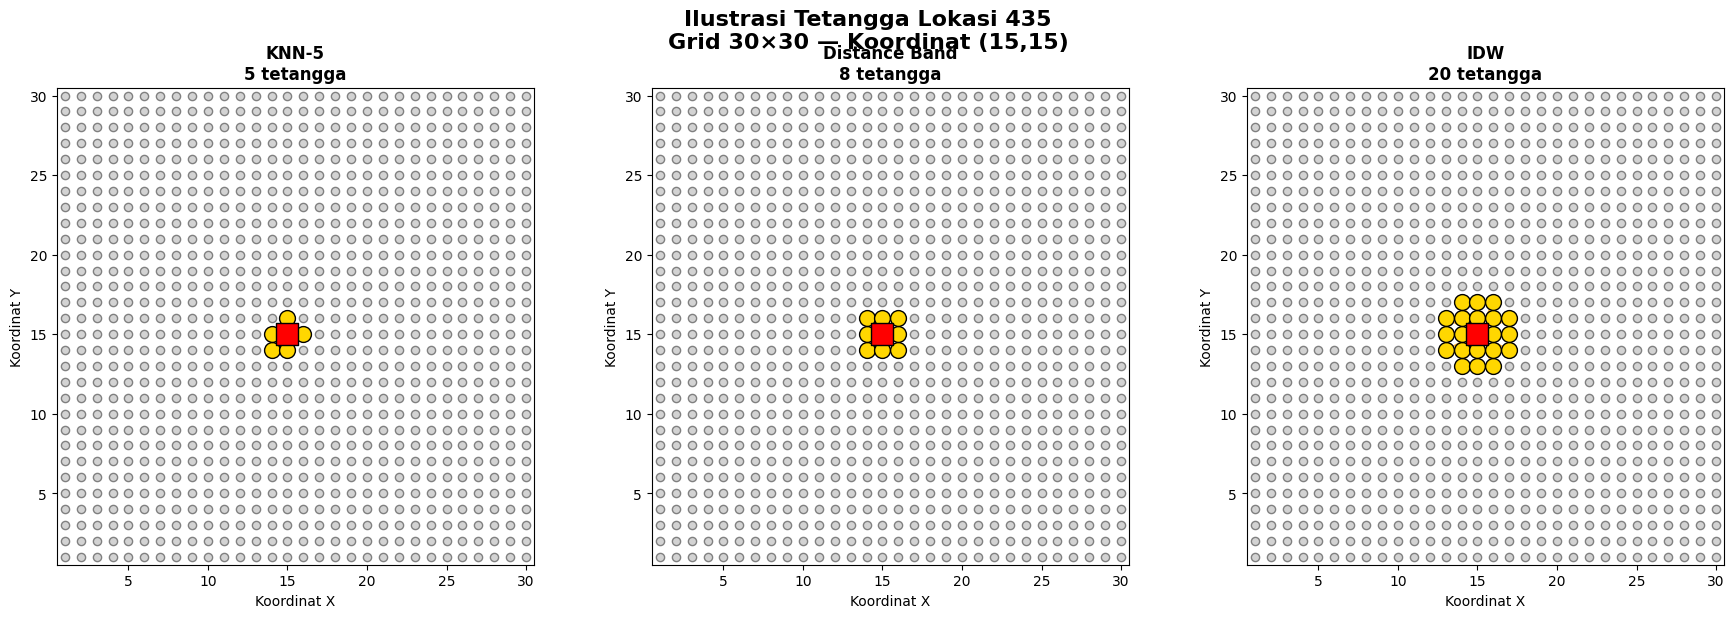



DETAIL TETANGGA LOKASI FOKUS


,Grid_Size,W_Method,Focus_ID,Neighbor_ID,Distance,Weight
6,30,Distance Band,435,405,1.0000,0.1250
8,30,Distance Band,435,434,1.0000,0.1250
9,30,Distance Band,435,436,1.0000,0.1250
11,30,Distance Band,435,465,1.0000,0.1250
5,30,Distance Band,435,404,1.4142,0.1250
7,30,Distance Band,435,406,1.4142,0.1250
10,30,Distance Band,435,464,1.4142,0.1250
12,30,Distance Band,435,466,1.4142,0.1250
18,30,IDW,435,405,1.0000,0.0806
22,30,IDW,435,434,1.0000,0.0806




TABEL VALIDASI FINAL SIMULASI — GRID 30×30


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,30,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,30,Pola spasial,Plot pola + Moran's I pola,PASS
2,30,Homo / Heteroskedastis,Desain varians + Breusch-Pagan diagnostik,PASS
3,30,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS




CEK OBJEK AKHIR GRID 30×30
DATA_GRID30                  : (48600, 37)
SUMMARY_GRID30               : (54, 11)
VALIDASI_GRID30              : (4, 4)
STRENGTH_VALIDATION_GRID30   : (3, 8)
PATTERN_VALIDATION_GRID30    : (9, 4)
BP_GRID30                    : (2, 9)
VARIANCE_GRID30              : (2, 7)
W_VALIDATION_GRID30          : (3, 12)
NEIGHBOR_GRID30              : (33, 6)

Jumlah skenario : 54
Jumlah baris    : 48600
✅ GRID 30×30: SEMUA VALIDASI PASS

FILE YANG TERSIMPAN:
DATA_GRID30.csv
SUMMARY_GRID30.csv
VALIDASI_FINAL_GRID30.csv
VALIDASI_STRENGTH_GRID30.csv
VALIDASI_POLA_GRID30.csv
RINGKASAN_POLA_GRID30.csv
VALIDASI_BREUSCH_PAGAN_GRID30.csv
VALIDASI_VARIANS_GRID30.csv
VALIDASI_W_GRID30.csv
DETAIL_TETANGGA_GRID30.csv
W_KNN5_GRID30.npz
W_DISTANCE_GRID30.npz
W_IDW_GRID30.npz


In [18]:
# ============================================================
# ============================================================
# GRID 30 x 30
# CELL 2 — VALIDASI DATA SIMULASI
# ============================================================
# ============================================================

import statsmodels.api as sm

from statsmodels.stats.diagnostic import het_breuschpagan


print("=" * 80)
print("VALIDASI DATA SIMULASI SPASIAL — GRID 30×30")
print("=" * 80)


# ============================================================
# VALIDASI 1
# WEAK / MODERATE / STRONG
# ============================================================

strength_validation = (

    SUMMARY_GRID30

    .groupby(
        [
            "Strength",
            "Rho"
        ]
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Y",
            "mean"
        ),

        SD_Moran_I=(
            "Moran_I_Y",
            "std"
        ),

        Min_Moran_I=(
            "Moran_I_Y",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Y",
            "max"
        ),

        N_Scenario=(
            "Moran_I_Y",
            "count"
        )

    )

    .reset_index()

)


strength_order = {

    "Weak": 1,
    "Moderate": 2,
    "Strong": 3

}


strength_validation["_order"] = (

    strength_validation[
        "Strength"
    ]

    .map(
        strength_order
    )

)


strength_validation = (

    strength_validation

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

)


strength_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("1. VALIDASI WEAK - MODERATE - STRONG")
print("=" * 80)


display(

    strength_validation.round(4)

)


# ============================================================
# PLOT STRENGTH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    strength_validation[
        "Rho"
    ],

    strength_validation[
        "Mean_Moran_I"
    ],

    marker="o",

    linewidth=2

)


plt.xlabel(
    "Rho"
)


plt.ylabel(
    "Rata-rata Moran's I Y"
)


plt.title(

    "Validasi Spatial Strength — Grid 30×30\n"
    "Weak → Moderate → Strong"

)


plt.xticks(

    [
        0.2,
        0.5,
        0.8
    ],

    [
        "Weak\nρ=0.2",
        "Moderate\nρ=0.5",
        "Strong\nρ=0.8"
    ]

)


plt.grid(
    alpha=0.3
)


plt.show()


# ============================================================
# CEK OTOMATIS STRENGTH
# ============================================================

mean_moran_weak = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Weak",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_moderate = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Moderate",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_strong = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Strong",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


strength_pass = (

    mean_moran_weak

    <

    mean_moran_moderate

    <

    mean_moran_strong

)


print(
    "\nApakah Mean Moran's I meningkat "
    "Weak < Moderate < Strong ?"
)


print(
    strength_pass
)


# ============================================================
# VALIDASI 2
# POLA SPASIAL
# ============================================================

pattern_moran_rows = []


for pattern_name, pattern_values in PATTERN_DICT.items():


    for W_name, W in W_DICT.items():


        I_pattern = morans_I(

            pattern_values,

            W

        )


        pattern_moran_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "Pattern":
                pattern_name,

            "W_Method":
                W_name,

            "Moran_I_Pattern":
                I_pattern

        })


pattern_moran_validation = pd.DataFrame(

    pattern_moran_rows

)


print("\n")
print("=" * 80)
print("2. MORAN'S I POLA SPASIAL")
print("=" * 80)


display(

    pattern_moran_validation.round(4)

)


# ============================================================
# RINGKASAN POLA
# ============================================================

pattern_summary_validation = (

    pattern_moran_validation

    .groupby(
        "Pattern"
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Pattern",
            "mean"
        ),

        Min_Moran_I=(
            "Moran_I_Pattern",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Pattern",
            "max"
        )

    )

    .reset_index()

)


pattern_summary_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print(
    "\nRINGKASAN MORAN'S I POLA"
)


display(

    pattern_summary_validation.round(4)

)


# ============================================================
# VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(

    list(
        PATTERN_DICT.values()
    )

)


pattern_limit = np.max(

    np.abs(
        all_pattern_values
    )

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):


    matrix_pattern = pattern_to_matrix(

        pattern_values

    )


    im = ax.imshow(

        matrix_pattern,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(

        pattern_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Validasi Visual Pola Spasial — Grid 30×30",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# ============================================================
# VALIDASI 3
# STRUKTUR VARIANS ERROR + BREUSCH-PAGAN
# ============================================================
# ============================================================

zone_dummy = (

    grid[
        "Error_Zone"
    ]

    ==
    "B"

).astype(int)


X_BP = sm.add_constant(
    zone_dummy
)


# ============================================================
# FUNGSI BREUSCH-PAGAN
# ============================================================

def run_breusch_pagan(

    residuals,

    exog,

    structure_name,

    design_name

):


    bp_result = het_breuschpagan(

        residuals,

        exog

    )


    LM_stat = bp_result[0]
    LM_pvalue = bp_result[1]

    F_stat = bp_result[2]
    F_pvalue = bp_result[3]


    if LM_pvalue < 0.05:

        bp_result_text = "Reject H0"

        bp_diagnostic = (
            "Terdeteksi heteroskedastisitas pada realisasi ini"
        )

    else:

        bp_result_text = "Fail to Reject H0"

        bp_diagnostic = (
            "Tidak terdeteksi heteroskedastisitas pada realisasi ini"
        )


    return {

        "Grid_Size":
            GRID_SIZE,

        "Error_Structure":
            structure_name,

        "Design":
            design_name,

        "LM_Statistic":
            LM_stat,

        "LM_pvalue":
            LM_pvalue,

        "F_Statistic":
            F_stat,

        "F_pvalue":
            F_pvalue,

        "BP_Result":
            bp_result_text,

        "BP_Diagnostic":
            bp_diagnostic

    }


BP_homo = run_breusch_pagan(

    residuals=
        error_homo,

    exog=
        X_BP,

    structure_name=
        "Homogeneous",

    design_name=
        "Homoskedastis by construction"

)


BP_hetero = run_breusch_pagan(

    residuals=
        error_hetero,

    exog=
        X_BP,

    structure_name=
        "Heterogeneous",

    design_name=
        "Heteroskedastis by construction"

)


BP_table = pd.DataFrame(

    [
        BP_homo,
        BP_hetero
    ]

)


print("\n")
print("=" * 80)
print("3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN")
print("=" * 80)


print(
    "Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi"
)

print(
    "Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5"
)

print(
    "Breusch-Pagan digunakan sebagai diagnostik realisasi sampel."
)

print(
    "H0 : Varians error konstan"
)

print(
    "H1 : Varians error tidak konstan"
)

print(
    "Alpha = 0.05"
)


display(
    BP_table.round(6)
)


# ============================================================
# VALIDASI DESAIN VARIANS
# ============================================================

design_homo_pass = np.allclose(

    variance_homo,

    1.0

)


design_hetero_pass = (

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "A"
        ],

        0.5

    )

    and

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "B"
        ],

        1.5

    )

)


error_design_pass = (

    design_homo_pass

    and

    design_hetero_pass

)


print("\n")
print("=" * 80)
print("VALIDASI DESAIN VARIANS")
print("=" * 80)


print(
    "Homogeneous sigma² = 1             :",
    design_homo_pass
)

print(
    "Heterogeneous A=0.5 dan B=1.5     :",
    design_hetero_pass
)

print(
    "Status desain error                :",
    (
        "PASS"
        if error_design_pass
        else
        "CHECK"
    )
)


# ============================================================
# HASIL BP SEBAGAI DIAGNOSTIK
# ============================================================

homo_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Homogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


hetero_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Heterogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


print("\n")
print("=" * 80)
print("DIAGNOSTIK BREUSCH-PAGAN")
print("=" * 80)


print(
    "p-value Homogeneous   :",
    round(
        homo_pvalue,
        6
    )
)

print(
    "p-value Heterogeneous :",
    round(
        hetero_pvalue,
        6
    )
)


if homo_pvalue >= 0.05:

    print(
        "BP Homo   : sesuai dengan desain homoskedastis."
    )

else:

    print(
        "BP Homo   : signifikan pada realisasi ini; "
        "dicatat sebagai diagnostik sampel."
    )


if hetero_pvalue < 0.05:

    print(
        "BP Hetero : heteroskedastisitas berhasil terdeteksi."
    )

else:

    print(
        "BP Hetero : heteroskedastisitas belum terdeteksi "
        "pada realisasi ini."
    )


# ============================================================
# VARIANS ERROR PER ZONA
# ============================================================

variance_check = pd.DataFrame({

    "Zone":
        grid[
            "Error_Zone"
        ],

    "Error_Homogeneous":
        error_homo,

    "Error_Heterogeneous":
        error_hetero

})


variance_zone_table = (

    variance_check

    .groupby(
        "Zone"
    )

    .agg(

        N=(
            "Error_Homogeneous",
            "count"
        ),

        Mean_Error_Homo=(
            "Error_Homogeneous",
            "mean"
        ),

        Variance_Homogeneous=(
            "Error_Homogeneous",
            "var"
        ),

        Mean_Error_Hetero=(
            "Error_Heterogeneous",
            "mean"
        ),

        Variance_Heterogeneous=(
            "Error_Heterogeneous",
            "var"
        )

    )

    .reset_index()

)


variance_zone_table.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("VARIANS ERROR SAMPEL PER ZONA")
print("=" * 80)


display(

    variance_zone_table.round(4)

)


# ============================================================
# VISUALISASI STRUKTUR VARIANS
# ============================================================

variance_homo_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_homo

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


variance_hetero_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_hetero

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


fig, axes = plt.subplots(

    1,
    2,

    figsize=(11, 5)

)


axes[0].imshow(

    variance_homo_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[0].set_title(

    "Homoskedastis\n"
    "Varians desain: sigma² = 1"

)


axes[0].set_xlabel(
    "X"
)

axes[0].set_ylabel(
    "Y"
)


im2 = axes[1].imshow(

    variance_hetero_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[1].set_title(

    "Heteroskedastis\n"
    "Varians desain: Zona A = 0.5 | Zona B = 1.5"

)


axes[1].set_xlabel(
    "X"
)

axes[1].set_ylabel(
    "Y"
)


fig.colorbar(

    im2,

    ax=axes.ravel().tolist(),

    label="Varians Error yang Dirancang",

    shrink=0.8

)


fig.suptitle(

    "Validasi Struktur Varians Error — Grid 30×30",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# VALIDASI 4
# MATRIKS BOBOT W
# ============================================================

W_validation_rows = []


for W_name, W in W_DICT.items():


    W_raw = W_RAW_DICT[
        W_name
    ].tocsr()


    W = W.tocsr()


    n_neighbors = np.diff(
        W_raw.indptr
    )


    positive_weights = W.data


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    diagonal_zero = np.allclose(

        W.diagonal(),

        0

    )


    W_difference = (

        W

        -

        W.T

    ).tocsr()


    if W_difference.nnz == 0:

        symmetric = True

    else:

        symmetric = (

            np.max(

                np.abs(
                    W_difference.data
                )

            )

            <

            1e-12

        )


    W_validation_rows.append({

        "Grid_Size":
            GRID_SIZE,

        "W_Method":
            W_name,

        "Min_Neighbor":
            np.min(
                n_neighbors
            ),

        "Mean_Neighbor":
            np.mean(
                n_neighbors
            ),

        "Max_Neighbor":
            np.max(
                n_neighbors
            ),

        "Min_Positive_Weight":
            np.min(
                positive_weights
            ),

        "Mean_Positive_Weight":
            np.mean(
                positive_weights
            ),

        "Max_Positive_Weight":
            np.max(
                positive_weights
            ),

        "Min_Row_Sum":
            np.min(
                row_sum
            ),

        "Max_Row_Sum":
            np.max(
                row_sum
            ),

        "No_Self_Neighbor":
            diagonal_zero,

        "Symmetric":
            symmetric

    })


W_validation_table = pd.DataFrame(

    W_validation_rows

)


print("\n")
print("=" * 80)
print("4. VALIDASI MATRIKS BOBOT W")
print("=" * 80)


display(

    W_validation_table.round(4)

)


# ============================================================
# HEATMAP W
# ============================================================

W_MAX = max(

    np.max(
        W.data
    )

    for W in W_DICT.values()

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    W_dense_plot = W.toarray()


    im = ax.imshow(

        W_dense_plot,

        cmap="YlOrRd",

        vmin=0,

        vmax=W_MAX,

        aspect="auto"

    )


    ax.set_title(

        W_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Lokasi j"
    )


    ax.set_ylabel(
        "Lokasi i"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Bobot Spasial",

    shrink=0.8

)


fig.suptitle(

    "Visualisasi Matriks Bobot Spasial — Grid 30×30",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# ILUSTRASI TETANGGA SATU LOKASI
# ============================================================

focus_x = GRID_SIZE // 2

focus_y = GRID_SIZE // 2


focus_idx = grid[

    (
        grid[
            "X_coord"
        ]
        ==
        focus_x
    )

    &

    (
        grid[
            "Y_coord"
        ]
        ==
        focus_y
    )

].index[0]


focus_id = int(

    grid.loc[
        focus_idx,
        "ID"
    ]

)


# ============================================================
# FUNGSI PLOT TETANGGA
# ============================================================

def plot_focus_neighbors(

    ax,

    W,

    method_name

):


    W_row = W.getrow(
        focus_idx
    )


    neighbors = W_row.indices


    ax.scatter(

        grid[
            "X_coord"
        ],

        grid[
            "Y_coord"
        ],

        s=35,

        color="lightgray",

        edgecolor="gray",

        zorder=1

    )


    for j in neighbors:


        weight = float(

            W[
                focus_idx,
                j
            ]

        )


        ax.plot(

            [
                grid.loc[
                    focus_idx,
                    "X_coord"
                ],

                grid.loc[
                    j,
                    "X_coord"
                ]
            ],

            [
                grid.loc[
                    focus_idx,
                    "Y_coord"
                ],

                grid.loc[
                    j,
                    "Y_coord"
                ]
            ],

            linewidth=

                1

                +

                10
                *
                weight,

            color="orange",

            alpha=0.8,

            zorder=2

        )


    ax.scatter(

        grid.loc[
            neighbors,
            "X_coord"
        ],

        grid.loc[
            neighbors,
            "Y_coord"
        ],

        s=130,

        color="gold",

        edgecolor="black",

        zorder=3

    )


    ax.scatter(

        grid.loc[
            focus_idx,
            "X_coord"
        ],

        grid.loc[
            focus_idx,
            "Y_coord"
        ],

        s=230,

        marker="s",

        color="red",

        edgecolor="black",

        zorder=4

    )


    ax.set_title(

        f"{method_name}\n"
        f"{len(neighbors)} tetangga",

        fontweight="bold"

    )


    ax.set_xlim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_ylim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


# ============================================================
# PLOT TETANGGA
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(18, 6)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    plot_focus_neighbors(

        ax,

        W,

        W_name

    )


fig.suptitle(

    f"Ilustrasi Tetangga Lokasi {focus_id}\n"
    f"Grid 30×30 — Koordinat ({focus_x},{focus_y})",

    fontsize=16,

    fontweight="bold"

)


plt.tight_layout()


plt.show()


# ============================================================
# DETAIL TETANGGA
# ============================================================

neighbor_rows = []


for W_name, W in W_DICT.items():


    neighbors = W.getrow(
        focus_idx
    ).indices


    for j in neighbors:


        distance_ij = np.linalg.norm(

            coordinates[
                focus_idx
            ]

            -

            coordinates[
                j
            ]

        )


        neighbor_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "W_Method":
                W_name,

            "Focus_ID":
                focus_id,

            "Neighbor_ID":
                int(
                    grid.loc[
                        j,
                        "ID"
                    ]
                ),

            "Distance":
                distance_ij,

            "Weight":
                float(
                    W[
                        focus_idx,
                        j
                    ]
                )

        })


neighbor_detail_table = pd.DataFrame(

    neighbor_rows

)


print("\n")
print("=" * 80)
print("DETAIL TETANGGA LOKASI FOKUS")
print("=" * 80)


display(

    neighbor_detail_table

    .sort_values(

        [
            "W_Method",
            "Distance",
            "Neighbor_ID"
        ]

    )

    .round(4)

)


# ============================================================
# TABEL VALIDASI FINAL
# ============================================================

pattern_pass = np.all(

    pattern_moran_validation[
        "Moran_I_Pattern"
    ]

    >
    0

)


W_pass = (

    np.allclose(

        W_validation_table[
            "Min_Row_Sum"
        ].values,

        1

    )

    and

    np.allclose(

        W_validation_table[
            "Max_Row_Sum"
        ].values,

        1

    )

    and

    (
        W_validation_table[
            "Min_Neighbor"
        ].min()
        >
        0
    )

    and

    W_validation_table[
        "No_Self_Neighbor"
    ].all()

)


validation_final = pd.DataFrame({

    "Grid_Size": [

        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE

    ],

    "Komponen": [

        "Weak / Moderate / Strong",

        "Pola spasial",

        "Homo / Heteroskedastis",

        "Spatial Weight Matrix"

    ],

    "Alat_Validasi": [

        "rho + Moran's I Y",

        "Plot pola + Moran's I pola",

        "Desain varians + Breusch-Pagan diagnostik",

        "Visualisasi W + statistik tetangga"

    ],

    "Hasil_Utama": [

        (
            "PASS"
            if strength_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if pattern_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if error_design_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if W_pass
            else
            "CHECK"
        )

    ]

})


# ============================================================
# OBJEK AKHIR KHUSUS GRID 30
# ============================================================

VALIDASI_GRID30 = validation_final.copy()


STRENGTH_VALIDATION_GRID30 = (

    strength_validation.copy()

)


PATTERN_VALIDATION_GRID30 = (

    pattern_moran_validation.copy()

)


PATTERN_SUMMARY_GRID30 = (

    pattern_summary_validation.copy()

)


BP_GRID30 = (

    BP_table.copy()

)


VARIANCE_GRID30 = (

    variance_zone_table.copy()

)


W_VALIDATION_GRID30 = (

    W_validation_table.copy()

)


NEIGHBOR_GRID30 = (

    neighbor_detail_table.copy()

)


# ============================================================
# TAMPILKAN VALIDASI FINAL
# ============================================================

print("\n")
print("=" * 80)
print("TABEL VALIDASI FINAL SIMULASI — GRID 30×30")
print("=" * 80)


display(

    VALIDASI_GRID30

)


# ============================================================
# SIMPAN SEMUA HASIL VALIDASI
# ============================================================

VALIDASI_GRID30.to_csv(

    "VALIDASI_FINAL_GRID30.csv",

    index=False

)


STRENGTH_VALIDATION_GRID30.to_csv(

    "VALIDASI_STRENGTH_GRID30.csv",

    index=False

)


PATTERN_VALIDATION_GRID30.to_csv(

    "VALIDASI_POLA_GRID30.csv",

    index=False

)


PATTERN_SUMMARY_GRID30.to_csv(

    "RINGKASAN_POLA_GRID30.csv",

    index=False

)


BP_GRID30.to_csv(

    "VALIDASI_BREUSCH_PAGAN_GRID30.csv",

    index=False

)


VARIANCE_GRID30.to_csv(

    "VALIDASI_VARIANS_GRID30.csv",

    index=False

)


W_VALIDATION_GRID30.to_csv(

    "VALIDASI_W_GRID30.csv",

    index=False

)


NEIGHBOR_GRID30.to_csv(

    "DETAIL_TETANGGA_GRID30.csv",

    index=False

)


# ============================================================
# CEK AKHIR SEMUA OBJEK
# ============================================================

print("\n")
print("=" * 80)
print("CEK OBJEK AKHIR GRID 30×30")
print("=" * 80)


print(
    "DATA_GRID30                  :",
    DATA_GRID30.shape
)

print(
    "SUMMARY_GRID30               :",
    SUMMARY_GRID30.shape
)

print(
    "VALIDASI_GRID30              :",
    VALIDASI_GRID30.shape
)

print(
    "STRENGTH_VALIDATION_GRID30   :",
    STRENGTH_VALIDATION_GRID30.shape
)

print(
    "PATTERN_VALIDATION_GRID30    :",
    PATTERN_VALIDATION_GRID30.shape
)

print(
    "BP_GRID30                    :",
    BP_GRID30.shape
)

print(
    "VARIANCE_GRID30              :",
    VARIANCE_GRID30.shape
)

print(
    "W_VALIDATION_GRID30          :",
    W_VALIDATION_GRID30.shape
)

print(
    "NEIGHBOR_GRID30              :",
    NEIGHBOR_GRID30.shape
)


print(
    "\nJumlah skenario :",
    DATA_GRID30[
        "Scenario_ID"
    ].nunique()
)


print(
    "Jumlah baris    :",
    len(
        DATA_GRID30
    )
)


print("=" * 80)


# ============================================================
# STATUS AKHIR
# ============================================================

if (

    VALIDASI_GRID30[
        "Hasil_Utama"
    ]

    ==
    "PASS"

).all():

    print(
        "✅ GRID 30×30: SEMUA VALIDASI PASS"
    )

else:

    print(
        "⚠️ GRID 30×30: ADA VALIDASI YANG PERLU DICEK"
    )


print("=" * 80)


print("\nFILE YANG TERSIMPAN:")

print("DATA_GRID30.csv")
print("SUMMARY_GRID30.csv")

print("VALIDASI_FINAL_GRID30.csv")
print("VALIDASI_STRENGTH_GRID30.csv")
print("VALIDASI_POLA_GRID30.csv")
print("RINGKASAN_POLA_GRID30.csv")
print("VALIDASI_BREUSCH_PAGAN_GRID30.csv")
print("VALIDASI_VARIANS_GRID30.csv")
print("VALIDASI_W_GRID30.csv")
print("DETAIL_TETANGGA_GRID30.csv")

print("W_KNN5_GRID30.npz")
print("W_DISTANCE_GRID30.npz")
print("W_IDW_GRID30.npz")

print("=" * 80)

# GRID 40 x 40

## PEMBANGKITAN DATA SIMULASI (N=1,600)

PEMBANGKITAN DATA GRID40
Grid Size      : 40 x 40
Jumlah lokasi : 1600

Jumlah lokasi per zona:


,count
Error_Zone,
A,800
B,800


,ID,X_coord,Y_coord,X_norm,Y_norm,Grid_Size,N,Error_Zone
0,1,1,1,0.000000,0.0,40,1600,A
1,2,2,1,0.025641,0.0,40,1600,A
2,3,3,1,0.051282,0.0,40,1600,A
3,4,4,1,0.076923,0.0,40,1600,A
4,5,5,1,0.102564,0.0,40,1600,A


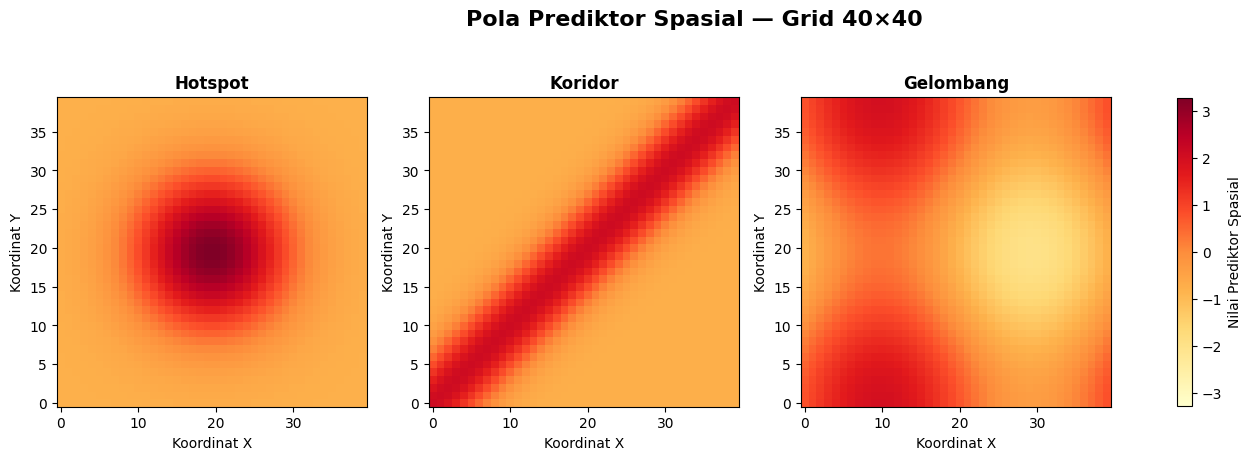



HASIL PEMBANGKITAN DATA GRID 40×40
Grid              : 40 x 40
N                 : 1600
Jumlah skenario   : 54
Jumlah baris data : 86400
Lokasi/skenario   : 1600


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Mean_Y,SD_Y,Moran_I_Y
0,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,0.624356,3.347946,0.574415
1,40,1600,G40_HOTSPOT_KNN5_WEAK_HETEROGENEOUS,Hotspot,KNN-5,Weak,0.2,Heterogeneous,0.636202,3.344675,0.577157
2,40,1600,G40_HOTSPOT_KNN5_MODERATE_HOMOGENEOUS,Hotspot,KNN-5,Moderate,0.5,Homogeneous,0.995304,4.624783,0.781089
3,40,1600,G40_HOTSPOT_KNN5_MODERATE_HETEROGENEOUS,Hotspot,KNN-5,Moderate,0.5,Heterogeneous,1.012425,4.625341,0.782967
4,40,1600,G40_HOTSPOT_KNN5_STRONG_HOMOGENEOUS,Hotspot,KNN-5,Strong,0.8,Homogeneous,2.487687,10.092807,0.943816


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
0,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
1,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
2,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
4,40,1600,G40_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260



Jumlah kombinasi skenario = 54


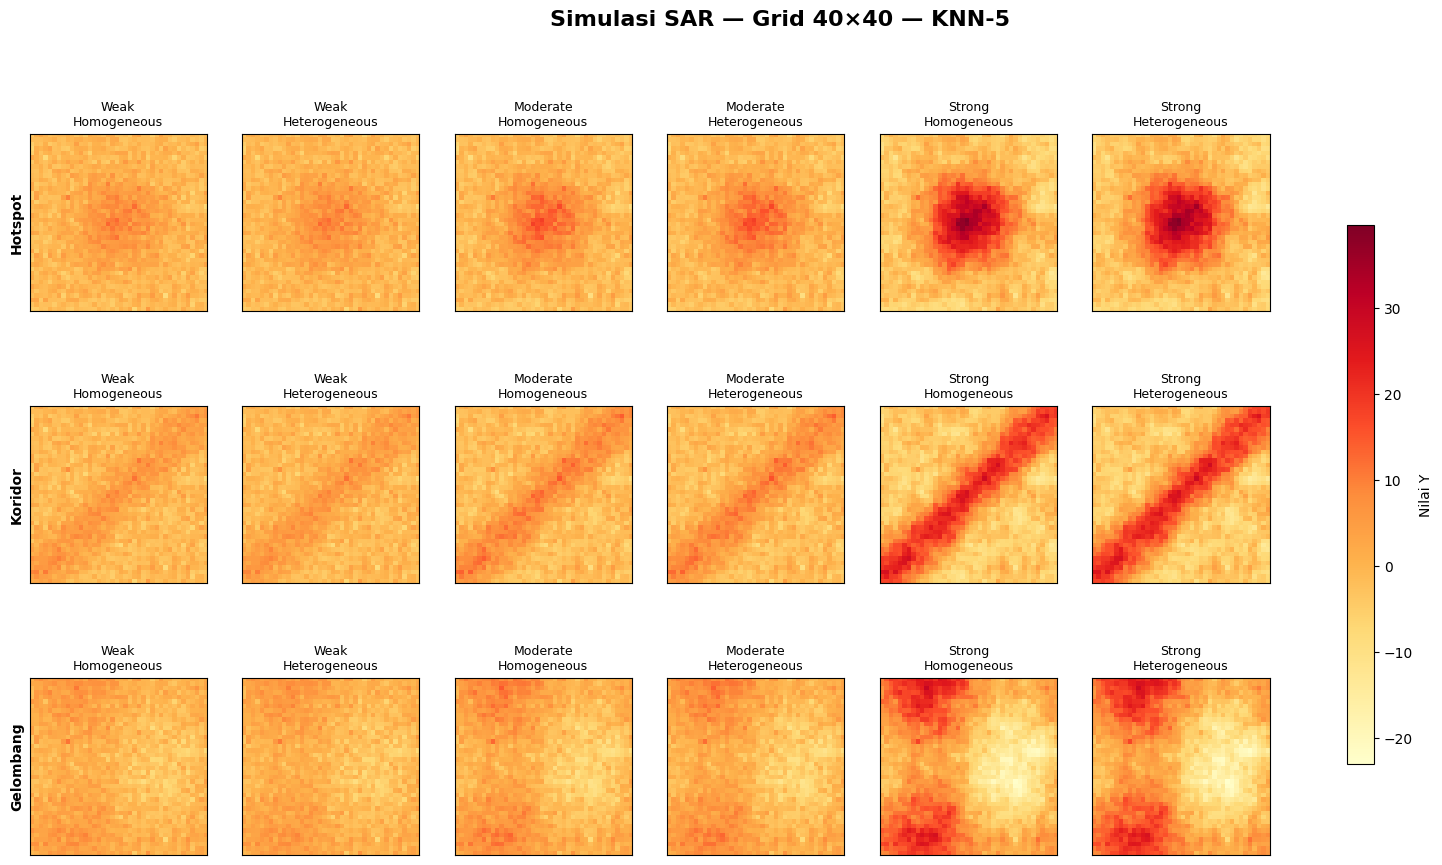

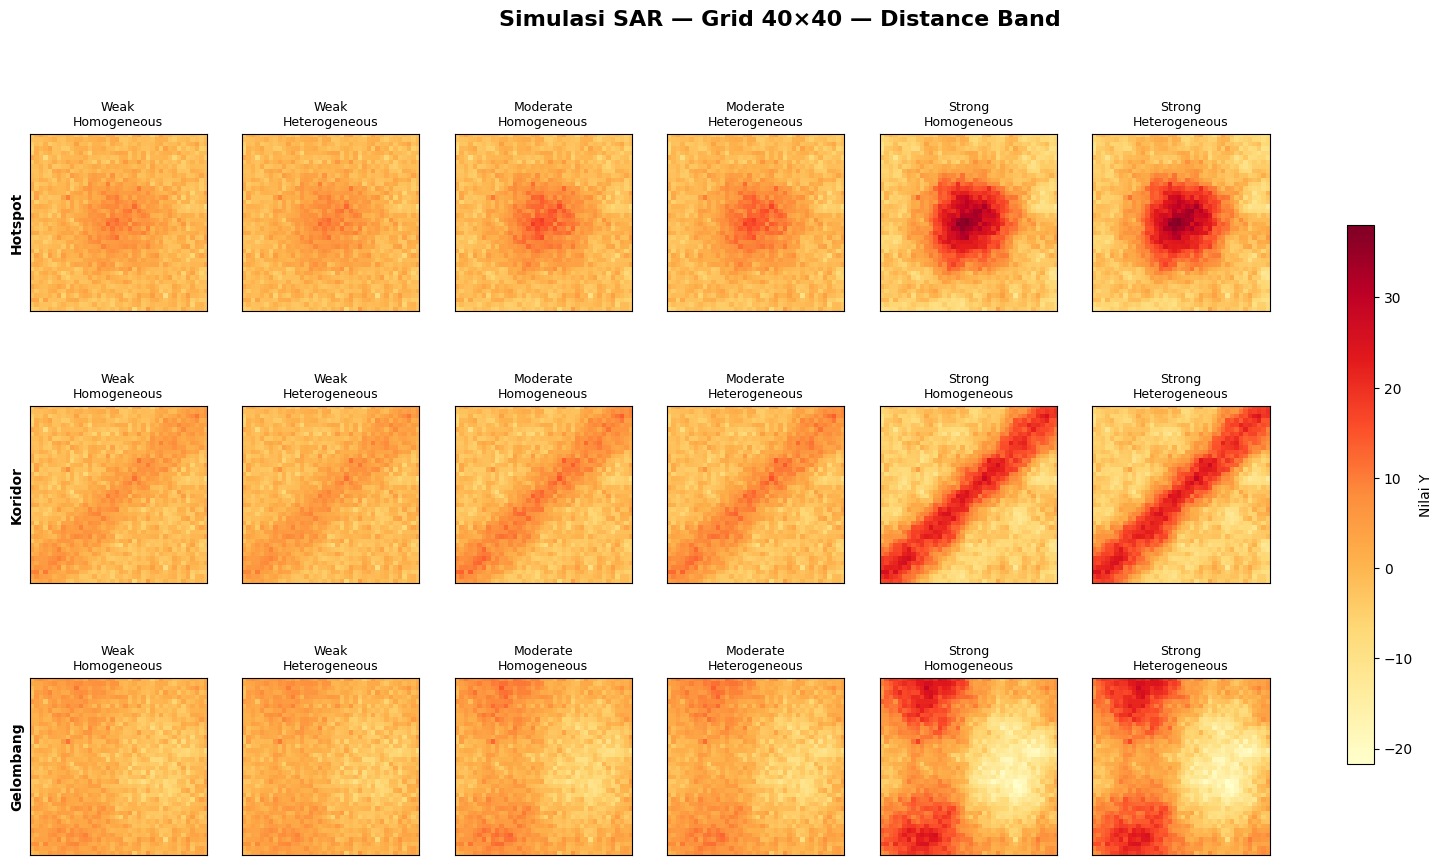

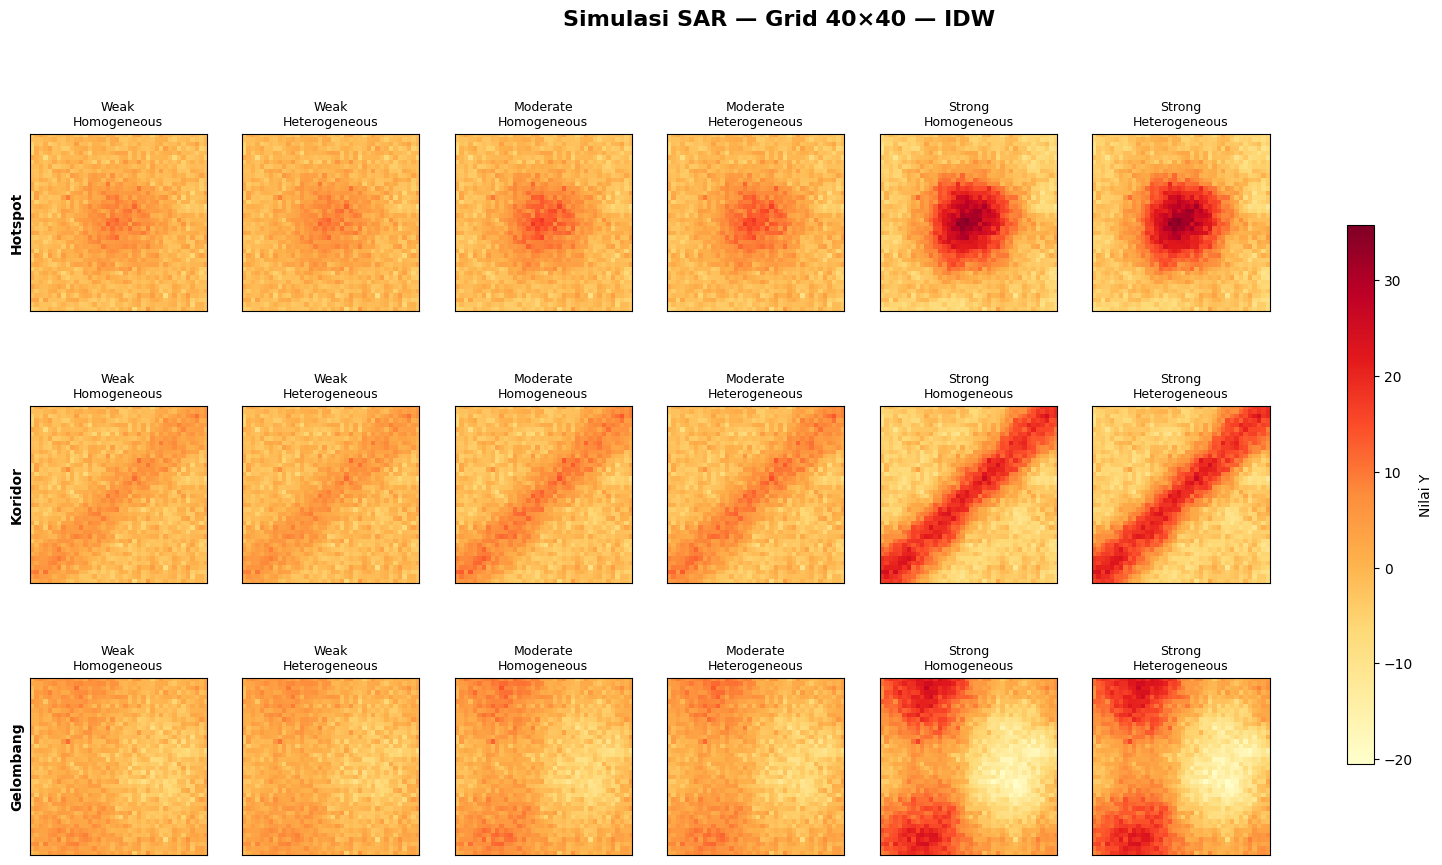



PEMBANGKITAN GRID 40×40 SELESAI
DATA_GRID40.csv
SUMMARY_GRID40.csv
W_KNN5_GRID40.npz
W_DISTANCE_GRID40.npz
W_IDW_GRID40.npz


In [19]:
# ============================================================
# ============================================================
# GRID 40 x 40
# CELL 1 — PEMBANGKITAN DATA SIMULASI
# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix, eye, save_npz
from scipy.sparse.linalg import factorized


# ============================================================
# 1. PENGATURAN GRID
# ============================================================

GRID_SIZE = 40
GRID_LABEL = "GRID40"

N = GRID_SIZE * GRID_SIZE


print("=" * 80)
print(f"PEMBANGKITAN DATA {GRID_LABEL}")
print("=" * 80)

print("Grid Size      :", GRID_SIZE, "x", GRID_SIZE)
print("Jumlah lokasi :", N)


# ============================================================
# 2. MEMBENTUK GRID SPASIAL
# ============================================================

x_coord = np.arange(1, GRID_SIZE + 1)
y_coord = np.arange(1, GRID_SIZE + 1)

xx, yy = np.meshgrid(
    x_coord,
    y_coord
)

grid = pd.DataFrame({
    "ID": np.arange(1, N + 1),
    "X_coord": xx.ravel(),
    "Y_coord": yy.ravel()
})


# ============================================================
# 3. NORMALISASI KOORDINAT KE [0,1]
# ============================================================

grid["X_norm"] = (
    grid["X_coord"] - 1
) / (
    GRID_SIZE - 1
)

grid["Y_norm"] = (
    grid["Y_coord"] - 1
) / (
    GRID_SIZE - 1
)

grid["Grid_Size"] = GRID_SIZE
grid["N"] = N


# ============================================================
# 4. MEMBENTUK ZONA ERROR
# ============================================================

grid["Error_Zone"] = np.where(
    grid["X_norm"] <= 0.5,
    "A",
    "B"
)

print("\nJumlah lokasi per zona:")

display(
    grid["Error_Zone"].value_counts()
)

display(
    grid.head()
)


# ============================================================
# 5. FUNGSI STANDARDISASI POLA
# ============================================================

def standardize_pattern(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return (
        values - np.mean(values)
    ) / np.std(values)


# ============================================================
# 6. MEMBENTUK POLA SPASIAL
# ============================================================

x = grid["X_norm"].values
y = grid["Y_norm"].values


# ============================================================
# 6.1 HOTSPOT
# ============================================================

TAU_H = 0.18

hotspot_raw = np.exp(
    -(
        (x - 0.5) ** 2
        +
        (y - 0.5) ** 2
    )
    /
    (
        2 * TAU_H ** 2
    )
)

hotspot = standardize_pattern(
    hotspot_raw
)


# ============================================================
# 6.2 KORIDOR
# ============================================================

TAU_C = 0.12

corridor_raw = np.exp(
    -(
        np.abs(
            y - x
        ) ** 2
    )
    /
    (
        2 * TAU_C ** 2
    )
)

corridor = standardize_pattern(
    corridor_raw
)


# ============================================================
# 6.3 GELOMBANG
# ============================================================

wave_raw = (
    np.sin(
        2 * np.pi * x
    )
    +
    0.7
    *
    np.cos(
        2 * np.pi * y
    )
)

wave = standardize_pattern(
    wave_raw
)


PATTERN_DICT = {
    "Hotspot": hotspot,
    "Koridor": corridor,
    "Gelombang": wave
}


# ============================================================
# 7. FUNGSI MEMBENTUK MATRIKS PLOT
# ============================================================

def pattern_to_matrix(values):

    temp = grid[
        [
            "X_coord",
            "Y_coord"
        ]
    ].copy()

    temp["value"] = values

    return temp.pivot(
        index="Y_coord",
        columns="X_coord",
        values="value"
    )


# ============================================================
# 8. VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(
    list(
        PATTERN_DICT.values()
    )
)

pattern_limit = np.max(
    np.abs(
        all_pattern_values
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    pattern_name,
    pattern_values
) in zip(
    axes,
    PATTERN_DICT.items()
):

    matrix = pattern_to_matrix(
        pattern_values
    )

    im = ax.imshow(
        matrix,
        origin="lower",
        cmap="YlOrRd",
        vmin=-pattern_limit,
        vmax=pattern_limit,
        aspect="equal"
    )

    ax.set_title(
        pattern_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Koordinat X"
    )

    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Nilai Prediktor Spasial",
    shrink=0.8
)


fig.suptitle(
    "Pola Prediktor Spasial — Grid 40×40",
    fontsize=16,
    fontweight="bold"
)


plt.show()


# ============================================================
# 9. MEMBANGKITKAN 19 PREDIKTOR RANDOM
# ============================================================

SEED_X = 2026

rng_X = np.random.default_rng(
    SEED_X
)

X_random = rng_X.normal(
    loc=0,
    scale=1,
    size=(
        N,
        19
    )
)

X_columns = [
    f"X{i}"
    for i in range(
        1,
        20
    )
]

X_df = pd.DataFrame(
    X_random,
    columns=X_columns
)


# ============================================================
# 10. FUNGSI NONLINEAR NON-SPASIAL
# ============================================================

non_spatial_signal = (
    2
    *
    np.sin(
        X_df["X1"].values
    )
    +
    0.5
    *
    (
        X_df["X2"].values ** 2
    )
    +
    (
        X_df["X3"].values
        *
        X_df["X4"].values
    )
    +
    X_df["X5"].values
)


# ============================================================
# 11. MEMBANGKITKAN ERROR DASAR
# ============================================================

SEED_ERROR = 2027

rng_error = np.random.default_rng(
    SEED_ERROR
)

z_error = rng_error.normal(
    loc=0,
    scale=1,
    size=N
)


# ============================================================
# 12. STRUKTUR VARIANS ERROR
# ============================================================

variance_homo = np.ones(
    N
)

variance_hetero = np.where(
    grid[
        "Error_Zone"
    ].values
    ==
    "A",
    0.5,
    1.5
)


error_homo = z_error.copy()


error_hetero = (
    np.sqrt(
        variance_hetero
    )
    *
    z_error
)


ERROR_DICT = {
    "Homogeneous": error_homo,
    "Heterogeneous": error_hetero
}


# ============================================================
# 13. KOORDINAT UNTUK W
# ============================================================

coordinates = grid[
    [
        "X_coord",
        "Y_coord"
    ]
].values


spatial_tree = cKDTree(
    coordinates
)


# ============================================================
# 14. FUNGSI ROW STANDARDIZATION
# ============================================================

def row_standardize_sparse(W):

    W = W.tocsr().astype(float)

    W.setdiag(0)

    W.eliminate_zeros()

    row_sum = np.asarray(
        W.sum(
            axis=1
        )
    ).ravel()

    if np.any(
        row_sum == 0
    ):
        raise ValueError(
            "Terdapat lokasi tanpa tetangga."
        )

    W_standardized = W.multiply(
        (
            1 / row_sum
        )[:, None]
    ).tocsr()

    return W_standardized


# ============================================================
# 15. W KNN-5
# ============================================================

K = 5


knn_distances, knn_indices = spatial_tree.query(
    coordinates,
    k=K + 1
)


knn_rows = np.repeat(
    np.arange(N),
    K
)


knn_cols = knn_indices[
    :,
    1:
].ravel()


knn_values = np.ones(
    len(
        knn_rows
    )
)


W_knn5_raw = csr_matrix(
    (
        knn_values,
        (
            knn_rows,
            knn_cols
        )
    ),
    shape=(
        N,
        N
    )
)


W_knn5 = row_standardize_sparse(
    W_knn5_raw
)


# ============================================================
# 16. W DISTANCE BAND
# ============================================================

DISTANCE_THRESHOLD = 1.5

distance_rows = []
distance_cols = []


distance_neighbors = spatial_tree.query_ball_point(
    coordinates,
    r=DISTANCE_THRESHOLD
)


for i, neighbors in enumerate(
    distance_neighbors
):

    for j in neighbors:

        if i == j:
            continue

        distance_ij = np.linalg.norm(
            coordinates[i]
            -
            coordinates[j]
        )

        if (
            distance_ij > 0
            and
            distance_ij <= DISTANCE_THRESHOLD
        ):

            distance_rows.append(i)
            distance_cols.append(j)


W_distance_raw = csr_matrix(
    (
        np.ones(
            len(
                distance_rows
            )
        ),
        (
            distance_rows,
            distance_cols
        )
    ),
    shape=(
        N,
        N
    )
)


W_distance = row_standardize_sparse(
    W_distance_raw
)


# ============================================================
# 17. W IDW
# ============================================================

IDW_RADIUS = 2.5
IDW_ALPHA = 1


idw_rows = []
idw_cols = []
idw_values = []


idw_neighbors = spatial_tree.query_ball_point(
    coordinates,
    r=IDW_RADIUS
)


for i, neighbors in enumerate(
    idw_neighbors
):

    for j in neighbors:

        if i == j:
            continue

        distance_ij = np.linalg.norm(
            coordinates[i]
            -
            coordinates[j]
        )

        if (
            distance_ij > 0
            and
            distance_ij <= IDW_RADIUS
        ):

            idw_rows.append(i)

            idw_cols.append(j)

            idw_values.append(
                1
                /
                (
                    distance_ij
                    **
                    IDW_ALPHA
                )
            )


W_idw_raw = csr_matrix(
    (
        idw_values,
        (
            idw_rows,
            idw_cols
        )
    ),
    shape=(
        N,
        N
    )
)


W_idw = row_standardize_sparse(
    W_idw_raw
)


# ============================================================
# DICTIONARY W
# ============================================================

W_RAW_DICT = {
    "KNN-5": W_knn5_raw,
    "Distance Band": W_distance_raw,
    "IDW": W_idw_raw
}


W_DICT = {
    "KNN-5": W_knn5,
    "Distance Band": W_distance,
    "IDW": W_idw
}


# ============================================================
# 18. PARAMETER RHO
# ============================================================

RHO_DICT = {
    "Weak": 0.20,
    "Moderate": 0.50,
    "Strong": 0.80
}


# ============================================================
# 19. FUNGSI MORAN'S I
# ============================================================

def morans_I(
    values,
    W
):

    values = np.asarray(
        values,
        dtype=float
    )

    z = (
        values
        -
        np.mean(
            values
        )
    )

    n_obs = len(
        values
    )

    S0 = W.sum()

    numerator = (
        z
        @
        (
            W @ z
        )
    )

    denominator = (
        z
        @
        z
    )

    return float(
        (
            n_obs
            /
            S0
        )
        *
        (
            numerator
            /
            denominator
        )
    )


# ============================================================
# 20. MEMBUAT SOLVER SAR
# ============================================================

SAR_SOLVER_DICT = {}


for W_name, W in W_DICT.items():

    for strength_name, rho in RHO_DICT.items():

        A = (
            eye(
                N,
                format="csc"
            )
            -
            rho
            *
            W.tocsc()
        )

        SAR_SOLVER_DICT[
            (
                W_name,
                strength_name
            )
        ] = factorized(
            A
        )


# ============================================================
# 21. MEMBANGKITKAN SELURUH 54 SKENARIO
# ============================================================

scenario_summary_rows = []

simulation_rows = []

Y_SCENARIOS = {}


for pattern_name, spatial_predictor in PATTERN_DICT.items():

    g_X = (
        2
        *
        spatial_predictor
        +
        non_spatial_signal
    )

    for W_name, W in W_DICT.items():

        for strength_name, rho in RHO_DICT.items():

            sar_solver = SAR_SOLVER_DICT[
                (
                    W_name,
                    strength_name
                )
            ]

            for error_name, error_values in ERROR_DICT.items():

                scenario_id = (
                    f"G{GRID_SIZE}_"
                    f"{pattern_name.upper()}_"
                    f"{W_name.upper().replace(' ', '_').replace('-', '')}_"
                    f"{strength_name.upper()}_"
                    f"{error_name.upper()}"
                )

                rhs = (
                    g_X
                    +
                    error_values
                )

                Y_values = sar_solver(
                    rhs
                )

                moran_y = morans_I(
                    Y_values,
                    W
                )


                Y_SCENARIOS[
                    scenario_id
                ] = Y_values.copy()


                scenario_summary_rows.append({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Mean_Y":
                        np.mean(
                            Y_values
                        ),

                    "SD_Y":
                        np.std(
                            Y_values,
                            ddof=1
                        ),

                    "Moran_I_Y":
                        moran_y

                })


                temp = pd.DataFrame({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Location_ID":
                        grid[
                            "ID"
                        ].values,

                    "X_coord":
                        grid[
                            "X_coord"
                        ].values,

                    "Y_coord":
                        grid[
                            "Y_coord"
                        ].values,

                    "X_norm":
                        grid[
                            "X_norm"
                        ].values,

                    "Y_norm":
                        grid[
                            "Y_norm"
                        ].values,

                    "Error_Zone":
                        grid[
                            "Error_Zone"
                        ].values,

                    "X_spatial":
                        spatial_predictor,

                    "Error":
                        error_values,

                    "g_X":
                        g_X,

                    "Y":
                        Y_values

                })


                for col in X_columns:

                    temp[
                        col
                    ] = X_df[
                        col
                    ].values


                simulation_rows.append(
                    temp
                )


# ============================================================
# 22. GABUNGKAN SELURUH SKENARIO
# ============================================================

scenario_summary = pd.DataFrame(
    scenario_summary_rows
)


simulation_long = pd.concat(
    simulation_rows,
    ignore_index=True
)


# ============================================================
# 23. OBJEK AKHIR KHUSUS GRID 40
# ============================================================

DATA_GRID40 = simulation_long.copy()

SUMMARY_GRID40 = scenario_summary.copy()


# ============================================================
# 24. CEK HASIL PEMBANGKITAN
# ============================================================

print("\n")
print("=" * 80)
print("HASIL PEMBANGKITAN DATA GRID 40×40")
print("=" * 80)


print(
    "Grid              :",
    GRID_SIZE,
    "x",
    GRID_SIZE
)

print(
    "N                 :",
    N
)

print(
    "Jumlah skenario   :",
    DATA_GRID40[
        "Scenario_ID"
    ].nunique()
)

print(
    "Jumlah baris data :",
    len(
        DATA_GRID40
    )
)

print(
    "Lokasi/skenario   :",
    DATA_GRID40[
        "Location_ID"
    ].nunique()
)

print("=" * 80)


display(
    SUMMARY_GRID40.head()
)

display(
    DATA_GRID40.head()
)


# ============================================================
# 25. CEK 54 SKENARIO
# ============================================================

jumlah_skenario = (
    DATA_GRID40[
        [
            "Pattern",
            "W_Method",
            "Strength",
            "Rho",
            "Error_Structure"
        ]
    ]
    .drop_duplicates()
    .shape[0]
)


print(
    "\nJumlah kombinasi skenario =",
    jumlah_skenario
)


# ============================================================
# 26. VISUALISASI Y
# ============================================================

pattern_order = [
    "Hotspot",
    "Koridor",
    "Gelombang"
]


column_order = [

    ("Weak", "Homogeneous"),

    ("Weak", "Heterogeneous"),

    ("Moderate", "Homogeneous"),

    ("Moderate", "Heterogeneous"),

    ("Strong", "Homogeneous"),

    ("Strong", "Heterogeneous")

]


for W_name in W_DICT.keys():

    subset_W = DATA_GRID40[
        DATA_GRID40[
            "W_Method"
        ]
        ==
        W_name
    ]


    Y_min = subset_W[
        "Y"
    ].min()


    Y_max = subset_W[
        "Y"
    ].max()


    fig, axes = plt.subplots(
        3,
        6,
        figsize=(20, 10)
    )


    for row_index, pattern_name in enumerate(
        pattern_order
    ):

        for col_index, (
            strength_name,
            error_name
        ) in enumerate(
            column_order
        ):

            temp = subset_W[
                (
                    subset_W[
                        "Pattern"
                    ]
                    ==
                    pattern_name
                )
                &
                (
                    subset_W[
                        "Strength"
                    ]
                    ==
                    strength_name
                )
                &
                (
                    subset_W[
                        "Error_Structure"
                    ]
                    ==
                    error_name
                )
            ]


            matrix_Y = temp.pivot(
                index="Y_coord",
                columns="X_coord",
                values="Y"
            )


            im = axes[
                row_index,
                col_index
            ].imshow(
                matrix_Y,
                origin="lower",
                cmap="YlOrRd",
                vmin=Y_min,
                vmax=Y_max,
                aspect="equal"
            )


            axes[
                row_index,
                col_index
            ].set_title(
                f"{strength_name}\n"
                f"{error_name}",
                fontsize=9
            )


            if col_index == 0:

                axes[
                    row_index,
                    col_index
                ].set_ylabel(
                    pattern_name,
                    fontweight="bold"
                )


            axes[
                row_index,
                col_index
            ].set_xticks([])


            axes[
                row_index,
                col_index
            ].set_yticks([])


    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        label="Nilai Y",
        shrink=0.7
    )


    fig.suptitle(
        f"Simulasi SAR — Grid 40×40 — {W_name}",
        fontsize=16,
        fontweight="bold"
    )


    plt.show()


# ============================================================
# 27. SIMPAN DATA GRID 40
# ============================================================

DATA_GRID40.to_csv(
    "DATA_GRID40.csv",
    index=False
)


SUMMARY_GRID40.to_csv(
    "SUMMARY_GRID40.csv",
    index=False
)


# ============================================================
# 28. SIMPAN MATRIKS W
# ============================================================

save_npz(
    "W_KNN5_GRID40.npz",
    W_knn5
)


save_npz(
    "W_DISTANCE_GRID40.npz",
    W_distance
)


save_npz(
    "W_IDW_GRID40.npz",
    W_idw
)


print("\n")
print("=" * 80)
print("PEMBANGKITAN GRID 40×40 SELESAI")
print("=" * 80)

print("DATA_GRID40.csv")
print("SUMMARY_GRID40.csv")
print("W_KNN5_GRID40.npz")
print("W_DISTANCE_GRID40.npz")
print("W_IDW_GRID40.npz")

print("=" * 80)

## VALIDASI DATA SIMULASI

VALIDASI DATA SIMULASI SPASIAL — GRID 40×40


1. VALIDASI WEAK - MODERATE - STRONG


,Grid_Size,Strength,Rho,Mean_Moran_I,SD_Moran_I,Min_Moran_I,Max_Moran_I,N_Scenario
2,40,Weak,0.2,0.5661,0.0181,0.5386,0.5964,18
0,40,Moderate,0.5,0.7678,0.0200,0.7320,0.7971,18
1,40,Strong,0.8,0.9349,0.0127,0.9095,0.9512,18


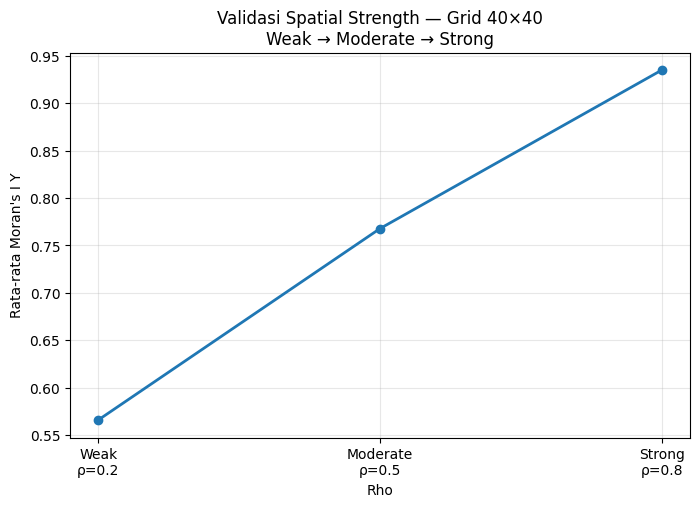


Apakah Mean Moran's I meningkat Weak < Moderate < Strong ?
True


2. MORAN'S I POLA SPASIAL


,Grid_Size,Pattern,W_Method,Moran_I_Pattern
0,40,Hotspot,KNN-5,0.9901
1,40,Hotspot,Distance Band,0.9875
2,40,Hotspot,IDW,0.9763
3,40,Koridor,KNN-5,0.9809
4,40,Koridor,Distance Band,0.9765
5,40,Koridor,IDW,0.9554
6,40,Gelombang,KNN-5,0.9925
7,40,Gelombang,Distance Band,0.9903
8,40,Gelombang,IDW,0.9819



RINGKASAN MORAN'S I POLA


,Grid_Size,Pattern,Mean_Moran_I,Min_Moran_I,Max_Moran_I
0,40,Gelombang,0.9882,0.9819,0.9925
1,40,Hotspot,0.9846,0.9763,0.9901
2,40,Koridor,0.9709,0.9554,0.9809


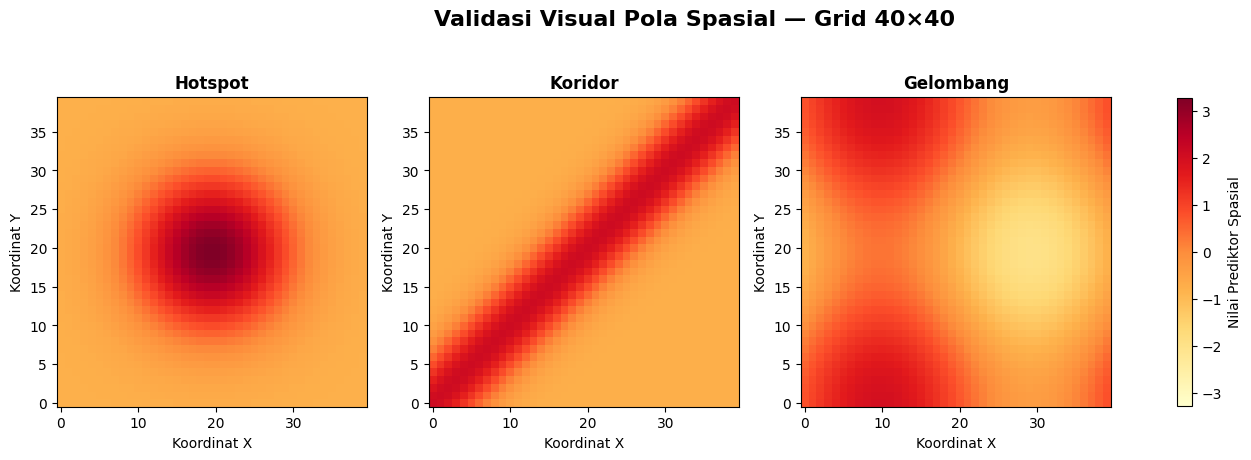



3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN
Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi
Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5
Breusch-Pagan digunakan sebagai diagnostik realisasi sampel.
H0 : Varians error konstan
H1 : Varians error tidak konstan
Alpha = 0.05


,Grid_Size,Error_Structure,Design,LM_Statistic,LM_pvalue,F_Statistic,F_pvalue,BP_Result,BP_Diagnostic
0,40,Homogeneous,Homoskedastis by construction,0.003171,0.955095,0.003167,0.95513,Fail to Reject H0,Tidak terdeteksi heteroskedastisitas pada real...
1,40,Heterogeneous,Heteroskedastis by construction,156.162736,0.000000,172.836689,0.00000,Reject H0,Terdeteksi heteroskedastisitas pada realisasi ini




VALIDASI DESAIN VARIANS
Homogeneous sigma² = 1             : True
Heterogeneous A=0.5 dan B=1.5     : True
Status desain error                : PASS


DIAGNOSTIK BREUSCH-PAGAN
p-value Homogeneous   : 0.955095
p-value Heterogeneous : 0.0
BP Homo   : sesuai dengan desain homoskedastis.
BP Hetero : heteroskedastisitas berhasil terdeteksi.


VARIANS ERROR SAMPEL PER ZONA


,Grid_Size,Zone,N,Mean_Error_Homo,Variance_Homogeneous,Mean_Error_Hetero,Variance_Heterogeneous
0,40,A,800,-0.0320,1.0509,-0.0226,0.5255
1,40,B,800,0.0474,1.0457,0.0580,1.5686


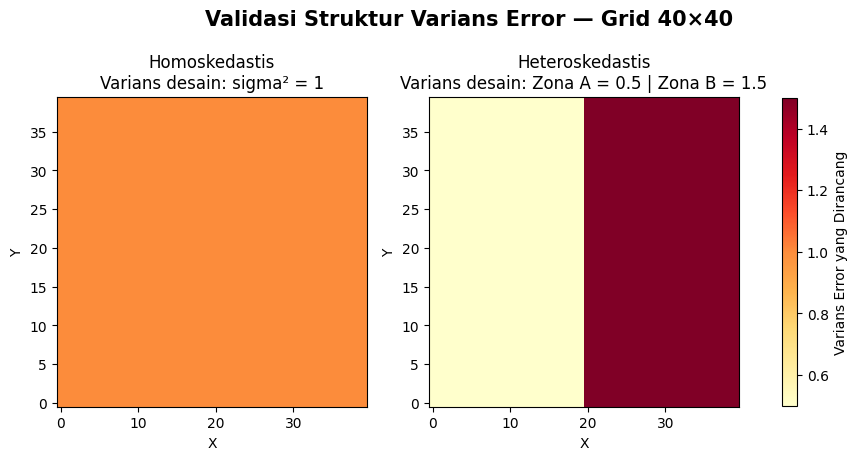



4. VALIDASI MATRIKS BOBOT W


,Grid_Size,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Min_Positive_Weight,Mean_Positive_Weight,Max_Positive_Weight,Min_Row_Sum,Max_Row_Sum,No_Self_Neighbor,Symmetric
0,40,KNN-5,5,5.0000,5,0.200,0.2000,0.2000,1.0,1.0,True,False
1,40,Distance Band,3,7.7025,8,0.125,0.1298,0.3333,1.0,1.0,True,False
2,40,IDW,7,18.9125,20,0.036,0.0529,0.2173,1.0,1.0,True,False


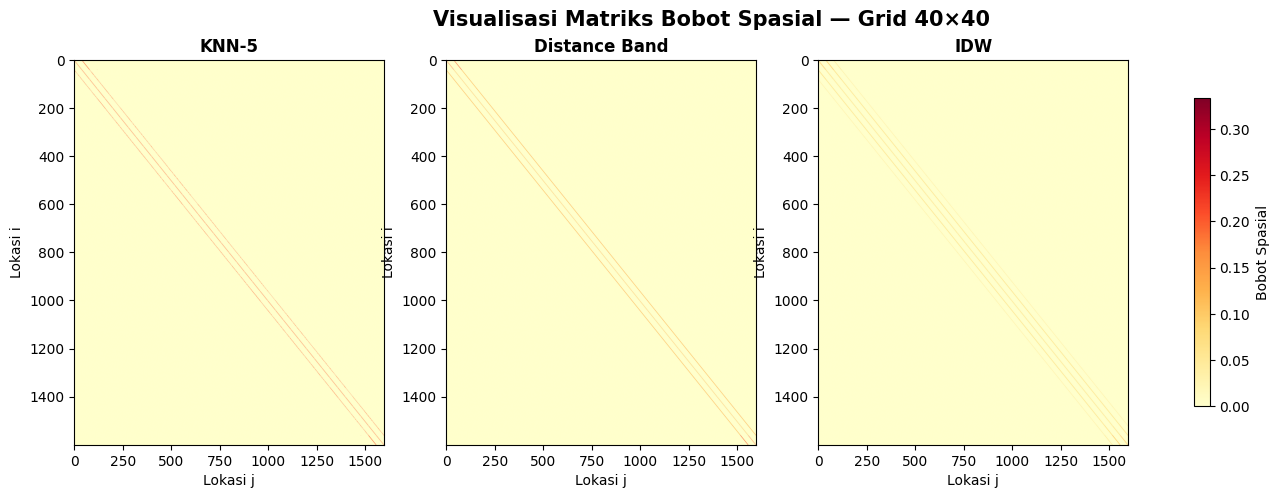

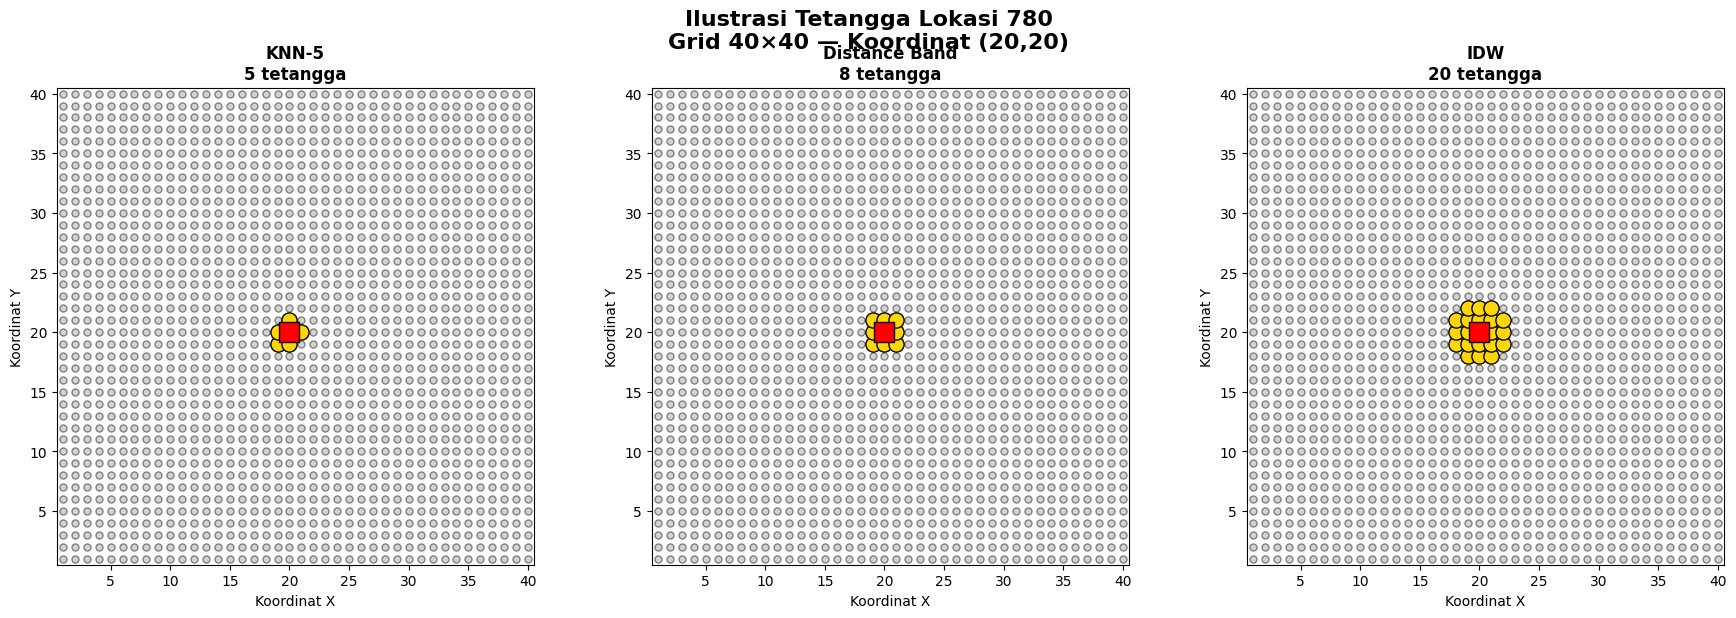



DETAIL TETANGGA LOKASI FOKUS


,Grid_Size,W_Method,Focus_ID,Neighbor_ID,Distance,Weight
6,40,Distance Band,780,740,1.0000,0.1250
8,40,Distance Band,780,779,1.0000,0.1250
9,40,Distance Band,780,781,1.0000,0.1250
11,40,Distance Band,780,820,1.0000,0.1250
5,40,Distance Band,780,739,1.4142,0.1250
7,40,Distance Band,780,741,1.4142,0.1250
10,40,Distance Band,780,819,1.4142,0.1250
12,40,Distance Band,780,821,1.4142,0.1250
18,40,IDW,780,740,1.0000,0.0806
22,40,IDW,780,779,1.0000,0.0806




TABEL VALIDASI FINAL SIMULASI — GRID 40×40


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,40,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,40,Pola spasial,Plot pola + Moran's I pola,PASS
2,40,Homo / Heteroskedastis,Desain varians + Breusch-Pagan diagnostik,PASS
3,40,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS




CEK OBJEK AKHIR GRID 40×40
DATA_GRID40                  : (86400, 37)
SUMMARY_GRID40               : (54, 11)
VALIDASI_GRID40              : (4, 4)
STRENGTH_VALIDATION_GRID40   : (3, 8)
PATTERN_VALIDATION_GRID40    : (9, 4)
BP_GRID40                    : (2, 9)
VARIANCE_GRID40              : (2, 7)
W_VALIDATION_GRID40          : (3, 12)
NEIGHBOR_GRID40              : (33, 6)

Jumlah skenario : 54
Jumlah baris    : 86400
✅ GRID 40×40: SEMUA VALIDASI PASS

FILE YANG TERSIMPAN:
DATA_GRID40.csv
SUMMARY_GRID40.csv
VALIDASI_FINAL_GRID40.csv
VALIDASI_STRENGTH_GRID40.csv
VALIDASI_POLA_GRID40.csv
RINGKASAN_POLA_GRID40.csv
VALIDASI_BREUSCH_PAGAN_GRID40.csv
VALIDASI_VARIANS_GRID40.csv
VALIDASI_W_GRID40.csv
DETAIL_TETANGGA_GRID40.csv
W_KNN5_GRID40.npz
W_DISTANCE_GRID40.npz
W_IDW_GRID40.npz


In [20]:
# ============================================================
# ============================================================
# GRID 40 x 40
# CELL 2 — VALIDASI DATA SIMULASI
# ============================================================
# ============================================================

import statsmodels.api as sm

from statsmodels.stats.diagnostic import het_breuschpagan


print("=" * 80)
print("VALIDASI DATA SIMULASI SPASIAL — GRID 40×40")
print("=" * 80)


# ============================================================
# VALIDASI 1
# WEAK / MODERATE / STRONG
# ============================================================

strength_validation = (

    SUMMARY_GRID40

    .groupby(
        [
            "Strength",
            "Rho"
        ]
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Y",
            "mean"
        ),

        SD_Moran_I=(
            "Moran_I_Y",
            "std"
        ),

        Min_Moran_I=(
            "Moran_I_Y",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Y",
            "max"
        ),

        N_Scenario=(
            "Moran_I_Y",
            "count"
        )

    )

    .reset_index()

)


strength_order = {
    "Weak": 1,
    "Moderate": 2,
    "Strong": 3
}


strength_validation["_order"] = (
    strength_validation[
        "Strength"
    ]
    .map(
        strength_order
    )
)


strength_validation = (
    strength_validation
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
)


strength_validation.insert(
    0,
    "Grid_Size",
    GRID_SIZE
)


print("\n")
print("=" * 80)
print("1. VALIDASI WEAK - MODERATE - STRONG")
print("=" * 80)


display(
    strength_validation.round(4)
)


# ============================================================
# PLOT STRENGTH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(
    strength_validation[
        "Rho"
    ],
    strength_validation[
        "Mean_Moran_I"
    ],
    marker="o",
    linewidth=2
)


plt.xlabel(
    "Rho"
)


plt.ylabel(
    "Rata-rata Moran's I Y"
)


plt.title(
    "Validasi Spatial Strength — Grid 40×40\n"
    "Weak → Moderate → Strong"
)


plt.xticks(
    [
        0.2,
        0.5,
        0.8
    ],
    [
        "Weak\nρ=0.2",
        "Moderate\nρ=0.5",
        "Strong\nρ=0.8"
    ]
)


plt.grid(
    alpha=0.3
)


plt.show()


# ============================================================
# CEK OTOMATIS STRENGTH
# ============================================================

mean_moran_weak = (
    strength_validation.loc[
        strength_validation[
            "Strength"
        ]
        ==
        "Weak",
        "Mean_Moran_I"
    ]
    .iloc[0]
)


mean_moran_moderate = (
    strength_validation.loc[
        strength_validation[
            "Strength"
        ]
        ==
        "Moderate",
        "Mean_Moran_I"
    ]
    .iloc[0]
)


mean_moran_strong = (
    strength_validation.loc[
        strength_validation[
            "Strength"
        ]
        ==
        "Strong",
        "Mean_Moran_I"
    ]
    .iloc[0]
)


strength_pass = (
    mean_moran_weak
    <
    mean_moran_moderate
    <
    mean_moran_strong
)


print(
    "\nApakah Mean Moran's I meningkat "
    "Weak < Moderate < Strong ?"
)


print(
    strength_pass
)


# ============================================================
# VALIDASI 2
# POLA SPASIAL
# ============================================================

pattern_moran_rows = []


for pattern_name, pattern_values in PATTERN_DICT.items():

    for W_name, W in W_DICT.items():

        I_pattern = morans_I(
            pattern_values,
            W
        )

        pattern_moran_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "Pattern":
                pattern_name,

            "W_Method":
                W_name,

            "Moran_I_Pattern":
                I_pattern

        })


pattern_moran_validation = pd.DataFrame(
    pattern_moran_rows
)


print("\n")
print("=" * 80)
print("2. MORAN'S I POLA SPASIAL")
print("=" * 80)


display(
    pattern_moran_validation.round(4)
)


# ============================================================
# RINGKASAN POLA
# ============================================================

pattern_summary_validation = (

    pattern_moran_validation

    .groupby(
        "Pattern"
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Pattern",
            "mean"
        ),

        Min_Moran_I=(
            "Moran_I_Pattern",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Pattern",
            "max"
        )

    )

    .reset_index()

)


pattern_summary_validation.insert(
    0,
    "Grid_Size",
    GRID_SIZE
)


print(
    "\nRINGKASAN MORAN'S I POLA"
)


display(
    pattern_summary_validation.round(4)
)


# ============================================================
# VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(
    list(
        PATTERN_DICT.values()
    )
)


pattern_limit = np.max(
    np.abs(
        all_pattern_values
    )
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    pattern_name,
    pattern_values
) in zip(
    axes,
    PATTERN_DICT.items()
):

    matrix_pattern = pattern_to_matrix(
        pattern_values
    )

    im = ax.imshow(
        matrix_pattern,
        origin="lower",
        cmap="YlOrRd",
        vmin=-pattern_limit,
        vmax=pattern_limit,
        aspect="equal"
    )

    ax.set_title(
        pattern_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Koordinat X"
    )

    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Nilai Prediktor Spasial",
    shrink=0.8
)


fig.suptitle(
    "Validasi Visual Pola Spasial — Grid 40×40",
    fontsize=16,
    fontweight="bold"
)


plt.show()


# ============================================================
# VALIDASI 3
# STRUKTUR VARIANS ERROR + BREUSCH-PAGAN
# ============================================================

zone_dummy = (
    grid[
        "Error_Zone"
    ]
    ==
    "B"
).astype(int)


X_BP = sm.add_constant(
    zone_dummy
)


# ============================================================
# FUNGSI BREUSCH-PAGAN
# ============================================================

def run_breusch_pagan(
    residuals,
    exog,
    structure_name,
    design_name
):

    bp_result = het_breuschpagan(
        residuals,
        exog
    )

    LM_stat = bp_result[0]
    LM_pvalue = bp_result[1]

    F_stat = bp_result[2]
    F_pvalue = bp_result[3]


    if LM_pvalue < 0.05:

        bp_result_text = "Reject H0"

        bp_diagnostic = (
            "Terdeteksi heteroskedastisitas pada realisasi ini"
        )

    else:

        bp_result_text = "Fail to Reject H0"

        bp_diagnostic = (
            "Tidak terdeteksi heteroskedastisitas pada realisasi ini"
        )


    return {

        "Grid_Size":
            GRID_SIZE,

        "Error_Structure":
            structure_name,

        "Design":
            design_name,

        "LM_Statistic":
            LM_stat,

        "LM_pvalue":
            LM_pvalue,

        "F_Statistic":
            F_stat,

        "F_pvalue":
            F_pvalue,

        "BP_Result":
            bp_result_text,

        "BP_Diagnostic":
            bp_diagnostic

    }


BP_homo = run_breusch_pagan(

    residuals=
        error_homo,

    exog=
        X_BP,

    structure_name=
        "Homogeneous",

    design_name=
        "Homoskedastis by construction"

)


BP_hetero = run_breusch_pagan(

    residuals=
        error_hetero,

    exog=
        X_BP,

    structure_name=
        "Heterogeneous",

    design_name=
        "Heteroskedastis by construction"

)


BP_table = pd.DataFrame(
    [
        BP_homo,
        BP_hetero
    ]
)


print("\n")
print("=" * 80)
print("3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN")
print("=" * 80)


print(
    "Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi"
)

print(
    "Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5"
)

print(
    "Breusch-Pagan digunakan sebagai diagnostik realisasi sampel."
)

print(
    "H0 : Varians error konstan"
)

print(
    "H1 : Varians error tidak konstan"
)

print(
    "Alpha = 0.05"
)


display(
    BP_table.round(6)
)


# ============================================================
# VALIDASI DESAIN VARIANS
# ============================================================

design_homo_pass = np.allclose(
    variance_homo,
    1.0
)


design_hetero_pass = (

    np.allclose(
        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "A"
        ],
        0.5
    )

    and

    np.allclose(
        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "B"
        ],
        1.5
    )

)


error_design_pass = (
    design_homo_pass
    and
    design_hetero_pass
)


print("\n")
print("=" * 80)
print("VALIDASI DESAIN VARIANS")
print("=" * 80)


print(
    "Homogeneous sigma² = 1             :",
    design_homo_pass
)

print(
    "Heterogeneous A=0.5 dan B=1.5     :",
    design_hetero_pass
)

print(
    "Status desain error                :",
    (
        "PASS"
        if error_design_pass
        else
        "CHECK"
    )
)


# ============================================================
# HASIL BP SEBAGAI DIAGNOSTIK
# ============================================================

homo_pvalue = (
    BP_table.loc[
        BP_table[
            "Error_Structure"
        ]
        ==
        "Homogeneous",
        "LM_pvalue"
    ]
    .iloc[0]
)


hetero_pvalue = (
    BP_table.loc[
        BP_table[
            "Error_Structure"
        ]
        ==
        "Heterogeneous",
        "LM_pvalue"
    ]
    .iloc[0]
)


print("\n")
print("=" * 80)
print("DIAGNOSTIK BREUSCH-PAGAN")
print("=" * 80)


print(
    "p-value Homogeneous   :",
    round(
        homo_pvalue,
        6
    )
)

print(
    "p-value Heterogeneous :",
    round(
        hetero_pvalue,
        6
    )
)


if homo_pvalue >= 0.05:

    print(
        "BP Homo   : sesuai dengan desain homoskedastis."
    )

else:

    print(
        "BP Homo   : signifikan pada realisasi ini; "
        "dicatat sebagai diagnostik sampel."
    )


if hetero_pvalue < 0.05:

    print(
        "BP Hetero : heteroskedastisitas berhasil terdeteksi."
    )

else:

    print(
        "BP Hetero : heteroskedastisitas belum terdeteksi "
        "pada realisasi ini."
    )


# ============================================================
# VARIANS ERROR PER ZONA
# ============================================================

variance_check = pd.DataFrame({

    "Zone":
        grid[
            "Error_Zone"
        ],

    "Error_Homogeneous":
        error_homo,

    "Error_Heterogeneous":
        error_hetero

})


variance_zone_table = (

    variance_check

    .groupby(
        "Zone"
    )

    .agg(

        N=(
            "Error_Homogeneous",
            "count"
        ),

        Mean_Error_Homo=(
            "Error_Homogeneous",
            "mean"
        ),

        Variance_Homogeneous=(
            "Error_Homogeneous",
            "var"
        ),

        Mean_Error_Hetero=(
            "Error_Heterogeneous",
            "mean"
        ),

        Variance_Heterogeneous=(
            "Error_Heterogeneous",
            "var"
        )

    )

    .reset_index()

)


variance_zone_table.insert(
    0,
    "Grid_Size",
    GRID_SIZE
)


print("\n")
print("=" * 80)
print("VARIANS ERROR SAMPEL PER ZONA")
print("=" * 80)


display(
    variance_zone_table.round(4)
)


# ============================================================
# VISUALISASI STRUKTUR VARIANS
# ============================================================

variance_homo_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_homo

    })

    .pivot(
        index="Y",
        columns="X",
        values="Variance"
    )

)


variance_hetero_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_hetero

    })

    .pivot(
        index="Y",
        columns="X",
        values="Variance"
    )

)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 5)
)


axes[0].imshow(
    variance_homo_matrix,
    origin="lower",
    cmap="YlOrRd",
    vmin=0.5,
    vmax=1.5
)


axes[0].set_title(
    "Homoskedastis\n"
    "Varians desain: sigma² = 1"
)


axes[0].set_xlabel(
    "X"
)

axes[0].set_ylabel(
    "Y"
)


im2 = axes[1].imshow(
    variance_hetero_matrix,
    origin="lower",
    cmap="YlOrRd",
    vmin=0.5,
    vmax=1.5
)


axes[1].set_title(
    "Heteroskedastis\n"
    "Varians desain: Zona A = 0.5 | Zona B = 1.5"
)


axes[1].set_xlabel(
    "X"
)

axes[1].set_ylabel(
    "Y"
)


fig.colorbar(
    im2,
    ax=axes.ravel().tolist(),
    label="Varians Error yang Dirancang",
    shrink=0.8
)


fig.suptitle(
    "Validasi Struktur Varians Error — Grid 40×40",
    fontsize=15,
    fontweight="bold"
)


plt.show()


# ============================================================
# VALIDASI 4
# MATRIKS BOBOT W
# ============================================================

W_validation_rows = []


for W_name, W in W_DICT.items():

    W_raw = W_RAW_DICT[
        W_name
    ].tocsr()

    W = W.tocsr()

    n_neighbors = np.diff(
        W_raw.indptr
    )

    positive_weights = W.data

    row_sum = np.asarray(
        W.sum(
            axis=1
        )
    ).ravel()

    diagonal_zero = np.allclose(
        W.diagonal(),
        0
    )

    W_difference = (
        W
        -
        W.T
    ).tocsr()


    if W_difference.nnz == 0:

        symmetric = True

    else:

        symmetric = (
            np.max(
                np.abs(
                    W_difference.data
                )
            )
            <
            1e-12
        )


    W_validation_rows.append({

        "Grid_Size":
            GRID_SIZE,

        "W_Method":
            W_name,

        "Min_Neighbor":
            np.min(
                n_neighbors
            ),

        "Mean_Neighbor":
            np.mean(
                n_neighbors
            ),

        "Max_Neighbor":
            np.max(
                n_neighbors
            ),

        "Min_Positive_Weight":
            np.min(
                positive_weights
            ),

        "Mean_Positive_Weight":
            np.mean(
                positive_weights
            ),

        "Max_Positive_Weight":
            np.max(
                positive_weights
            ),

        "Min_Row_Sum":
            np.min(
                row_sum
            ),

        "Max_Row_Sum":
            np.max(
                row_sum
            ),

        "No_Self_Neighbor":
            diagonal_zero,

        "Symmetric":
            symmetric

    })


W_validation_table = pd.DataFrame(
    W_validation_rows
)


print("\n")
print("=" * 80)
print("4. VALIDASI MATRIKS BOBOT W")
print("=" * 80)


display(
    W_validation_table.round(4)
)


# ============================================================
# HEATMAP W
# ============================================================

W_MAX = max(
    np.max(
        W.data
    )
    for W in W_DICT.values()
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)


for ax, (
    W_name,
    W
) in zip(
    axes,
    W_DICT.items()
):

    W_dense_plot = W.toarray()

    im = ax.imshow(
        W_dense_plot,
        cmap="YlOrRd",
        vmin=0,
        vmax=W_MAX,
        aspect="auto"
    )

    ax.set_title(
        W_name,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Lokasi j"
    )

    ax.set_ylabel(
        "Lokasi i"
    )


fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    label="Bobot Spasial",
    shrink=0.8
)


fig.suptitle(
    "Visualisasi Matriks Bobot Spasial — Grid 40×40",
    fontsize=15,
    fontweight="bold"
)


plt.show()


# ============================================================
# ILUSTRASI TETANGGA SATU LOKASI
# ============================================================

focus_x = GRID_SIZE // 2

focus_y = GRID_SIZE // 2


focus_idx = grid[
    (
        grid[
            "X_coord"
        ]
        ==
        focus_x
    )
    &
    (
        grid[
            "Y_coord"
        ]
        ==
        focus_y
    )
].index[0]


focus_id = int(
    grid.loc[
        focus_idx,
        "ID"
    ]
)


# ============================================================
# FUNGSI PLOT TETANGGA
# ============================================================

def plot_focus_neighbors(
    ax,
    W,
    method_name
):

    W_row = W.getrow(
        focus_idx
    )

    neighbors = W_row.indices


    ax.scatter(
        grid[
            "X_coord"
        ],
        grid[
            "Y_coord"
        ],
        s=25,
        color="lightgray",
        edgecolor="gray",
        zorder=1
    )


    for j in neighbors:

        weight = float(
            W[
                focus_idx,
                j
            ]
        )

        ax.plot(
            [
                grid.loc[
                    focus_idx,
                    "X_coord"
                ],
                grid.loc[
                    j,
                    "X_coord"
                ]
            ],
            [
                grid.loc[
                    focus_idx,
                    "Y_coord"
                ],
                grid.loc[
                    j,
                    "Y_coord"
                ]
            ],
            linewidth=
                1
                +
                10
                *
                weight,
            color="orange",
            alpha=0.8,
            zorder=2
        )


    ax.scatter(
        grid.loc[
            neighbors,
            "X_coord"
        ],
        grid.loc[
            neighbors,
            "Y_coord"
        ],
        s=120,
        color="gold",
        edgecolor="black",
        zorder=3
    )


    ax.scatter(
        grid.loc[
            focus_idx,
            "X_coord"
        ],
        grid.loc[
            focus_idx,
            "Y_coord"
        ],
        s=220,
        marker="s",
        color="red",
        edgecolor="black",
        zorder=4
    )


    ax.set_title(
        f"{method_name}\n"
        f"{len(neighbors)} tetangga",
        fontweight="bold"
    )


    ax.set_xlim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_ylim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


# ============================================================
# PLOT TETANGGA
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)


for ax, (
    W_name,
    W
) in zip(
    axes,
    W_DICT.items()
):

    plot_focus_neighbors(
        ax,
        W,
        W_name
    )


fig.suptitle(
    f"Ilustrasi Tetangga Lokasi {focus_id}\n"
    f"Grid 40×40 — Koordinat ({focus_x},{focus_y})",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout()

plt.show()


# ============================================================
# DETAIL TETANGGA
# ============================================================

neighbor_rows = []


for W_name, W in W_DICT.items():

    neighbors = W.getrow(
        focus_idx
    ).indices


    for j in neighbors:

        distance_ij = np.linalg.norm(
            coordinates[
                focus_idx
            ]
            -
            coordinates[
                j
            ]
        )


        neighbor_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "W_Method":
                W_name,

            "Focus_ID":
                focus_id,

            "Neighbor_ID":
                int(
                    grid.loc[
                        j,
                        "ID"
                    ]
                ),

            "Distance":
                distance_ij,

            "Weight":
                float(
                    W[
                        focus_idx,
                        j
                    ]
                )

        })


neighbor_detail_table = pd.DataFrame(
    neighbor_rows
)


print("\n")
print("=" * 80)
print("DETAIL TETANGGA LOKASI FOKUS")
print("=" * 80)


display(
    neighbor_detail_table
    .sort_values(
        [
            "W_Method",
            "Distance",
            "Neighbor_ID"
        ]
    )
    .round(4)
)


# ============================================================
# TABEL VALIDASI FINAL
# ============================================================

pattern_pass = np.all(
    pattern_moran_validation[
        "Moran_I_Pattern"
    ]
    >
    0
)


W_pass = (

    np.allclose(
        W_validation_table[
            "Min_Row_Sum"
        ].values,
        1
    )

    and

    np.allclose(
        W_validation_table[
            "Max_Row_Sum"
        ].values,
        1
    )

    and

    (
        W_validation_table[
            "Min_Neighbor"
        ].min()
        >
        0
    )

    and

    W_validation_table[
        "No_Self_Neighbor"
    ].all()

)


validation_final = pd.DataFrame({

    "Grid_Size": [
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE
    ],

    "Komponen": [
        "Weak / Moderate / Strong",
        "Pola spasial",
        "Homo / Heteroskedastis",
        "Spatial Weight Matrix"
    ],

    "Alat_Validasi": [
        "rho + Moran's I Y",
        "Plot pola + Moran's I pola",
        "Desain varians + Breusch-Pagan diagnostik",
        "Visualisasi W + statistik tetangga"
    ],

    "Hasil_Utama": [

        (
            "PASS"
            if strength_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if pattern_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if error_design_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if W_pass
            else
            "CHECK"
        )

    ]

})


# ============================================================
# OBJEK AKHIR KHUSUS GRID 40
# ============================================================

VALIDASI_GRID40 = validation_final.copy()


STRENGTH_VALIDATION_GRID40 = (
    strength_validation.copy()
)


PATTERN_VALIDATION_GRID40 = (
    pattern_moran_validation.copy()
)


PATTERN_SUMMARY_GRID40 = (
    pattern_summary_validation.copy()
)


BP_GRID40 = (
    BP_table.copy()
)


VARIANCE_GRID40 = (
    variance_zone_table.copy()
)


W_VALIDATION_GRID40 = (
    W_validation_table.copy()
)


NEIGHBOR_GRID40 = (
    neighbor_detail_table.copy()
)


# ============================================================
# TAMPILKAN VALIDASI FINAL
# ============================================================

print("\n")
print("=" * 80)
print("TABEL VALIDASI FINAL SIMULASI — GRID 40×40")
print("=" * 80)


display(
    VALIDASI_GRID40
)


# ============================================================
# SIMPAN SEMUA HASIL VALIDASI
# ============================================================

VALIDASI_GRID40.to_csv(
    "VALIDASI_FINAL_GRID40.csv",
    index=False
)


STRENGTH_VALIDATION_GRID40.to_csv(
    "VALIDASI_STRENGTH_GRID40.csv",
    index=False
)


PATTERN_VALIDATION_GRID40.to_csv(
    "VALIDASI_POLA_GRID40.csv",
    index=False
)


PATTERN_SUMMARY_GRID40.to_csv(
    "RINGKASAN_POLA_GRID40.csv",
    index=False
)


BP_GRID40.to_csv(
    "VALIDASI_BREUSCH_PAGAN_GRID40.csv",
    index=False
)


VARIANCE_GRID40.to_csv(
    "VALIDASI_VARIANS_GRID40.csv",
    index=False
)


W_VALIDATION_GRID40.to_csv(
    "VALIDASI_W_GRID40.csv",
    index=False
)


NEIGHBOR_GRID40.to_csv(
    "DETAIL_TETANGGA_GRID40.csv",
    index=False
)


# ============================================================
# CEK AKHIR SEMUA OBJEK
# ============================================================

print("\n")
print("=" * 80)
print("CEK OBJEK AKHIR GRID 40×40")
print("=" * 80)


print(
    "DATA_GRID40                  :",
    DATA_GRID40.shape
)

print(
    "SUMMARY_GRID40               :",
    SUMMARY_GRID40.shape
)

print(
    "VALIDASI_GRID40              :",
    VALIDASI_GRID40.shape
)

print(
    "STRENGTH_VALIDATION_GRID40   :",
    STRENGTH_VALIDATION_GRID40.shape
)

print(
    "PATTERN_VALIDATION_GRID40    :",
    PATTERN_VALIDATION_GRID40.shape
)

print(
    "BP_GRID40                    :",
    BP_GRID40.shape
)

print(
    "VARIANCE_GRID40              :",
    VARIANCE_GRID40.shape
)

print(
    "W_VALIDATION_GRID40          :",
    W_VALIDATION_GRID40.shape
)

print(
    "NEIGHBOR_GRID40              :",
    NEIGHBOR_GRID40.shape
)


print(
    "\nJumlah skenario :",
    DATA_GRID40[
        "Scenario_ID"
    ].nunique()
)


print(
    "Jumlah baris    :",
    len(
        DATA_GRID40
    )
)


print("=" * 80)


# ============================================================
# STATUS AKHIR
# ============================================================

if (
    VALIDASI_GRID40[
        "Hasil_Utama"
    ]
    ==
    "PASS"
).all():

    print(
        "✅ GRID 40×40: SEMUA VALIDASI PASS"
    )

else:

    print(
        "⚠️ GRID 40×40: ADA VALIDASI YANG PERLU DICEK"
    )


print("=" * 80)


print("\nFILE YANG TERSIMPAN:")

print("DATA_GRID40.csv")
print("SUMMARY_GRID40.csv")

print("VALIDASI_FINAL_GRID40.csv")
print("VALIDASI_STRENGTH_GRID40.csv")
print("VALIDASI_POLA_GRID40.csv")
print("RINGKASAN_POLA_GRID40.csv")
print("VALIDASI_BREUSCH_PAGAN_GRID40.csv")
print("VALIDASI_VARIANS_GRID40.csv")
print("VALIDASI_W_GRID40.csv")
print("DETAIL_TETANGGA_GRID40.csv")

print("W_KNN5_GRID40.npz")
print("W_DISTANCE_GRID40.npz")
print("W_IDW_GRID40.npz")

print("=" * 80)

# GRID 50 X 50

## PEMBANGKITAN DATA SIMULASI (N=2,500)

PEMBANGKITAN DATA GRID50
Grid Size      : 50 x 50
Jumlah lokasi : 2500

Jumlah lokasi per zona:


,count
Error_Zone,
A,1250
B,1250


,ID,X_coord,Y_coord,X_norm,Y_norm,Grid_Size,N,Error_Zone
0,1,1,1,0.000000,0.0,50,2500,A
1,2,2,1,0.020408,0.0,50,2500,A
2,3,3,1,0.040816,0.0,50,2500,A
3,4,4,1,0.061224,0.0,50,2500,A
4,5,5,1,0.081633,0.0,50,2500,A


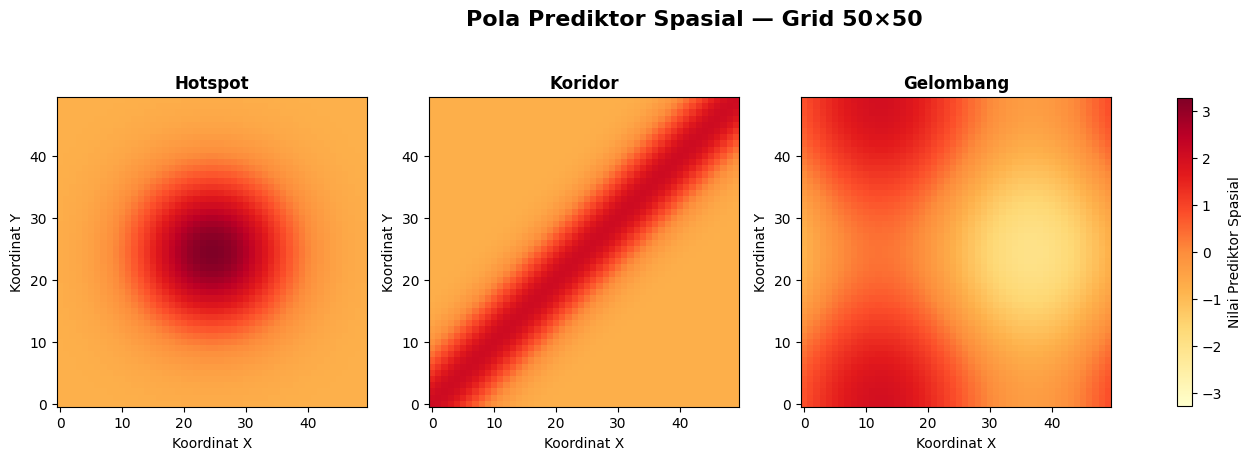



HASIL PEMBANGKITAN DATA GRID 50×50
Grid              : 50 x 50
N                 : 2500
Jumlah skenario   : 54
Jumlah baris data : 135000
Lokasi/skenario   : 2500


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Mean_Y,SD_Y,Moran_I_Y
0,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,0.601633,3.383402,0.577925
1,50,2500,G50_HOTSPOT_KNN5_WEAK_HETEROGENEOUS,Hotspot,KNN-5,Weak,0.2,Heterogeneous,0.603429,3.375941,0.573691
2,50,2500,G50_HOTSPOT_KNN5_MODERATE_HOMOGENEOUS,Hotspot,KNN-5,Moderate,0.5,Homogeneous,0.965968,4.689255,0.786364
3,50,2500,G50_HOTSPOT_KNN5_MODERATE_HETEROGENEOUS,Hotspot,KNN-5,Moderate,0.5,Heterogeneous,0.969289,4.672674,0.784051
4,50,2500,G50_HOTSPOT_KNN5_STRONG_HOMOGENEOUS,Hotspot,KNN-5,Strong,0.8,Homogeneous,2.449845,10.372650,0.948872


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
0,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
1,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
2,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
4,50,2500,G50_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260



Jumlah kombinasi skenario = 54


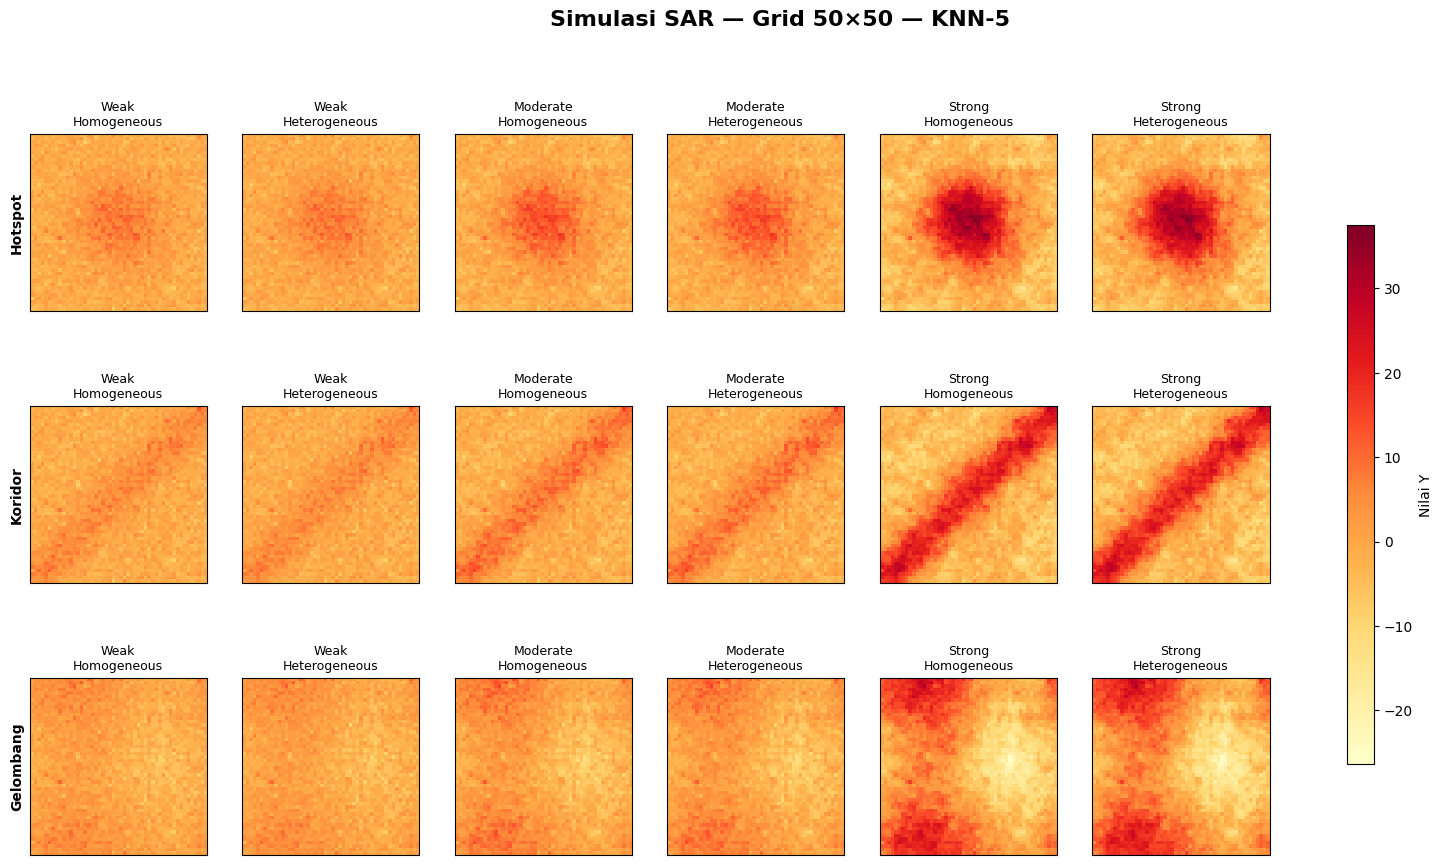

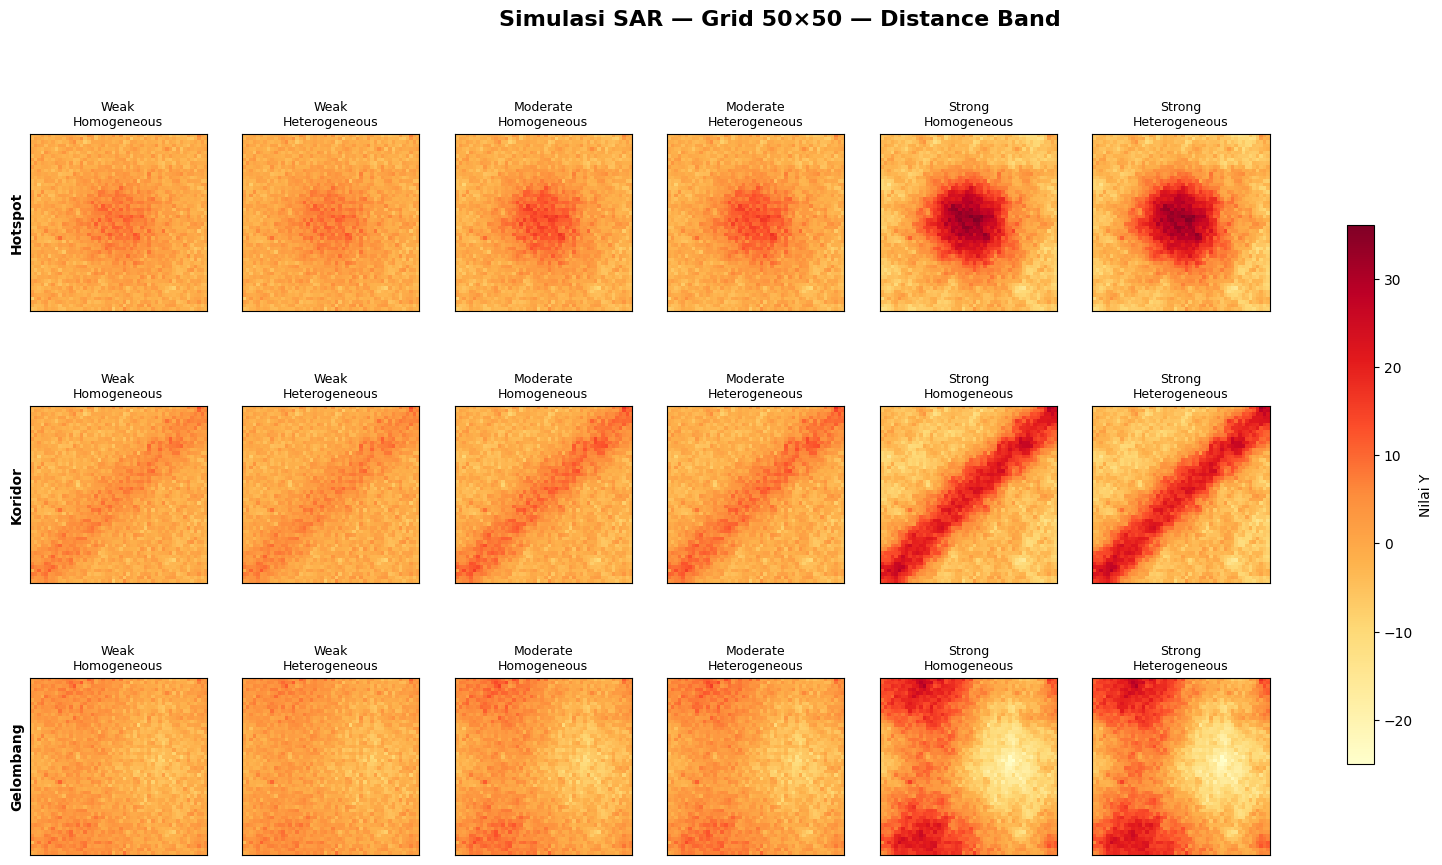

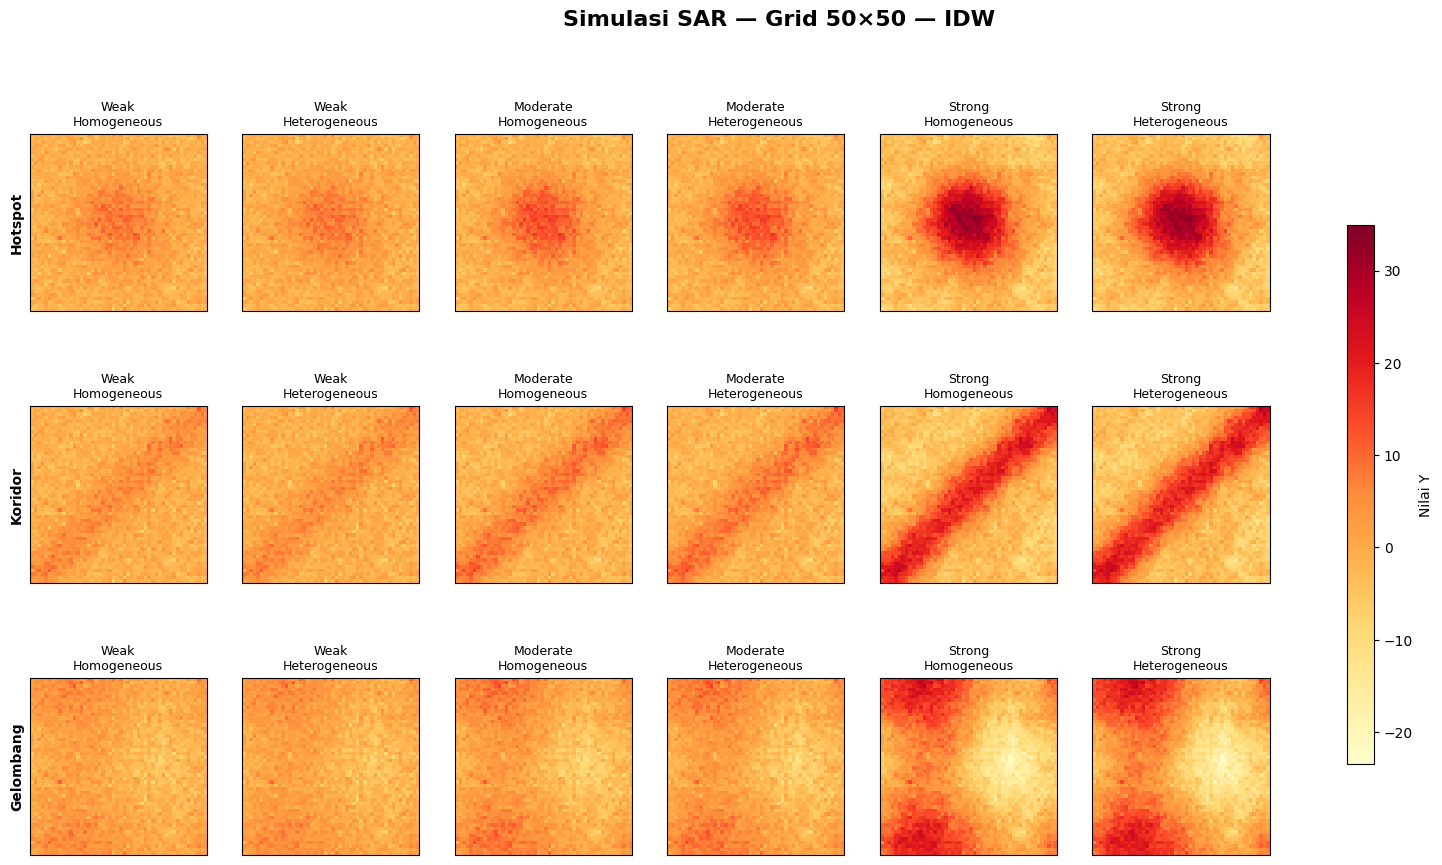



PEMBANGKITAN GRID 50×50 SELESAI
DATA_GRID50.csv
SUMMARY_GRID50.csv
W_KNN5_GRID50.npz
W_DISTANCE_GRID50.npz
W_IDW_GRID50.npz


In [21]:
# ============================================================
# ============================================================
# GRID 50 x 50
# CELL 1 — PEMBANGKITAN DATA SIMULASI
# ============================================================
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial import cKDTree
from scipy.sparse import csr_matrix, eye, save_npz
from scipy.sparse.linalg import factorized


# ============================================================
# 1. PENGATURAN GRID
# ============================================================

GRID_SIZE = 50
GRID_LABEL = "GRID50"

N = GRID_SIZE * GRID_SIZE


print("=" * 80)
print(f"PEMBANGKITAN DATA {GRID_LABEL}")
print("=" * 80)

print("Grid Size      :", GRID_SIZE, "x", GRID_SIZE)
print("Jumlah lokasi :", N)


# ============================================================
# 2. MEMBENTUK GRID SPASIAL
# ============================================================

x_coord = np.arange(
    1,
    GRID_SIZE + 1
)

y_coord = np.arange(
    1,
    GRID_SIZE + 1
)


xx, yy = np.meshgrid(
    x_coord,
    y_coord
)


grid = pd.DataFrame({

    "ID":
        np.arange(
            1,
            N + 1
        ),

    "X_coord":
        xx.ravel(),

    "Y_coord":
        yy.ravel()

})


# ============================================================
# 3. NORMALISASI KOORDINAT KE [0,1]
# ============================================================

grid["X_norm"] = (

    grid["X_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Y_norm"] = (

    grid["Y_coord"] - 1

) / (

    GRID_SIZE - 1

)


grid["Grid_Size"] = GRID_SIZE
grid["N"] = N


# ============================================================
# 4. MEMBENTUK ZONA ERROR
# ============================================================

grid["Error_Zone"] = np.where(

    grid["X_norm"] <= 0.5,

    "A",

    "B"

)


print("\nJumlah lokasi per zona:")

display(
    grid["Error_Zone"].value_counts()
)


display(
    grid.head()
)


# ============================================================
# 5. FUNGSI STANDARDISASI POLA
# ============================================================

def standardize_pattern(values):

    values = np.asarray(
        values,
        dtype=float
    )

    return (

        values
        -
        np.mean(values)

    ) / np.std(values)


# ============================================================
# 6. MEMBENTUK POLA SPASIAL
# ============================================================

x = grid["X_norm"].values
y = grid["Y_norm"].values


# ============================================================
# 6.1 HOTSPOT
# ============================================================

TAU_H = 0.18


hotspot_raw = np.exp(

    -(

        (x - 0.5) ** 2

        +

        (y - 0.5) ** 2

    )

    /

    (
        2 * TAU_H ** 2
    )

)


hotspot = standardize_pattern(
    hotspot_raw
)


# ============================================================
# 6.2 KORIDOR
# ============================================================

TAU_C = 0.12


corridor_raw = np.exp(

    -(

        np.abs(
            y - x
        ) ** 2

    )

    /

    (
        2 * TAU_C ** 2
    )

)


corridor = standardize_pattern(
    corridor_raw
)


# ============================================================
# 6.3 GELOMBANG
# ============================================================

wave_raw = (

    np.sin(
        2 * np.pi * x
    )

    +

    0.7
    *
    np.cos(
        2 * np.pi * y
    )

)


wave = standardize_pattern(
    wave_raw
)


PATTERN_DICT = {

    "Hotspot":
        hotspot,

    "Koridor":
        corridor,

    "Gelombang":
        wave

}


# ============================================================
# 7. FUNGSI MEMBENTUK MATRIKS PLOT
# ============================================================

def pattern_to_matrix(values):

    temp = grid[
        [
            "X_coord",
            "Y_coord"
        ]
    ].copy()

    temp["value"] = values

    return temp.pivot(

        index="Y_coord",

        columns="X_coord",

        values="value"

    )


# ============================================================
# 8. VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(

    list(
        PATTERN_DICT.values()
    )

)


pattern_limit = np.max(

    np.abs(
        all_pattern_values
    )

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):


    matrix = pattern_to_matrix(
        pattern_values
    )


    im = ax.imshow(

        matrix,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(
        pattern_name,
        fontweight="bold"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Pola Prediktor Spasial — Grid 50×50",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# 9. MEMBANGKITKAN 19 PREDIKTOR RANDOM
# ============================================================

SEED_X = 2026


rng_X = np.random.default_rng(
    SEED_X
)


X_random = rng_X.normal(

    loc=0,

    scale=1,

    size=(
        N,
        19
    )

)


X_columns = [

    f"X{i}"

    for i in range(
        1,
        20
    )

]


X_df = pd.DataFrame(

    X_random,

    columns=X_columns

)


# ============================================================
# 10. FUNGSI NONLINEAR NON-SPASIAL
# ============================================================

non_spatial_signal = (

    2
    *
    np.sin(
        X_df["X1"].values
    )

    +

    0.5
    *
    (
        X_df["X2"].values ** 2
    )

    +

    (
        X_df["X3"].values

        *

        X_df["X4"].values
    )

    +

    X_df["X5"].values

)


# ============================================================
# 11. MEMBANGKITKAN ERROR DASAR
# ============================================================

SEED_ERROR = 2027


rng_error = np.random.default_rng(
    SEED_ERROR
)


z_error = rng_error.normal(

    loc=0,

    scale=1,

    size=N

)


# ============================================================
# 12. STRUKTUR VARIANS ERROR
# ============================================================

variance_homo = np.ones(
    N
)


variance_hetero = np.where(

    grid[
        "Error_Zone"
    ].values
    ==
    "A",

    0.5,

    1.5

)


error_homo = z_error.copy()


error_hetero = (

    np.sqrt(
        variance_hetero
    )

    *

    z_error

)


ERROR_DICT = {

    "Homogeneous":
        error_homo,

    "Heterogeneous":
        error_hetero

}


# ============================================================
# 13. KOORDINAT UNTUK W
# ============================================================

coordinates = grid[
    [
        "X_coord",
        "Y_coord"
    ]
].values


spatial_tree = cKDTree(
    coordinates
)


# ============================================================
# 14. FUNGSI ROW STANDARDIZATION
# ============================================================

def row_standardize_sparse(W):

    W = W.tocsr().astype(float)

    W.setdiag(0)

    W.eliminate_zeros()


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    if np.any(
        row_sum == 0
    ):

        raise ValueError(
            "Terdapat lokasi tanpa tetangga."
        )


    W_standardized = W.multiply(

        (
            1 / row_sum
        )[:, None]

    ).tocsr()


    return W_standardized


# ============================================================
# 15. W KNN-5
# ============================================================

K = 5


knn_distances, knn_indices = spatial_tree.query(

    coordinates,

    k=K + 1

)


knn_rows = np.repeat(

    np.arange(N),

    K

)


knn_cols = knn_indices[

    :,
    1:
].ravel()


knn_values = np.ones(
    len(
        knn_rows
    )
)


W_knn5_raw = csr_matrix(

    (

        knn_values,

        (
            knn_rows,
            knn_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_knn5 = row_standardize_sparse(
    W_knn5_raw
)


# ============================================================
# 16. W DISTANCE BAND
# ============================================================

DISTANCE_THRESHOLD = 1.5


distance_rows = []
distance_cols = []


distance_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=DISTANCE_THRESHOLD

)


for i, neighbors in enumerate(
    distance_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= DISTANCE_THRESHOLD
        ):

            distance_rows.append(i)

            distance_cols.append(j)


W_distance_raw = csr_matrix(

    (

        np.ones(
            len(
                distance_rows
            )
        ),

        (
            distance_rows,
            distance_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_distance = row_standardize_sparse(
    W_distance_raw
)


# ============================================================
# 17. W IDW
# ============================================================

IDW_RADIUS = 2.5
IDW_ALPHA = 1


idw_rows = []
idw_cols = []
idw_values = []


idw_neighbors = spatial_tree.query_ball_point(

    coordinates,

    r=IDW_RADIUS

)


for i, neighbors in enumerate(
    idw_neighbors
):

    for j in neighbors:

        if i == j:
            continue


        distance_ij = np.linalg.norm(

            coordinates[i]
            -
            coordinates[j]

        )


        if (
            distance_ij > 0
            and
            distance_ij <= IDW_RADIUS
        ):

            idw_rows.append(i)

            idw_cols.append(j)

            idw_values.append(

                1
                /
                (
                    distance_ij
                    **
                    IDW_ALPHA
                )

            )


W_idw_raw = csr_matrix(

    (

        idw_values,

        (
            idw_rows,
            idw_cols
        )

    ),

    shape=(
        N,
        N
    )

)


W_idw = row_standardize_sparse(
    W_idw_raw
)


# ============================================================
# DICTIONARY W
# ============================================================

W_RAW_DICT = {

    "KNN-5":
        W_knn5_raw,

    "Distance Band":
        W_distance_raw,

    "IDW":
        W_idw_raw

}


W_DICT = {

    "KNN-5":
        W_knn5,

    "Distance Band":
        W_distance,

    "IDW":
        W_idw

}


# ============================================================
# 18. PARAMETER RHO
# ============================================================

RHO_DICT = {

    "Weak":
        0.20,

    "Moderate":
        0.50,

    "Strong":
        0.80

}


# ============================================================
# 19. FUNGSI MORAN'S I
# ============================================================

def morans_I(
    values,
    W
):

    values = np.asarray(
        values,
        dtype=float
    )


    z = (

        values
        -
        np.mean(
            values
        )

    )


    n_obs = len(
        values
    )


    S0 = W.sum()


    numerator = (

        z

        @

        (
            W @ z
        )

    )


    denominator = (

        z

        @

        z

    )


    return float(

        (
            n_obs
            /
            S0
        )

        *

        (
            numerator
            /
            denominator
        )

    )


# ============================================================
# 20. MEMBUAT SOLVER SAR
# ============================================================

SAR_SOLVER_DICT = {}


for W_name, W in W_DICT.items():


    for strength_name, rho in RHO_DICT.items():


        A = (

            eye(
                N,
                format="csc"
            )

            -

            rho
            *
            W.tocsc()

        )


        SAR_SOLVER_DICT[

            (
                W_name,
                strength_name
            )

        ] = factorized(
            A
        )


# ============================================================
# 21. MEMBANGKITKAN SELURUH 54 SKENARIO
# ============================================================

scenario_summary_rows = []

simulation_rows = []

Y_SCENARIOS = {}


for pattern_name, spatial_predictor in PATTERN_DICT.items():


    g_X = (

        2
        *
        spatial_predictor

        +

        non_spatial_signal

    )


    for W_name, W in W_DICT.items():


        for strength_name, rho in RHO_DICT.items():


            sar_solver = SAR_SOLVER_DICT[

                (
                    W_name,
                    strength_name
                )

            ]


            for error_name, error_values in ERROR_DICT.items():


                scenario_id = (

                    f"G{GRID_SIZE}_"

                    f"{pattern_name.upper()}_"

                    f"{W_name.upper().replace(' ', '_').replace('-', '')}_"

                    f"{strength_name.upper()}_"

                    f"{error_name.upper()}"

                )


                rhs = (

                    g_X

                    +

                    error_values

                )


                Y_values = sar_solver(
                    rhs
                )


                moran_y = morans_I(

                    Y_values,

                    W

                )


                Y_SCENARIOS[
                    scenario_id
                ] = Y_values.copy()


                scenario_summary_rows.append({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Mean_Y":
                        np.mean(
                            Y_values
                        ),

                    "SD_Y":
                        np.std(
                            Y_values,
                            ddof=1
                        ),

                    "Moran_I_Y":
                        moran_y

                })


                temp = pd.DataFrame({

                    "Grid_Size":
                        GRID_SIZE,

                    "N":
                        N,

                    "Scenario_ID":
                        scenario_id,

                    "Pattern":
                        pattern_name,

                    "W_Method":
                        W_name,

                    "Strength":
                        strength_name,

                    "Rho":
                        rho,

                    "Error_Structure":
                        error_name,

                    "Location_ID":
                        grid[
                            "ID"
                        ].values,

                    "X_coord":
                        grid[
                            "X_coord"
                        ].values,

                    "Y_coord":
                        grid[
                            "Y_coord"
                        ].values,

                    "X_norm":
                        grid[
                            "X_norm"
                        ].values,

                    "Y_norm":
                        grid[
                            "Y_norm"
                        ].values,

                    "Error_Zone":
                        grid[
                            "Error_Zone"
                        ].values,

                    "X_spatial":
                        spatial_predictor,

                    "Error":
                        error_values,

                    "g_X":
                        g_X,

                    "Y":
                        Y_values

                })


                for col in X_columns:

                    temp[
                        col
                    ] = X_df[
                        col
                    ].values


                simulation_rows.append(
                    temp
                )


# ============================================================
# 22. GABUNGKAN SELURUH SKENARIO
# ============================================================

scenario_summary = pd.DataFrame(

    scenario_summary_rows

)


simulation_long = pd.concat(

    simulation_rows,

    ignore_index=True

)


# ============================================================
# 23. OBJEK AKHIR KHUSUS GRID 50
# ============================================================

DATA_GRID50 = simulation_long.copy()

SUMMARY_GRID50 = scenario_summary.copy()


# ============================================================
# 24. CEK HASIL PEMBANGKITAN
# ============================================================

print("\n")
print("=" * 80)
print("HASIL PEMBANGKITAN DATA GRID 50×50")
print("=" * 80)


print(
    "Grid              :",
    GRID_SIZE,
    "x",
    GRID_SIZE
)

print(
    "N                 :",
    N
)

print(
    "Jumlah skenario   :",
    DATA_GRID50[
        "Scenario_ID"
    ].nunique()
)

print(
    "Jumlah baris data :",
    len(
        DATA_GRID50
    )
)

print(
    "Lokasi/skenario   :",
    DATA_GRID50[
        "Location_ID"
    ].nunique()
)


print("=" * 80)


display(
    SUMMARY_GRID50.head()
)


display(
    DATA_GRID50.head()
)


# ============================================================
# 25. CEK 54 SKENARIO
# ============================================================

jumlah_skenario = (

    DATA_GRID50[

        [
            "Pattern",
            "W_Method",
            "Strength",
            "Rho",
            "Error_Structure"
        ]

    ]

    .drop_duplicates()

    .shape[0]

)


print(
    "\nJumlah kombinasi skenario =",
    jumlah_skenario
)


# ============================================================
# 26. VISUALISASI Y
# ============================================================

pattern_order = [

    "Hotspot",
    "Koridor",
    "Gelombang"

]


column_order = [

    ("Weak", "Homogeneous"),

    ("Weak", "Heterogeneous"),

    ("Moderate", "Homogeneous"),

    ("Moderate", "Heterogeneous"),

    ("Strong", "Homogeneous"),

    ("Strong", "Heterogeneous")

]


for W_name in W_DICT.keys():


    subset_W = DATA_GRID50[

        DATA_GRID50[
            "W_Method"
        ]
        ==
        W_name

    ]


    Y_min = subset_W[
        "Y"
    ].min()


    Y_max = subset_W[
        "Y"
    ].max()


    fig, axes = plt.subplots(

        3,
        6,

        figsize=(20, 10)

    )


    for row_index, pattern_name in enumerate(
        pattern_order
    ):


        for col_index, (
            strength_name,
            error_name
        ) in enumerate(
            column_order
        ):


            temp = subset_W[

                (
                    subset_W[
                        "Pattern"
                    ]
                    ==
                    pattern_name
                )

                &

                (
                    subset_W[
                        "Strength"
                    ]
                    ==
                    strength_name
                )

                &

                (
                    subset_W[
                        "Error_Structure"
                    ]
                    ==
                    error_name
                )

            ]


            matrix_Y = temp.pivot(

                index="Y_coord",

                columns="X_coord",

                values="Y"

            )


            im = axes[
                row_index,
                col_index
            ].imshow(

                matrix_Y,

                origin="lower",

                cmap="YlOrRd",

                vmin=Y_min,

                vmax=Y_max,

                aspect="equal"

            )


            axes[
                row_index,
                col_index
            ].set_title(

                f"{strength_name}\n"
                f"{error_name}",

                fontsize=9

            )


            if col_index == 0:

                axes[
                    row_index,
                    col_index
                ].set_ylabel(

                    pattern_name,

                    fontweight="bold"

                )


            axes[
                row_index,
                col_index
            ].set_xticks([])


            axes[
                row_index,
                col_index
            ].set_yticks([])


    fig.colorbar(

        im,

        ax=axes.ravel().tolist(),

        label="Nilai Y",

        shrink=0.7

    )


    fig.suptitle(

        f"Simulasi SAR — Grid 50×50 — {W_name}",

        fontsize=16,

        fontweight="bold"

    )


    plt.show()


# ============================================================
# 27. SIMPAN DATA GRID 50
# ============================================================

DATA_GRID50.to_csv(

    "DATA_GRID50.csv",

    index=False

)


SUMMARY_GRID50.to_csv(

    "SUMMARY_GRID50.csv",

    index=False

)


# ============================================================
# 28. SIMPAN MATRIKS W
# ============================================================

save_npz(

    "W_KNN5_GRID50.npz",

    W_knn5

)


save_npz(

    "W_DISTANCE_GRID50.npz",

    W_distance

)


save_npz(

    "W_IDW_GRID50.npz",

    W_idw

)


print("\n")
print("=" * 80)
print("PEMBANGKITAN GRID 50×50 SELESAI")
print("=" * 80)

print("DATA_GRID50.csv")
print("SUMMARY_GRID50.csv")
print("W_KNN5_GRID50.npz")
print("W_DISTANCE_GRID50.npz")
print("W_IDW_GRID50.npz")

print("=" * 80)

## VALIDASI HASIL SIMULASI

VALIDASI DATA SIMULASI SPASIAL — GRID 50×50


1. VALIDASI WEAK - MODERATE - STRONG


,Grid_Size,Strength,Rho,Mean_Moran_I,SD_Moran_I,Min_Moran_I,Max_Moran_I,N_Scenario
2,50,Weak,0.2,0.5591,0.0134,0.5314,0.5779,18
0,50,Moderate,0.5,0.7673,0.0155,0.7353,0.7870,18
1,50,Strong,0.8,0.9403,0.0087,0.9215,0.9514,18


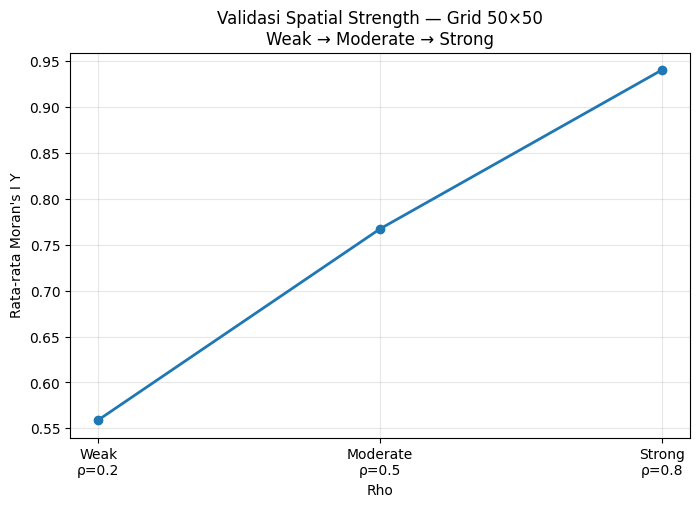


Apakah Mean Moran's I meningkat Weak < Moderate < Strong ?
True


2. MORAN'S I POLA SPASIAL


,Grid_Size,Pattern,W_Method,Moran_I_Pattern
0,50,Hotspot,KNN-5,0.9946
1,50,Hotspot,Distance Band,0.9920
2,50,Hotspot,IDW,0.9849
3,50,Koridor,KNN-5,0.9881
4,50,Koridor,Distance Band,0.9850
5,50,Koridor,IDW,0.9713
6,50,Gelombang,KNN-5,0.9947
7,50,Gelombang,Distance Band,0.9939
8,50,Gelombang,IDW,0.9884



RINGKASAN MORAN'S I POLA


,Grid_Size,Pattern,Mean_Moran_I,Min_Moran_I,Max_Moran_I
0,50,Gelombang,0.9923,0.9884,0.9947
1,50,Hotspot,0.9905,0.9849,0.9946
2,50,Koridor,0.9815,0.9713,0.9881


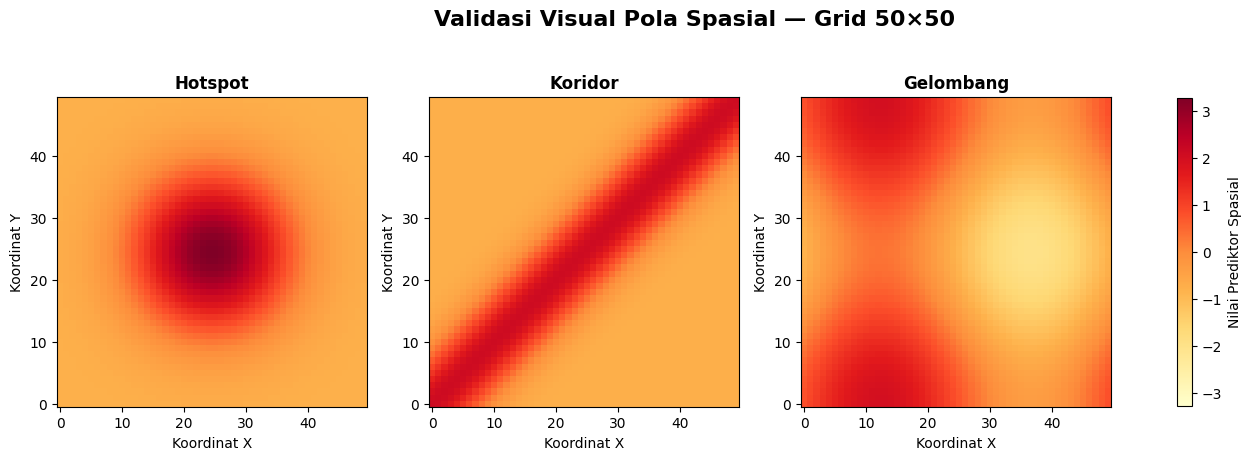



3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN
Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi
Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5
Breusch-Pagan digunakan sebagai diagnostik realisasi sampel.
H0 : Varians error konstan
H1 : Varians error tidak konstan
Alpha = 0.05


,Grid_Size,Error_Structure,Design,LM_Statistic,LM_pvalue,F_Statistic,F_pvalue,BP_Result,BP_Diagnostic
0,50,Homogeneous,Homoskedastis by construction,0.075768,0.783117,0.075709,0.783221,Fail to Reject H0,Tidak terdeteksi heteroskedastisitas pada real...
1,50,Heterogeneous,Heteroskedastis by construction,240.811479,0.000000,266.266879,0.000000,Reject H0,Terdeteksi heteroskedastisitas pada realisasi ini




VALIDASI DESAIN VARIANS
Homogeneous sigma² = 1             : True
Heterogeneous A=0.5 dan B=1.5     : True
Status desain error                : PASS


DIAGNOSTIK BREUSCH-PAGAN
p-value Homogeneous   : 0.783117
p-value Heterogeneous : 0.0
BP Homo   : sesuai dengan desain homoskedastis.
BP Hetero : heteroskedastisitas berhasil terdeteksi.


VARIANS ERROR SAMPEL PER ZONA


,Grid_Size,Zone,N,Mean_Error_Homo,Variance_Homogeneous,Mean_Error_Hetero,Variance_Heterogeneous
0,50,A,1250,-0.0157,1.0000,-0.0111,0.5000
1,50,B,1250,-0.0097,1.0157,-0.0119,1.5235


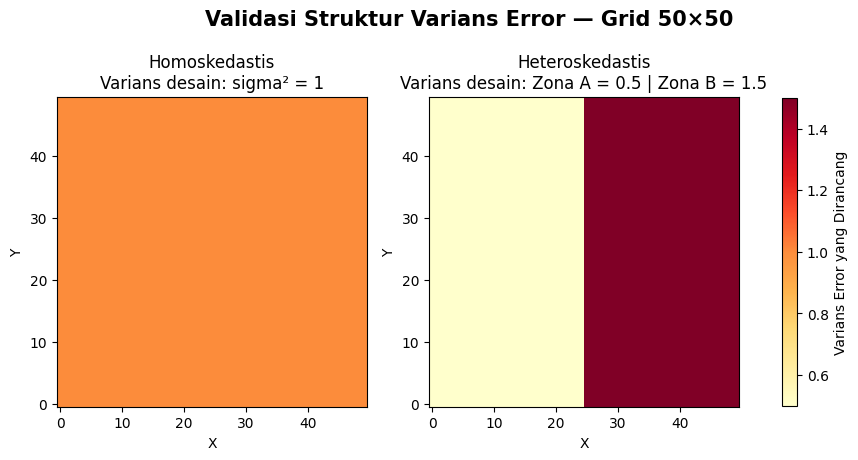



4. VALIDASI MATRIKS BOBOT W


,Grid_Size,W_Method,Min_Neighbor,Mean_Neighbor,Max_Neighbor,Min_Positive_Weight,Mean_Positive_Weight,Max_Positive_Weight,Min_Row_Sum,Max_Row_Sum,No_Self_Neighbor,Symmetric
0,50,KNN-5,5,5.0000,5,0.200,0.2000,0.2000,1.0,1.0,True,False
1,50,Distance Band,3,7.7616,8,0.125,0.1288,0.3333,1.0,1.0,True,False
2,50,IDW,7,19.1280,20,0.036,0.0523,0.2173,1.0,1.0,True,False


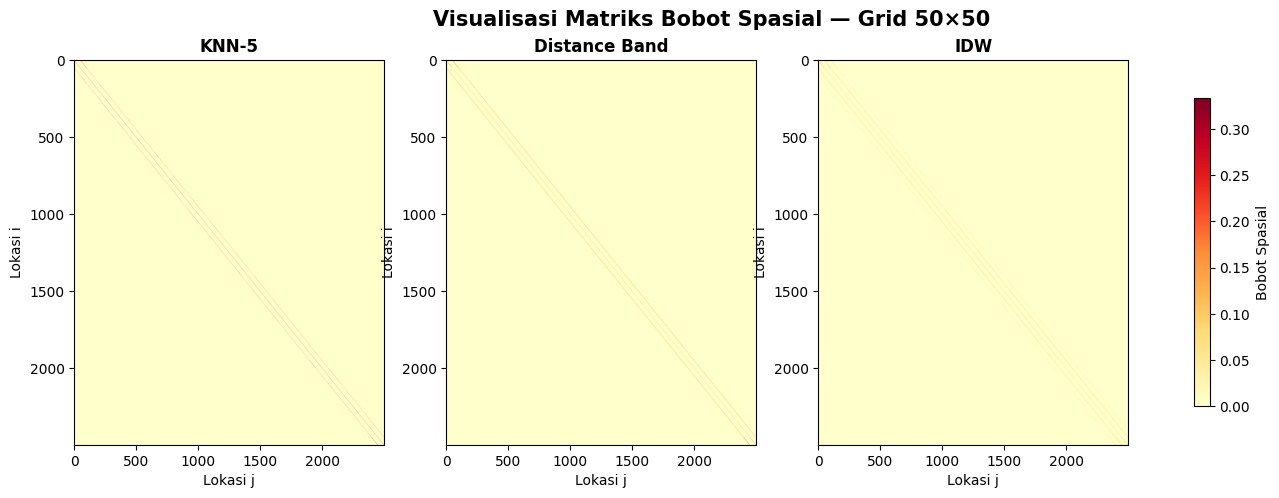

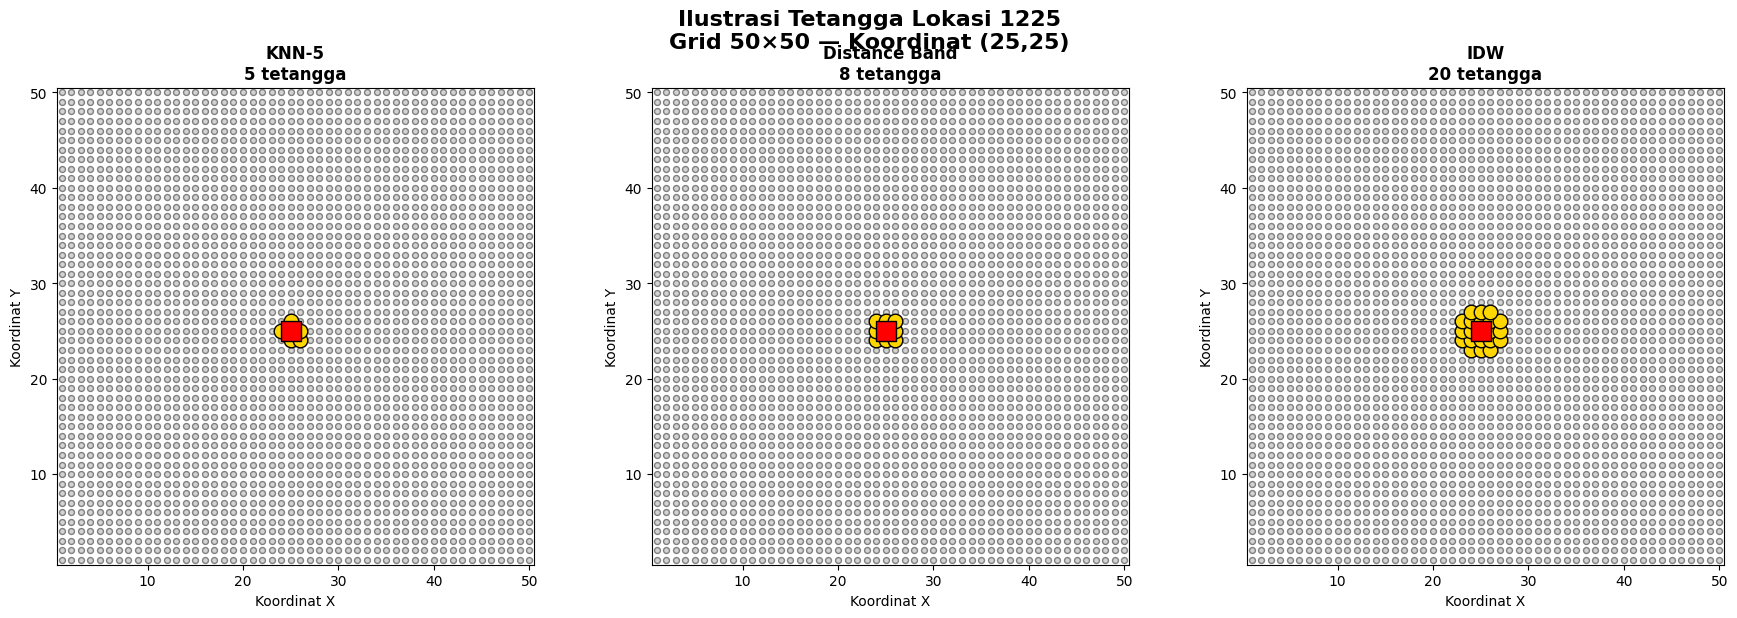



DETAIL TETANGGA LOKASI FOKUS


,Grid_Size,W_Method,Focus_ID,Neighbor_ID,Distance,Weight
6,50,Distance Band,1225,1175,1.0000,0.1250
8,50,Distance Band,1225,1224,1.0000,0.1250
9,50,Distance Band,1225,1226,1.0000,0.1250
11,50,Distance Band,1225,1275,1.0000,0.1250
5,50,Distance Band,1225,1174,1.4142,0.1250
7,50,Distance Band,1225,1176,1.4142,0.1250
10,50,Distance Band,1225,1274,1.4142,0.1250
12,50,Distance Band,1225,1276,1.4142,0.1250
18,50,IDW,1225,1175,1.0000,0.0806
22,50,IDW,1225,1224,1.0000,0.0806




TABEL VALIDASI FINAL SIMULASI — GRID 50×50


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,50,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,50,Pola spasial,Plot pola + Moran's I pola,PASS
2,50,Homo / Heteroskedastis,Desain varians + Breusch-Pagan diagnostik,PASS
3,50,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS




CEK OBJEK AKHIR GRID 50×50
DATA_GRID50                  : (135000, 37)
SUMMARY_GRID50               : (54, 11)
VALIDASI_GRID50              : (4, 4)
STRENGTH_VALIDATION_GRID50   : (3, 8)
PATTERN_VALIDATION_GRID50    : (9, 4)
BP_GRID50                    : (2, 9)
VARIANCE_GRID50              : (2, 7)
W_VALIDATION_GRID50          : (3, 12)
NEIGHBOR_GRID50              : (33, 6)

Jumlah skenario : 54
Jumlah baris    : 135000
✅ GRID 50×50: SEMUA VALIDASI PASS

FILE YANG TERSIMPAN:
DATA_GRID50.csv
SUMMARY_GRID50.csv
VALIDASI_FINAL_GRID50.csv
VALIDASI_STRENGTH_GRID50.csv
VALIDASI_POLA_GRID50.csv
RINGKASAN_POLA_GRID50.csv
VALIDASI_BREUSCH_PAGAN_GRID50.csv
VALIDASI_VARIANS_GRID50.csv
VALIDASI_W_GRID50.csv
DETAIL_TETANGGA_GRID50.csv
W_KNN5_GRID50.npz
W_DISTANCE_GRID50.npz
W_IDW_GRID50.npz


In [22]:
# ============================================================
# ============================================================
# GRID 50 x 50
# CELL 2 — VALIDASI DATA SIMULASI
# ============================================================
# ============================================================

import statsmodels.api as sm

from statsmodels.stats.diagnostic import het_breuschpagan


print("=" * 80)
print("VALIDASI DATA SIMULASI SPASIAL — GRID 50×50")
print("=" * 80)


# ============================================================
# VALIDASI 1
# WEAK / MODERATE / STRONG
# ============================================================

strength_validation = (

    SUMMARY_GRID50

    .groupby(
        [
            "Strength",
            "Rho"
        ]
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Y",
            "mean"
        ),

        SD_Moran_I=(
            "Moran_I_Y",
            "std"
        ),

        Min_Moran_I=(
            "Moran_I_Y",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Y",
            "max"
        ),

        N_Scenario=(
            "Moran_I_Y",
            "count"
        )

    )

    .reset_index()

)


strength_order = {

    "Weak": 1,

    "Moderate": 2,

    "Strong": 3

}


strength_validation["_order"] = (

    strength_validation[
        "Strength"
    ]

    .map(
        strength_order
    )

)


strength_validation = (

    strength_validation

    .sort_values(
        "_order"
    )

    .drop(
        columns="_order"
    )

)


strength_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("1. VALIDASI WEAK - MODERATE - STRONG")
print("=" * 80)


display(

    strength_validation.round(4)

)


# ============================================================
# PLOT STRENGTH
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    strength_validation[
        "Rho"
    ],

    strength_validation[
        "Mean_Moran_I"
    ],

    marker="o",

    linewidth=2

)


plt.xlabel(
    "Rho"
)


plt.ylabel(
    "Rata-rata Moran's I Y"
)


plt.title(

    "Validasi Spatial Strength — Grid 50×50\n"
    "Weak → Moderate → Strong"

)


plt.xticks(

    [
        0.2,
        0.5,
        0.8
    ],

    [
        "Weak\nρ=0.2",
        "Moderate\nρ=0.5",
        "Strong\nρ=0.8"
    ]

)


plt.grid(
    alpha=0.3
)


plt.show()


# ============================================================
# CEK OTOMATIS STRENGTH
# ============================================================

mean_moran_weak = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Weak",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_moderate = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Moderate",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


mean_moran_strong = (

    strength_validation.loc[

        strength_validation[
            "Strength"
        ]
        ==
        "Strong",

        "Mean_Moran_I"

    ]

    .iloc[0]

)


strength_pass = (

    mean_moran_weak

    <

    mean_moran_moderate

    <

    mean_moran_strong

)


print(
    "\nApakah Mean Moran's I meningkat "
    "Weak < Moderate < Strong ?"
)


print(
    strength_pass
)


# ============================================================
# VALIDASI 2
# POLA SPASIAL
# ============================================================

pattern_moran_rows = []


for pattern_name, pattern_values in PATTERN_DICT.items():


    for W_name, W in W_DICT.items():


        I_pattern = morans_I(

            pattern_values,

            W

        )


        pattern_moran_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "Pattern":
                pattern_name,

            "W_Method":
                W_name,

            "Moran_I_Pattern":
                I_pattern

        })


pattern_moran_validation = pd.DataFrame(

    pattern_moran_rows

)


print("\n")
print("=" * 80)
print("2. MORAN'S I POLA SPASIAL")
print("=" * 80)


display(

    pattern_moran_validation.round(4)

)


# ============================================================
# RINGKASAN POLA
# ============================================================

pattern_summary_validation = (

    pattern_moran_validation

    .groupby(
        "Pattern"
    )

    .agg(

        Mean_Moran_I=(
            "Moran_I_Pattern",
            "mean"
        ),

        Min_Moran_I=(
            "Moran_I_Pattern",
            "min"
        ),

        Max_Moran_I=(
            "Moran_I_Pattern",
            "max"
        )

    )

    .reset_index()

)


pattern_summary_validation.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print(
    "\nRINGKASAN MORAN'S I POLA"
)


display(

    pattern_summary_validation.round(4)

)


# ============================================================
# VISUALISASI POLA
# ============================================================

all_pattern_values = np.concatenate(

    list(
        PATTERN_DICT.values()
    )

)


pattern_limit = np.max(

    np.abs(
        all_pattern_values
    )

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    pattern_name,
    pattern_values
) in zip(

    axes,

    PATTERN_DICT.items()

):


    matrix_pattern = pattern_to_matrix(
        pattern_values
    )


    im = ax.imshow(

        matrix_pattern,

        origin="lower",

        cmap="YlOrRd",

        vmin=-pattern_limit,

        vmax=pattern_limit,

        aspect="equal"

    )


    ax.set_title(

        pattern_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Nilai Prediktor Spasial",

    shrink=0.8

)


fig.suptitle(

    "Validasi Visual Pola Spasial — Grid 50×50",

    fontsize=16,

    fontweight="bold"

)


plt.show()


# ============================================================
# VALIDASI 3
# STRUKTUR VARIANS ERROR + BREUSCH-PAGAN
# ============================================================

zone_dummy = (

    grid[
        "Error_Zone"
    ]

    ==
    "B"

).astype(int)


X_BP = sm.add_constant(
    zone_dummy
)


# ============================================================
# FUNGSI BREUSCH-PAGAN
# ============================================================

def run_breusch_pagan(

    residuals,

    exog,

    structure_name,

    design_name

):


    bp_result = het_breuschpagan(

        residuals,

        exog

    )


    LM_stat = bp_result[0]

    LM_pvalue = bp_result[1]

    F_stat = bp_result[2]

    F_pvalue = bp_result[3]


    if LM_pvalue < 0.05:

        bp_result_text = "Reject H0"

        bp_diagnostic = (
            "Terdeteksi heteroskedastisitas pada realisasi ini"
        )

    else:

        bp_result_text = "Fail to Reject H0"

        bp_diagnostic = (
            "Tidak terdeteksi heteroskedastisitas pada realisasi ini"
        )


    return {

        "Grid_Size":
            GRID_SIZE,

        "Error_Structure":
            structure_name,

        "Design":
            design_name,

        "LM_Statistic":
            LM_stat,

        "LM_pvalue":
            LM_pvalue,

        "F_Statistic":
            F_stat,

        "F_pvalue":
            F_pvalue,

        "BP_Result":
            bp_result_text,

        "BP_Diagnostic":
            bp_diagnostic

    }


BP_homo = run_breusch_pagan(

    residuals=
        error_homo,

    exog=
        X_BP,

    structure_name=
        "Homogeneous",

    design_name=
        "Homoskedastis by construction"

)


BP_hetero = run_breusch_pagan(

    residuals=
        error_hetero,

    exog=
        X_BP,

    structure_name=
        "Heterogeneous",

    design_name=
        "Heteroskedastis by construction"

)


BP_table = pd.DataFrame(

    [
        BP_homo,
        BP_hetero
    ]

)


print("\n")
print("=" * 80)
print("3. VALIDASI STRUKTUR ERROR + BREUSCH-PAGAN")
print("=" * 80)


print(
    "Desain Homogeneous   : sigma²_i = 1 untuk seluruh lokasi"
)

print(
    "Desain Heterogeneous : sigma²_A = 0.5 dan sigma²_B = 1.5"
)

print(
    "Breusch-Pagan digunakan sebagai diagnostik realisasi sampel."
)

print(
    "H0 : Varians error konstan"
)

print(
    "H1 : Varians error tidak konstan"
)

print(
    "Alpha = 0.05"
)


display(
    BP_table.round(6)
)


# ============================================================
# VALIDASI DESAIN VARIANS
# ============================================================

design_homo_pass = np.allclose(

    variance_homo,

    1.0

)


design_hetero_pass = (

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "A"
        ],

        0.5

    )

    and

    np.allclose(

        variance_hetero[
            grid[
                "Error_Zone"
            ].values
            ==
            "B"
        ],

        1.5

    )

)


error_design_pass = (

    design_homo_pass

    and

    design_hetero_pass

)


print("\n")
print("=" * 80)
print("VALIDASI DESAIN VARIANS")
print("=" * 80)


print(
    "Homogeneous sigma² = 1             :",
    design_homo_pass
)

print(
    "Heterogeneous A=0.5 dan B=1.5     :",
    design_hetero_pass
)

print(
    "Status desain error                :",
    (
        "PASS"
        if error_design_pass
        else
        "CHECK"
    )
)


# ============================================================
# HASIL BP SEBAGAI DIAGNOSTIK
# ============================================================

homo_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Homogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


hetero_pvalue = (

    BP_table.loc[

        BP_table[
            "Error_Structure"
        ]
        ==
        "Heterogeneous",

        "LM_pvalue"

    ]

    .iloc[0]

)


print("\n")
print("=" * 80)
print("DIAGNOSTIK BREUSCH-PAGAN")
print("=" * 80)


print(
    "p-value Homogeneous   :",
    round(
        homo_pvalue,
        6
    )
)

print(
    "p-value Heterogeneous :",
    round(
        hetero_pvalue,
        6
    )
)


if homo_pvalue >= 0.05:

    print(
        "BP Homo   : sesuai dengan desain homoskedastis."
    )

else:

    print(
        "BP Homo   : signifikan pada realisasi ini; "
        "dicatat sebagai diagnostik sampel."
    )


if hetero_pvalue < 0.05:

    print(
        "BP Hetero : heteroskedastisitas berhasil terdeteksi."
    )

else:

    print(
        "BP Hetero : heteroskedastisitas belum terdeteksi "
        "pada realisasi ini."
    )


# ============================================================
# VARIANS ERROR PER ZONA
# ============================================================

variance_check = pd.DataFrame({

    "Zone":
        grid[
            "Error_Zone"
        ],

    "Error_Homogeneous":
        error_homo,

    "Error_Heterogeneous":
        error_hetero

})


variance_zone_table = (

    variance_check

    .groupby(
        "Zone"
    )

    .agg(

        N=(
            "Error_Homogeneous",
            "count"
        ),

        Mean_Error_Homo=(
            "Error_Homogeneous",
            "mean"
        ),

        Variance_Homogeneous=(
            "Error_Homogeneous",
            "var"
        ),

        Mean_Error_Hetero=(
            "Error_Heterogeneous",
            "mean"
        ),

        Variance_Heterogeneous=(
            "Error_Heterogeneous",
            "var"
        )

    )

    .reset_index()

)


variance_zone_table.insert(

    0,

    "Grid_Size",

    GRID_SIZE

)


print("\n")
print("=" * 80)
print("VARIANS ERROR SAMPEL PER ZONA")
print("=" * 80)


display(

    variance_zone_table.round(4)

)


# ============================================================
# VISUALISASI STRUKTUR VARIANS
# ============================================================

variance_homo_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_homo

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


variance_hetero_matrix = (

    pd.DataFrame({

        "X":
            grid[
                "X_coord"
            ],

        "Y":
            grid[
                "Y_coord"
            ],

        "Variance":
            variance_hetero

    })

    .pivot(

        index="Y",

        columns="X",

        values="Variance"

    )

)


fig, axes = plt.subplots(

    1,
    2,

    figsize=(11, 5)

)


axes[0].imshow(

    variance_homo_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[0].set_title(

    "Homoskedastis\n"
    "Varians desain: sigma² = 1"

)


axes[0].set_xlabel(
    "X"
)


axes[0].set_ylabel(
    "Y"
)


im2 = axes[1].imshow(

    variance_hetero_matrix,

    origin="lower",

    cmap="YlOrRd",

    vmin=0.5,

    vmax=1.5

)


axes[1].set_title(

    "Heteroskedastis\n"
    "Varians desain: Zona A = 0.5 | Zona B = 1.5"

)


axes[1].set_xlabel(
    "X"
)


axes[1].set_ylabel(
    "Y"
)


fig.colorbar(

    im2,

    ax=axes.ravel().tolist(),

    label="Varians Error yang Dirancang",

    shrink=0.8

)


fig.suptitle(

    "Validasi Struktur Varians Error — Grid 50×50",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# VALIDASI 4
# MATRIKS BOBOT W
# ============================================================

W_validation_rows = []


for W_name, W in W_DICT.items():


    W_raw = W_RAW_DICT[
        W_name
    ].tocsr()


    W = W.tocsr()


    n_neighbors = np.diff(
        W_raw.indptr
    )


    positive_weights = W.data


    row_sum = np.asarray(

        W.sum(
            axis=1
        )

    ).ravel()


    diagonal_zero = np.allclose(

        W.diagonal(),

        0

    )


    W_difference = (

        W

        -

        W.T

    ).tocsr()


    if W_difference.nnz == 0:

        symmetric = True

    else:

        symmetric = (

            np.max(

                np.abs(
                    W_difference.data
                )

            )

            <

            1e-12

        )


    W_validation_rows.append({

        "Grid_Size":
            GRID_SIZE,

        "W_Method":
            W_name,

        "Min_Neighbor":
            np.min(
                n_neighbors
            ),

        "Mean_Neighbor":
            np.mean(
                n_neighbors
            ),

        "Max_Neighbor":
            np.max(
                n_neighbors
            ),

        "Min_Positive_Weight":
            np.min(
                positive_weights
            ),

        "Mean_Positive_Weight":
            np.mean(
                positive_weights
            ),

        "Max_Positive_Weight":
            np.max(
                positive_weights
            ),

        "Min_Row_Sum":
            np.min(
                row_sum
            ),

        "Max_Row_Sum":
            np.max(
                row_sum
            ),

        "No_Self_Neighbor":
            diagonal_zero,

        "Symmetric":
            symmetric

    })


W_validation_table = pd.DataFrame(

    W_validation_rows

)


print("\n")
print("=" * 80)
print("4. VALIDASI MATRIKS BOBOT W")
print("=" * 80)


display(

    W_validation_table.round(4)

)


# ============================================================
# HEATMAP W
# ============================================================

W_MAX = max(

    np.max(
        W.data
    )

    for W in W_DICT.values()

)


fig, axes = plt.subplots(

    1,
    3,

    figsize=(17, 5)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    W_dense_plot = W.toarray()


    im = ax.imshow(

        W_dense_plot,

        cmap="YlOrRd",

        vmin=0,

        vmax=W_MAX,

        aspect="auto"

    )


    ax.set_title(

        W_name,

        fontweight="bold"

    )


    ax.set_xlabel(
        "Lokasi j"
    )


    ax.set_ylabel(
        "Lokasi i"
    )


fig.colorbar(

    im,

    ax=axes.ravel().tolist(),

    label="Bobot Spasial",

    shrink=0.8

)


fig.suptitle(

    "Visualisasi Matriks Bobot Spasial — Grid 50×50",

    fontsize=15,

    fontweight="bold"

)


plt.show()


# ============================================================
# ILUSTRASI TETANGGA SATU LOKASI
# ============================================================

focus_x = GRID_SIZE // 2

focus_y = GRID_SIZE // 2


focus_idx = grid[

    (
        grid[
            "X_coord"
        ]
        ==
        focus_x
    )

    &

    (
        grid[
            "Y_coord"
        ]
        ==
        focus_y
    )

].index[0]


focus_id = int(

    grid.loc[
        focus_idx,
        "ID"
    ]

)


# ============================================================
# FUNGSI PLOT TETANGGA
# ============================================================

def plot_focus_neighbors(

    ax,

    W,

    method_name

):


    W_row = W.getrow(
        focus_idx
    )


    neighbors = W_row.indices


    ax.scatter(

        grid[
            "X_coord"
        ],

        grid[
            "Y_coord"
        ],

        s=18,

        color="lightgray",

        edgecolor="gray",

        zorder=1

    )


    for j in neighbors:


        weight = float(

            W[
                focus_idx,
                j
            ]

        )


        ax.plot(

            [
                grid.loc[
                    focus_idx,
                    "X_coord"
                ],

                grid.loc[
                    j,
                    "X_coord"
                ]
            ],

            [
                grid.loc[
                    focus_idx,
                    "Y_coord"
                ],

                grid.loc[
                    j,
                    "Y_coord"
                ]
            ],

            linewidth=

                1

                +

                10
                *
                weight,

            color="orange",

            alpha=0.8,

            zorder=2

        )


    ax.scatter(

        grid.loc[
            neighbors,
            "X_coord"
        ],

        grid.loc[
            neighbors,
            "Y_coord"
        ],

        s=110,

        color="gold",

        edgecolor="black",

        zorder=3

    )


    ax.scatter(

        grid.loc[
            focus_idx,
            "X_coord"
        ],

        grid.loc[
            focus_idx,
            "Y_coord"
        ],

        s=220,

        marker="s",

        color="red",

        edgecolor="black",

        zorder=4

    )


    ax.set_title(

        f"{method_name}\n"
        f"{len(neighbors)} tetangga",

        fontweight="bold"

    )


    ax.set_xlim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_ylim(
        0.5,
        GRID_SIZE + 0.5
    )


    ax.set_aspect(
        "equal"
    )


    ax.set_xlabel(
        "Koordinat X"
    )


    ax.set_ylabel(
        "Koordinat Y"
    )


# ============================================================
# PLOT TETANGGA
# ============================================================

fig, axes = plt.subplots(

    1,
    3,

    figsize=(18, 6)

)


for ax, (
    W_name,
    W
) in zip(

    axes,

    W_DICT.items()

):


    plot_focus_neighbors(

        ax,

        W,

        W_name

    )


fig.suptitle(

    f"Ilustrasi Tetangga Lokasi {focus_id}\n"
    f"Grid 50×50 — Koordinat ({focus_x},{focus_y})",

    fontsize=16,

    fontweight="bold"

)


plt.tight_layout()


plt.show()


# ============================================================
# DETAIL TETANGGA
# ============================================================

neighbor_rows = []


for W_name, W in W_DICT.items():


    neighbors = W.getrow(
        focus_idx
    ).indices


    for j in neighbors:


        distance_ij = np.linalg.norm(

            coordinates[
                focus_idx
            ]

            -

            coordinates[
                j
            ]

        )


        neighbor_rows.append({

            "Grid_Size":
                GRID_SIZE,

            "W_Method":
                W_name,

            "Focus_ID":
                focus_id,

            "Neighbor_ID":
                int(
                    grid.loc[
                        j,
                        "ID"
                    ]
                ),

            "Distance":
                distance_ij,

            "Weight":
                float(
                    W[
                        focus_idx,
                        j
                    ]
                )

        })


neighbor_detail_table = pd.DataFrame(

    neighbor_rows

)


print("\n")
print("=" * 80)
print("DETAIL TETANGGA LOKASI FOKUS")
print("=" * 80)


display(

    neighbor_detail_table

    .sort_values(

        [
            "W_Method",
            "Distance",
            "Neighbor_ID"
        ]

    )

    .round(4)

)


# ============================================================
# TABEL VALIDASI FINAL
# ============================================================

pattern_pass = np.all(

    pattern_moran_validation[
        "Moran_I_Pattern"
    ]

    >
    0

)


W_pass = (

    np.allclose(

        W_validation_table[
            "Min_Row_Sum"
        ].values,

        1

    )

    and

    np.allclose(

        W_validation_table[
            "Max_Row_Sum"
        ].values,

        1

    )

    and

    (
        W_validation_table[
            "Min_Neighbor"
        ].min()
        >
        0
    )

    and

    W_validation_table[
        "No_Self_Neighbor"
    ].all()

)


validation_final = pd.DataFrame({

    "Grid_Size": [

        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE,
        GRID_SIZE

    ],

    "Komponen": [

        "Weak / Moderate / Strong",

        "Pola spasial",

        "Homo / Heteroskedastis",

        "Spatial Weight Matrix"

    ],

    "Alat_Validasi": [

        "rho + Moran's I Y",

        "Plot pola + Moran's I pola",

        "Desain varians + Breusch-Pagan diagnostik",

        "Visualisasi W + statistik tetangga"

    ],

    "Hasil_Utama": [

        (
            "PASS"
            if strength_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if pattern_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if error_design_pass
            else
            "CHECK"
        ),

        (
            "PASS"
            if W_pass
            else
            "CHECK"
        )

    ]

})


# ============================================================
# OBJEK AKHIR KHUSUS GRID 50
# ============================================================

VALIDASI_GRID50 = validation_final.copy()


STRENGTH_VALIDATION_GRID50 = (

    strength_validation.copy()

)


PATTERN_VALIDATION_GRID50 = (

    pattern_moran_validation.copy()

)


PATTERN_SUMMARY_GRID50 = (

    pattern_summary_validation.copy()

)


BP_GRID50 = (

    BP_table.copy()

)


VARIANCE_GRID50 = (

    variance_zone_table.copy()

)


W_VALIDATION_GRID50 = (

    W_validation_table.copy()

)


NEIGHBOR_GRID50 = (

    neighbor_detail_table.copy()

)


# ============================================================
# TAMPILKAN VALIDASI FINAL
# ============================================================

print("\n")
print("=" * 80)
print("TABEL VALIDASI FINAL SIMULASI — GRID 50×50")
print("=" * 80)


display(

    VALIDASI_GRID50

)


# ============================================================
# SIMPAN SEMUA HASIL VALIDASI
# ============================================================

VALIDASI_GRID50.to_csv(

    "VALIDASI_FINAL_GRID50.csv",

    index=False

)


STRENGTH_VALIDATION_GRID50.to_csv(

    "VALIDASI_STRENGTH_GRID50.csv",

    index=False

)


PATTERN_VALIDATION_GRID50.to_csv(

    "VALIDASI_POLA_GRID50.csv",

    index=False

)


PATTERN_SUMMARY_GRID50.to_csv(

    "RINGKASAN_POLA_GRID50.csv",

    index=False

)


BP_GRID50.to_csv(

    "VALIDASI_BREUSCH_PAGAN_GRID50.csv",

    index=False

)


VARIANCE_GRID50.to_csv(

    "VALIDASI_VARIANS_GRID50.csv",

    index=False

)


W_VALIDATION_GRID50.to_csv(

    "VALIDASI_W_GRID50.csv",

    index=False

)


NEIGHBOR_GRID50.to_csv(

    "DETAIL_TETANGGA_GRID50.csv",

    index=False

)


# ============================================================
# CEK AKHIR SEMUA OBJEK
# ============================================================

print("\n")
print("=" * 80)
print("CEK OBJEK AKHIR GRID 50×50")
print("=" * 80)


print(
    "DATA_GRID50                  :",
    DATA_GRID50.shape
)

print(
    "SUMMARY_GRID50               :",
    SUMMARY_GRID50.shape
)

print(
    "VALIDASI_GRID50              :",
    VALIDASI_GRID50.shape
)

print(
    "STRENGTH_VALIDATION_GRID50   :",
    STRENGTH_VALIDATION_GRID50.shape
)

print(
    "PATTERN_VALIDATION_GRID50    :",
    PATTERN_VALIDATION_GRID50.shape
)

print(
    "BP_GRID50                    :",
    BP_GRID50.shape
)

print(
    "VARIANCE_GRID50              :",
    VARIANCE_GRID50.shape
)

print(
    "W_VALIDATION_GRID50          :",
    W_VALIDATION_GRID50.shape
)

print(
    "NEIGHBOR_GRID50              :",
    NEIGHBOR_GRID50.shape
)


print(
    "\nJumlah skenario :",
    DATA_GRID50[
        "Scenario_ID"
    ].nunique()
)


print(
    "Jumlah baris    :",
    len(
        DATA_GRID50
    )
)


print("=" * 80)


# ============================================================
# STATUS AKHIR
# ============================================================

if (

    VALIDASI_GRID50[
        "Hasil_Utama"
    ]

    ==
    "PASS"

).all():

    print(
        "✅ GRID 50×50: SEMUA VALIDASI PASS"
    )

else:

    print(
        "⚠️ GRID 50×50: ADA VALIDASI YANG PERLU DICEK"
    )


print("=" * 80)


print("\nFILE YANG TERSIMPAN:")

print("DATA_GRID50.csv")
print("SUMMARY_GRID50.csv")

print("VALIDASI_FINAL_GRID50.csv")
print("VALIDASI_STRENGTH_GRID50.csv")
print("VALIDASI_POLA_GRID50.csv")
print("RINGKASAN_POLA_GRID50.csv")
print("VALIDASI_BREUSCH_PAGAN_GRID50.csv")
print("VALIDASI_VARIANS_GRID50.csv")
print("VALIDASI_W_GRID50.csv")
print("DETAIL_TETANGGA_GRID50.csv")

print("W_KNN5_GRID50.npz")
print("W_DISTANCE_GRID50.npz")
print("W_IDW_GRID50.npz")

print("=" * 80)

# FINAL FILE 1 — GABUNGKAN SEMUA GRID 10–50

In [23]:
# ============================================================
# ============================================================
# FILE 1 — CELL FINAL
# GABUNGKAN SELURUH GRID 10, 20, 30, 40, 50
# ============================================================
# ============================================================

import numpy as np
import pandas as pd


print("=" * 90)
print("PENGGABUNGAN SELURUH DATA SIMULASI GRID 10–50")
print("=" * 90)


# ============================================================
# 1. CEK OBJEK WAJIB
# ============================================================

required_objects = [

    "DATA_GRID10",
    "DATA_GRID20",
    "DATA_GRID30",
    "DATA_GRID40",
    "DATA_GRID50",

    "SUMMARY_GRID10",
    "SUMMARY_GRID20",
    "SUMMARY_GRID30",
    "SUMMARY_GRID40",
    "SUMMARY_GRID50",

    "VALIDASI_GRID10",
    "VALIDASI_GRID20",
    "VALIDASI_GRID30",
    "VALIDASI_GRID40",
    "VALIDASI_GRID50"

]


missing_objects = [

    obj

    for obj in required_objects

    if obj not in globals()

]


if len(missing_objects) > 0:

    print("❌ ADA OBJEK YANG BELUM TERSEDIA:")

    for obj in missing_objects:

        print("-", obj)

    raise NameError(
        "Lengkapi / jalankan grid yang belum tersedia sebelum penggabungan."
    )

else:

    print("✅ Semua objek utama Grid 10–50 tersedia.")


# ============================================================
# 2. GABUNGKAN DATA UTAMA
# ============================================================

DATA_ALL = pd.concat(

    [

        DATA_GRID10,
        DATA_GRID20,
        DATA_GRID30,
        DATA_GRID40,
        DATA_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 3. GABUNGKAN SUMMARY SKENARIO
# ============================================================

SUMMARY_ALL = pd.concat(

    [

        SUMMARY_GRID10,
        SUMMARY_GRID20,
        SUMMARY_GRID30,
        SUMMARY_GRID40,
        SUMMARY_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 4. GABUNGKAN VALIDASI FINAL
# ============================================================

VALIDASI_ALL = pd.concat(

    [

        VALIDASI_GRID10,
        VALIDASI_GRID20,
        VALIDASI_GRID30,
        VALIDASI_GRID40,
        VALIDASI_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 5. GABUNGKAN VALIDASI STRENGTH
# ============================================================

STRENGTH_VALIDATION_ALL = pd.concat(

    [

        STRENGTH_VALIDATION_GRID10,
        STRENGTH_VALIDATION_GRID20,
        STRENGTH_VALIDATION_GRID30,
        STRENGTH_VALIDATION_GRID40,
        STRENGTH_VALIDATION_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 6. GABUNGKAN VALIDASI POLA
# ============================================================

PATTERN_VALIDATION_ALL = pd.concat(

    [

        PATTERN_VALIDATION_GRID10,
        PATTERN_VALIDATION_GRID20,
        PATTERN_VALIDATION_GRID30,
        PATTERN_VALIDATION_GRID40,
        PATTERN_VALIDATION_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 7. GABUNGKAN RINGKASAN POLA
# ============================================================

PATTERN_SUMMARY_ALL = pd.concat(

    [

        PATTERN_SUMMARY_GRID10,
        PATTERN_SUMMARY_GRID20,
        PATTERN_SUMMARY_GRID30,
        PATTERN_SUMMARY_GRID40,
        PATTERN_SUMMARY_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 8. GABUNGKAN BREUSCH-PAGAN
# ============================================================

BP_ALL = pd.concat(

    [

        BP_GRID10,
        BP_GRID20,
        BP_GRID30,
        BP_GRID40,
        BP_GRID50

    ],

    ignore_index=True,

    sort=False

)


# ============================================================
# 9. GABUNGKAN VALIDASI VARIANS
# ============================================================

VARIANCE_ALL = pd.concat(

    [

        VARIANCE_GRID10,
        VARIANCE_GRID20,
        VARIANCE_GRID30,
        VARIANCE_GRID40,
        VARIANCE_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 10. GABUNGKAN VALIDASI W
# ============================================================

W_VALIDATION_ALL = pd.concat(

    [

        W_VALIDATION_GRID10,
        W_VALIDATION_GRID20,
        W_VALIDATION_GRID30,
        W_VALIDATION_GRID40,
        W_VALIDATION_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 11. GABUNGKAN DETAIL TETANGGA
# ============================================================

NEIGHBOR_ALL = pd.concat(

    [

        NEIGHBOR_GRID10,
        NEIGHBOR_GRID20,
        NEIGHBOR_GRID30,
        NEIGHBOR_GRID40,
        NEIGHBOR_GRID50

    ],

    ignore_index=True

)


# ============================================================
# 12. URUTKAN DATA UTAMA
# ============================================================

DATA_ALL = (

    DATA_ALL

    .sort_values(

        [

            "Grid_Size",
            "Scenario_ID",
            "Location_ID"

        ]

    )

    .reset_index(
        drop=True
    )

)


SUMMARY_ALL = (

    SUMMARY_ALL

    .sort_values(

        [

            "Grid_Size",
            "Pattern",
            "W_Method",
            "Rho",
            "Error_Structure"

        ]

    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 13. CEK JUMLAH DATA PER GRID
# ============================================================

CHECK_ROWS_GRID = (

    DATA_ALL

    .groupby(
        "Grid_Size"
    )

    .agg(

        N_Row=(
            "Y",
            "size"
        ),

        N_Scenario=(
            "Scenario_ID",
            "nunique"
        ),

        N_Location=(
            "Location_ID",
            "nunique"
        )

    )

    .reset_index()

)


print("\n")
print("=" * 90)
print("CEK JUMLAH DATA PER GRID")
print("=" * 90)


display(
    CHECK_ROWS_GRID
)


# ============================================================
# 14. CEK TARGET BARIS
# ============================================================

expected_rows = {

    10: 5400,

    20: 21600,

    30: 48600,

    40: 86400,

    50: 135000

}


row_check_results = []


for grid_size, expected in expected_rows.items():

    actual = len(

        DATA_ALL[

            DATA_ALL[
                "Grid_Size"
            ]
            ==
            grid_size

        ]

    )


    row_check_results.append({

        "Grid_Size":
            grid_size,

        "Expected_Rows":
            expected,

        "Actual_Rows":
            actual,

        "Status":
            (
                "PASS"
                if actual == expected
                else
                "CHECK"
            )

    })


ROW_CHECK_ALL = pd.DataFrame(

    row_check_results

)


print("\n")
print("=" * 90)
print("VALIDASI JUMLAH BARIS")
print("=" * 90)


display(
    ROW_CHECK_ALL
)


# ============================================================
# 15. CEK JUMLAH SKENARIO
# ============================================================

n_scenario_total = DATA_ALL[
    "Scenario_ID"
].nunique()


n_summary_total = len(
    SUMMARY_ALL
)


print("\n")
print("=" * 90)
print("CEK SKENARIO")
print("=" * 90)


print(
    "Jumlah Scenario_ID unik :",
    n_scenario_total
)


print(
    "Jumlah baris SUMMARY   :",
    n_summary_total
)


if n_scenario_total == 270:

    print(
        "✅ Jumlah skenario = 270 sesuai desain."
    )

else:

    print(
        "⚠️ Jumlah skenario bukan 270. Perlu dicek."
    )


# ============================================================
# 16. CEK JUMLAH BARIS TOTAL
# ============================================================

expected_total_rows = 297000

actual_total_rows = len(
    DATA_ALL
)


print("\n")
print("=" * 90)
print("CEK TOTAL DATA")
print("=" * 90)


print(
    "Target jumlah baris :",
    expected_total_rows
)


print(
    "Aktual jumlah baris :",
    actual_total_rows
)


if actual_total_rows == expected_total_rows:

    print(
        "✅ TOTAL BARIS DATA SESUAI."
    )

else:

    print(
        "⚠️ TOTAL BARIS DATA TIDAK SESUAI."
    )


# ============================================================
# 17. CEK JUMLAH SKENARIO PER GRID
# ============================================================

SCENARIO_CHECK_ALL = (

    DATA_ALL

    .groupby(
        "Grid_Size"
    )

    ["Scenario_ID"]

    .nunique()

    .reset_index(
        name="Jumlah_Skenario"
    )

)


SCENARIO_CHECK_ALL[
    "Status"
] = np.where(

    SCENARIO_CHECK_ALL[
        "Jumlah_Skenario"
    ]
    ==
    54,

    "PASS",

    "CHECK"

)


print("\n")
print("=" * 90)
print("CEK 54 SKENARIO PER GRID")
print("=" * 90)


display(
    SCENARIO_CHECK_ALL
)


# ============================================================
# 18. CEK JUMLAH LOKASI PER SKENARIO
# ============================================================

LOCATION_CHECK_ALL = (

    DATA_ALL

    .groupby(

        [
            "Grid_Size",
            "Scenario_ID"
        ]

    )

    ["Location_ID"]

    .nunique()

    .reset_index(
        name="Jumlah_Lokasi"
    )

)


LOCATION_CHECK_ALL[
    "Expected_Location"
] = (

    LOCATION_CHECK_ALL[
        "Grid_Size"
    ]

    ** 2

)


LOCATION_CHECK_ALL[
    "Status"
] = np.where(

    LOCATION_CHECK_ALL[
        "Jumlah_Lokasi"
    ]
    ==
    LOCATION_CHECK_ALL[
        "Expected_Location"
    ],

    "PASS",

    "CHECK"

)


print("\n")
print("=" * 90)
print("CEK JUMLAH LOKASI PER SKENARIO")
print("=" * 90)


display(

    LOCATION_CHECK_ALL

    .groupby(
        "Grid_Size"
    )

    .agg(

        Min_Location=(
            "Jumlah_Lokasi",
            "min"
        ),

        Max_Location=(
            "Jumlah_Lokasi",
            "max"
        ),

        Semua_PASS=(
            "Status",
            lambda x:
                (
                    x == "PASS"
                ).all()
        )

    )

    .reset_index()

)


# ============================================================
# 19. CEK DUPLIKASI
# ============================================================

duplicate_count = DATA_ALL.duplicated(

    subset=[

        "Grid_Size",
        "Scenario_ID",
        "Location_ID"

    ]

).sum()


print("\n")
print("=" * 90)
print("CEK DUPLIKASI")
print("=" * 90)


print(
    "Jumlah duplikasi Grid + Scenario + Location =",
    duplicate_count
)


if duplicate_count == 0:

    print(
        "✅ Tidak ada duplikasi."
    )

else:

    print(
        "⚠️ Ada duplikasi data."
    )


# ============================================================
# 20. CEK MISSING VALUE
# ============================================================

missing_total = DATA_ALL.isna().sum().sum()


print("\n")
print("=" * 90)
print("CEK MISSING VALUE DATA UTAMA")
print("=" * 90)


print(
    "Total missing value =",
    missing_total
)


if missing_total == 0:

    print(
        "✅ Tidak ada missing value pada DATA_ALL."
    )

else:

    print(
        "⚠️ Ada missing value pada DATA_ALL."
    )


# ============================================================
# 21. CEK STRUKTUR FAKTOR SIMULASI
# ============================================================

FACTOR_CHECK_ALL = pd.DataFrame({

    "Factor": [

        "Grid Size",
        "Pattern",
        "W Method",
        "Strength",
        "Error Structure"

    ],

    "Expected_Level": [

        5,
        3,
        3,
        3,
        2

    ],

    "Actual_Level": [

        DATA_ALL[
            "Grid_Size"
        ].nunique(),

        DATA_ALL[
            "Pattern"
        ].nunique(),

        DATA_ALL[
            "W_Method"
        ].nunique(),

        DATA_ALL[
            "Strength"
        ].nunique(),

        DATA_ALL[
            "Error_Structure"
        ].nunique()

    ]

})


FACTOR_CHECK_ALL[
    "Status"
] = np.where(

    FACTOR_CHECK_ALL[
        "Expected_Level"
    ]
    ==
    FACTOR_CHECK_ALL[
        "Actual_Level"
    ],

    "PASS",

    "CHECK"

)


print("\n")
print("=" * 90)
print("CEK FAKTOR SIMULASI")
print("=" * 90)


display(
    FACTOR_CHECK_ALL
)


# ============================================================
# 22. RINGKASAN STRUKTUR DESAIN
# ============================================================

DESIGN_SUMMARY = pd.DataFrame({

    "Komponen": [

        "Grid Size",
        "Jumlah Grid",
        "Pola Spasial",
        "Spatial Weight Matrix",
        "Spatial Strength",
        "Error Structure",
        "Skenario per Grid",
        "Total Skenario",
        "Total Baris"

    ],

    "Nilai": [

        "10, 20, 30, 40, 50",
        5,
        "Hotspot, Koridor, Gelombang",
        "KNN-5, Distance Band, IDW",
        "Weak (0.2), Moderate (0.5), Strong (0.8)",
        "Homogeneous, Heterogeneous",
        54,
        270,
        actual_total_rows

    ]

})


print("\n")
print("=" * 90)
print("RINGKASAN DESAIN SIMULASI")
print("=" * 90)


display(
    DESIGN_SUMMARY
)


# ============================================================
# 23. TAMPILKAN VALIDASI SEMUA GRID
# ============================================================

print("\n")
print("=" * 90)
print("VALIDASI FINAL SELURUH GRID")
print("=" * 90)


display(
    VALIDASI_ALL
)


# ============================================================
# 24. STATUS AKHIR FILE 1
# ============================================================

all_row_pass = (

    ROW_CHECK_ALL[
        "Status"
    ]
    ==
    "PASS"

).all()


all_scenario_pass = (

    SCENARIO_CHECK_ALL[
        "Status"
    ]
    ==
    "PASS"

).all()


all_location_pass = (

    LOCATION_CHECK_ALL[
        "Status"
    ]
    ==
    "PASS"

).all()


all_factor_pass = (

    FACTOR_CHECK_ALL[
        "Status"
    ]
    ==
    "PASS"

).all()


all_validation_pass = (

    VALIDASI_ALL[
        "Hasil_Utama"
    ]
    ==
    "PASS"

).all()


FILE1_PASS = (

    all_row_pass

    and

    all_scenario_pass

    and

    all_location_pass

    and

    all_factor_pass

    and

    all_validation_pass

    and

    duplicate_count == 0

    and

    missing_total == 0

    and

    actual_total_rows == 297000

    and

    n_scenario_total == 270

)


print("\n")
print("=" * 90)
print("STATUS AKHIR FILE 1")
print("=" * 90)


if FILE1_PASS:

    print(
        "✅ FILE 1: SELURUH PEMBANGKITAN DATA DAN VALIDASI PASS"
    )

else:

    print(
        "⚠️ FILE 1: ADA BAGIAN YANG PERLU DICEK"
    )


# ============================================================
# 25. SIMPAN DATA GABUNGAN
# ============================================================

DATA_ALL.to_csv(

    "DATA_ALL_GRID10_50.csv",

    index=False

)


SUMMARY_ALL.to_csv(

    "SUMMARY_ALL_GRID10_50.csv",

    index=False

)


VALIDASI_ALL.to_csv(

    "VALIDASI_FINAL_ALL_GRID10_50.csv",

    index=False

)


STRENGTH_VALIDATION_ALL.to_csv(

    "VALIDASI_STRENGTH_ALL_GRID10_50.csv",

    index=False

)


PATTERN_VALIDATION_ALL.to_csv(

    "VALIDASI_POLA_ALL_GRID10_50.csv",

    index=False

)


PATTERN_SUMMARY_ALL.to_csv(

    "RINGKASAN_POLA_ALL_GRID10_50.csv",

    index=False

)


BP_ALL.to_csv(

    "VALIDASI_BREUSCH_PAGAN_ALL_GRID10_50.csv",

    index=False

)


VARIANCE_ALL.to_csv(

    "VALIDASI_VARIANS_ALL_GRID10_50.csv",

    index=False

)


W_VALIDATION_ALL.to_csv(

    "VALIDASI_W_ALL_GRID10_50.csv",

    index=False

)


NEIGHBOR_ALL.to_csv(

    "DETAIL_TETANGGA_ALL_GRID10_50.csv",

    index=False

)


ROW_CHECK_ALL.to_csv(

    "CHECK_BARIS_ALL_GRID10_50.csv",

    index=False

)


SCENARIO_CHECK_ALL.to_csv(

    "CHECK_SKENARIO_ALL_GRID10_50.csv",

    index=False

)


LOCATION_CHECK_ALL.to_csv(

    "CHECK_LOKASI_ALL_GRID10_50.csv",

    index=False

)


FACTOR_CHECK_ALL.to_csv(

    "CHECK_FAKTOR_ALL_GRID10_50.csv",

    index=False

)


DESIGN_SUMMARY.to_csv(

    "RINGKASAN_DESAIN_SIMULASI.csv",

    index=False

)


# ============================================================
# 26. INFORMASI FILE AKHIR
# ============================================================

print("\n")
print("=" * 90)
print("FILE FINAL YANG TERSIMPAN")
print("=" * 90)


print("DATA_ALL_GRID10_50.csv")
print("SUMMARY_ALL_GRID10_50.csv")
print("VALIDASI_FINAL_ALL_GRID10_50.csv")

print("VALIDASI_STRENGTH_ALL_GRID10_50.csv")
print("VALIDASI_POLA_ALL_GRID10_50.csv")
print("RINGKASAN_POLA_ALL_GRID10_50.csv")

print("VALIDASI_BREUSCH_PAGAN_ALL_GRID10_50.csv")
print("VALIDASI_VARIANS_ALL_GRID10_50.csv")

print("VALIDASI_W_ALL_GRID10_50.csv")
print("DETAIL_TETANGGA_ALL_GRID10_50.csv")

print("CHECK_BARIS_ALL_GRID10_50.csv")
print("CHECK_SKENARIO_ALL_GRID10_50.csv")
print("CHECK_LOKASI_ALL_GRID10_50.csv")
print("CHECK_FAKTOR_ALL_GRID10_50.csv")

print("RINGKASAN_DESAIN_SIMULASI.csv")


print("\n")
print("=" * 90)
print("OBJEK UTAMA UNTUK FILE BERIKUTNYA")
print("=" * 90)

print("DATA_ALL     :", DATA_ALL.shape)
print("SUMMARY_ALL  :", SUMMARY_ALL.shape)
print("VALIDASI_ALL :", VALIDASI_ALL.shape)

print("=" * 90)

PENGGABUNGAN SELURUH DATA SIMULASI GRID 10–50
✅ Semua objek utama Grid 10–50 tersedia.


CEK JUMLAH DATA PER GRID


,Grid_Size,N_Row,N_Scenario,N_Location
0,10,5400,54,100
1,20,21600,54,400
2,30,48600,54,900
3,40,86400,54,1600
4,50,135000,54,2500




VALIDASI JUMLAH BARIS


,Grid_Size,Expected_Rows,Actual_Rows,Status
0,10,5400,5400,PASS
1,20,21600,21600,PASS
2,30,48600,48600,PASS
3,40,86400,86400,PASS
4,50,135000,135000,PASS




CEK SKENARIO
Jumlah Scenario_ID unik : 270
Jumlah baris SUMMARY   : 270
✅ Jumlah skenario = 270 sesuai desain.


CEK TOTAL DATA
Target jumlah baris : 297000
Aktual jumlah baris : 297000
✅ TOTAL BARIS DATA SESUAI.


CEK 54 SKENARIO PER GRID


...



RINGKASAN DESAIN SIMULASI


,Komponen,Nilai
0,Grid Size,"10, 20, 30, 40, 50"
1,Jumlah Grid,5
2,Pola Spasial,"Hotspot, Koridor, Gelombang"
3,Spatial Weight Matrix,"KNN-5, Distance Band, IDW"
4,Spatial Strength,"Weak (0.2), Moderate (0.5), Strong (0.8)"
5,Error Structure,"Homogeneous, Heterogeneous"
6,Skenario per Grid,54
7,Total Skenario,270
8,Total Baris,297000




VALIDASI FINAL SELURUH GRID


,Grid_Size,Komponen,Alat_Validasi,Hasil_Utama
0,10,Weak / Moderate / Strong,rho + Moran's I Y,PASS
1,10,Pola spasial,Plot pola + Moran's I pola,PASS
2,10,Homo / Heteroskedastis,Breusch-Pagan + varians per zona,PASS
3,10,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS
4,20,Weak / Moderate / Strong,rho + Moran's I Y,PASS
5,20,Pola spasial,Plot pola + Moran's I pola,PASS
6,20,Homo / Heteroskedastis,Desain varians + Breusch-Pagan diagnostik,PASS
7,20,Spatial Weight Matrix,Visualisasi W + statistik tetangga,PASS
8,30,Weak / Moderate / Strong,rho + Moran's I Y,PASS
9,30,Pola spasial,Plot pola + Moran's I pola,PASS




STATUS AKHIR FILE 1
✅ FILE 1: SELURUH PEMBANGKITAN DATA DAN VALIDASI PASS


FILE FINAL YANG TERSIMPAN
DATA_ALL_GRID10_50.csv
SUMMARY_ALL_GRID10_50.csv
VALIDASI_FINAL_ALL_GRID10_50.csv
VALIDASI_STRENGTH_ALL_GRID10_50.csv
VALIDASI_POLA_ALL_GRID10_50.csv
RINGKASAN_POLA_ALL_GRID10_50.csv
VALIDASI_BREUSCH_PAGAN_ALL_GRID10_50.csv
VALIDASI_VARIANS_ALL_GRID10_50.csv
VALIDASI_W_ALL_GRID10_50.csv
DETAIL_TETANGGA_ALL_GRID10_50.csv
CHECK_BARIS_ALL_GRID10_50.csv
CHECK_SKENARIO_ALL_GRID10_50.csv
CHECK_LOKASI_ALL_GRID10_50.csv
CHECK_FAKTOR_ALL_GRID10_50.csv
RINGKASAN_DESAIN_SIMULASI.csv


OBJEK UTAMA UNTUK FILE BERIKUTNYA
DATA_ALL     : (297000, 37)
SUMMARY_ALL  : (270, 11)
VALIDASI_ALL : (20, 4)


# CONTOH PEMNGAMBILAN DATA SIMULASI

In [24]:
DATA_1 = DATA_ALL[
    (DATA_ALL["Grid_Size"] == 10)
    &
    (DATA_ALL["Pattern"] == "Hotspot")
    &
    (DATA_ALL["W_Method"] == "KNN-5")
    &
    (DATA_ALL["Strength"] == "Weak")
    &
    (DATA_ALL["Error_Structure"] == "Homogeneous")
].copy()

print(DATA_1.shape)

display(DATA_1.head())

(100, 37)


,Grid_Size,N,Scenario_ID,Pattern,W_Method,Strength,Rho,Error_Structure,Location_ID,X_coord,...,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19
3500,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,1,1,...,-0.225909,0.720068,0.514705,-0.064128,-0.085477,0.160916,-0.614018,-0.403750,0.548260,-0.130483
3501,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,2,2,...,-1.230013,0.174978,-1.169530,1.351458,0.833923,1.137717,-0.885533,0.684555,-0.519013,-0.457385
3502,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,3,3,...,-0.815863,2.559458,3.150908,1.618413,0.827107,-0.663822,0.994486,-0.442692,-0.021651,-0.290433
3503,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,4,4,...,-0.593312,0.257108,-1.216894,0.169651,-1.740781,-0.698756,2.254539,-0.582970,1.119976,0.455054
3504,10,100,G10_HOTSPOT_KNN5_WEAK_HOMOGENEOUS,Hotspot,KNN-5,Weak,0.2,Homogeneous,5,5,...,-1.233802,-0.664063,-0.195980,-0.853699,0.677325,0.588019,-1.957084,-1.805254,-1.281563,0.117260
